# Operating stages and operations — first day file (2025-10-30)

Every minute of the first day file is labelled with an **operating stage** and an **operation within that stage**,
using the definitions in `../01_docs/operational-modes.md`.

* **Stages** (operational-modes §1): Start-up, Hot standby, Thermal adjustment, Part load, Rated power, Shut-down. One
  stage is added for the data segmentation, **Idle**, for hours where the stack sits warm with no heater, no air and no
  current and no Shut-down came before it. A plant-off stack near ambient is **Shut-down**, sub-stage *At ambient (plant
  off)*; the rest of Shut-down is sub-stage *Cooling* (column `sub_stage`). There is no separate Cold / idle stage.
* **Operations** (operational-modes §3–§4): the sub-steps inside a stage, e.g. air purge → heat-up with the EAPH →
  intermediate hold inside Start-up, or ramp-up / steady / ramp-down inside Part load.

The logic lives in `operating_states.py` (same folder), so this notebook and the command-line run
(`python 03_data_analysis/scripts/operating_states.py <yyyymmdd>`) give identical results. Data: the 10 s files in
`../02_data/downsampled/`, resampled to 1 min.

**Current stage set (decided 2026-11-02):** see section 12 — Heat-up air · Heat-up N₂+H₂ · Hot standby · Fuel switch · Part load · Air-flow cooling · Shutdown · Trip: purge (`scripts/plant_stages.py`). Sections 1–11 keep the older stages that the plant stages are built on.

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "scripts")  # helper modules live in 03_data_analysis/scripts/
import operating_states as ops

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)

DAY = "20251030"  # first file in 02_data/

## 1. Rules taken from the operational-modes file

| Gate (checked in this order) | Threshold | Source in `operational-modes.md` |
|---|---|---|
| No stack temperature → No data | logger gap | added |
| Stack current flowing → Part load / Rated power | ≥ 1 A per string for ≥ 3 min; Rated ≥ 28.5 A (95 % of 30 A) | §1 (3-min minimum added) |
| Steady 450–550 °C for ≥ 6 h → Hot standby, low-temperature hold | \|dT/dt\| < 5 °C/h, no load, heater on or off; length measured across midnight, logger gaps and breaks < 15 min bridged | added — §4.3 hold lasting days |
| Steady 450–550 °C, shorter → Start-up, intermediate hold | \|dT/dt\| < 5 °C/h, < 6 h | §4.3 |
| EAPH heater on and stack below 550 °C (not steady) → Start-up, heat-up | > 0.2 kW | added — off-state noise < 0.05 kW |
| Warming → Start-up | dT/dt > +10 °C/h | §1 |
| Cooling → Shut-down | dT/dt < −10 °C/h | §1 |
| Hot and steady → Hot standby | T ≥ 550 °C, \|dT/dt\| < 5 °C/h | §1 |
| Slow drift 450–550 °C → Shut-down (falling) / Start-up (rising) | 5–10 °C/h | added |
| Anything left, stack near ambient → Shut-down, plant off at ambient | T ≤ ambient + 30 K (ambient proxy: median of `TIR_1_1_1`, `TIR_1_2_1`, `TIR_1_3`, `TIR_1_4_1`) | §1 (revised 2026-10-14) |
| Anything left, stack warm → Idle | T > ambient + 30 K | added |

The operation inside a load stage comes from the current slope (±0.05 A/min, §4.4). Context rules then look at neighbouring blocks:

1. Cooling with air on, after an Idle or at-ambient stack and directly before a heat-up → **Start-up, air purge**, not Shut-down.
2. Cooling that levels off at ≥ 550 °C (e.g. after a load pause), or from Hot standby into a low-temperature hold (2026-01-31) → **Thermal adjustment, cool-back (no load)**. Shut-down means cooling towards room temperature (§1); a cool-back that runs straight into a cool-down is the start of that Shut-down.
3. Warming after the stack has already been hot, with no load → **Thermal adjustment, re-heat (no load)**, not a new Start-up. Hot standby is a constant temperature only (\|dT/dt\| < 5 °C/h).
4. Heater on after a Shut-down without net warming → **Shut-down, controlled cool-down (heater trim)**.
5. A load ramp-down that runs straight into Shut-down → **Shut-down, load ramp-down to zero** (§3.3, step 1). A ramp-down followed by a Thermal adjustment stays Part load.
6. A dip or re-heat (≤ 3 h, below 550 °C, no load) between two low-temperature holds → **Thermal adjustment, temperature dip during hold / re-heat to hold**. Hot standby is never left for Start-up: the climb from a low-temperature hold to the operating window is **Thermal adjustment, re-heat to operating temperature** (operational-modes §1, §3.1, decided 2026-10-14).
7. A Shut-down block between two Start-up blocks is part of the same start-up: **temperature dip** if the heater stays on, **heat-up paused** if the heater is off for ≤ 3 h.
8. A warm Idle stack right after a Shut-down (also across midnight and missing day files, up to 7 days back) is the **Shut-down, natural cooling (air off)** tail. Idle stays only where no Shut-down comes before it.
9. Part load only follows Hot standby: the last 15 min of a Thermal adjustment right before load are **Hot standby, pre-load (ready for load)**.
10. Start-up only follows a Shut-down (or Idle): an Idle stretch between two parts of one heat-up, across midnight too, is **Start-up, heat-up interrupted (plant off)** (2026-03-17 20:08 → 03-18 07:10, user confirmed).
11. A heat-up block ends at the last minute the EAPH is on. Blocks shorter than 15 min merge into their neighbour, but never across a load / no-load edge.

The thresholds as used by the script:

In [2]:
pd.Series(
    {
        k: getattr(ops, k)
        for k in [
            "I_LOAD",
            "I_RATED",
            "DTDT_HEAT",
            "DTDT_STABLE",
            "T_HOT",
            "T_STANDBY",
            "DIDT_RAMP",
            "EAPH_ON_W",
            "AIR_ON",
            "MIN_SEG_MIN",
            "MIN_HOLD_MIN",
            "MAX_PAUSE_MIN",
            "DT_AMBIENT",
        ]
    },
    name="value",
).to_frame()

,value
I_LOAD,1.00
I_RATED,28.50
DTDT_HEAT,10.00
DTDT_STABLE,5.00
T_HOT,450.00
T_STANDBY,550.00
DIDT_RAMP,0.05
EAPH_ON_W,200.00
AIR_ON,1.00
MIN_SEG_MIN,15.00


## 2. Which temperature sensors decide the stage

The logger has 112 temperature columns. Only the **36 stack-module thermocouples `TIR_4_6_1 … TIR_4_6_36`** measure the
stack itself. All other probes sit on pipes, heaters, the reformer or the exhaust. Stack temperature is the **median** of the
healthy probes. The median is robust to single broken probes, and probes that sit more than 75 °C from the module median all
day are dropped.

Supporting signals do not define a stage. They react within a minute of a switch, so they pin the exact block boundaries:

| Role | Signals |
|---|---|
| Decides the stage | `TIR_4_6_*` (median), string current `PLC_hostSetp_ctrl_ctEIRC41…45_rCurrMonitor` |
| Pins boundaries | EAPH power `EIRC_2_01_ActV_In_ThreePhasePower`, cathode inlet `TIRC_2_06`, stack inlet pressure `PIR_2_02` (air on) |
| Ambient proxy (Shut-down at ambient) | median of `TIR_1_1_1`, `TIR_1_2_1`, `TIR_1_3`, `TIR_1_4_1` (60-min rolling median) |
| Not used for sorting | outlets `TIRC_5_1_x / 5_2_x` (lag), fuel line `TIR_3_*`, exhaust `TIR_7_*`, safety `TIRZ_8_*` (limit checks only) |

The string current comes from the PLC monitor columns. They are present on every day, whereas the `EIRC_4X_CurrentMon`
columns are corrupted on 2026-03-20 from ~11:00 (the file switches row format mid-day; `EIRC_41_OpMode` reads 150).

In [3]:
raw = pd.read_parquet(ops.SRC / f"{DAY}_10s.parquet")
raw.index = pd.to_datetime(raw.pop("Date Time"))
tc_cols = [c for c in raw.columns if c.startswith("TIR_4_6_")]
tc = raw[tc_cols].apply(pd.to_numeric, errors="coerce")

module_median = tc.where(tc < 1000).median(axis=1)
tc_stats = tc.agg(["min", "median", "max"]).T
tc_stats["median_offset_from_module"] = tc.sub(module_median, axis=0).abs().median()
tc_stats["excluded"] = tc_stats["median_offset_from_module"] > 75
tc_stats.sort_values("median_offset_from_module", ascending=False).round(1).head(12)

,min,median,max,median_offset_from_module,excluded
TIR_4_6_19,1300.0,1300.0,1300.0,1147.4,True
TIR_4_6_25,21.4,23.4,29.6,130.8,True
TIR_4_6_28,118.3,145.4,201.4,7.2,False
TIR_4_6_16,114.8,146.8,212.7,5.8,False
TIR_4_6_27,114.8,147.1,212.9,5.4,False
TIR_4_6_32,114.3,147.5,217.0,5.2,False
TIR_4_6_6,90.6,158.6,285.9,4.8,False
TIR_4_6_17,121.6,157.4,204.2,4.7,False
TIR_4_6_12,115.3,148.1,211.9,4.6,False
TIR_4_6_5,90.6,158.1,285.4,4.3,False


Two probes fail on this day: **`TIR_4_6_19`** is stuck at 1300 °C (open circuit) and **`TIR_4_6_25`** reads ambient
(~23 °C) while the stack is at ~150 °C. Probes `TIR_4_6_1…8` run noticeably hotter during heat-up (up to ~285 °C against
~220 °C for the rest). They are probably closest to the air inlet, but the TC-to-stack mapping is not documented.

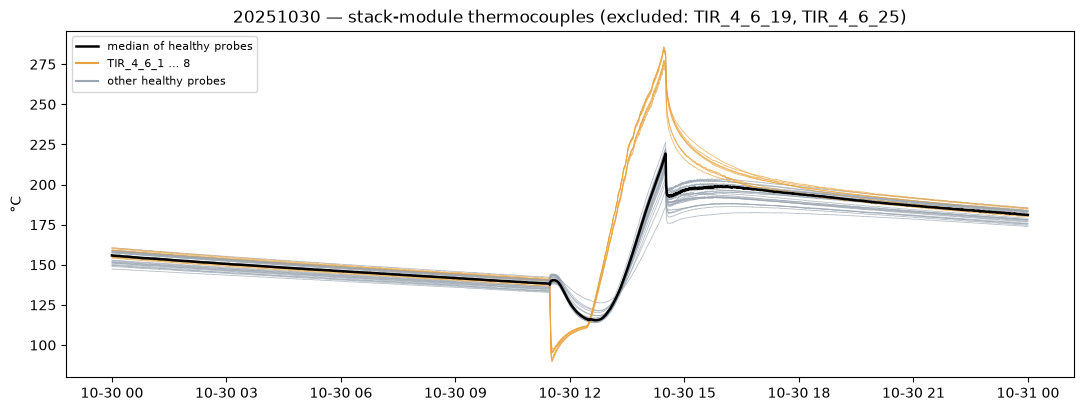

In [4]:
fig, ax = plt.subplots(figsize=(13, 4.5))
good = tc_stats.index[~tc_stats.excluded]
for c in good:
    hot = c in [f"TIR_4_6_{i}" for i in range(1, 9)]
    ax.plot(tc.index, tc[c], lw=0.6, color="#e8a33d" if hot else "#9aa5b1", alpha=0.7)
ax.plot(
    tc.index,
    tc[good].median(axis=1),
    color="k",
    lw=1.8,
    label="median of healthy probes",
)
ax.plot([], [], color="#e8a33d", label="TIR_4_6_1 … 8")
ax.plot([], [], color="#9aa5b1", label="other healthy probes")
ax.set_ylabel("°C")
ax.set_title(
    f"{DAY} — stack-module thermocouples (excluded: "
    f"{', '.join(tc_stats.index[tc_stats.excluded])})"
)
ax.legend(loc="upper left", fontsize=8)
plt.show()

## 3. Segmentation

`ops.segment()` loads the signals, applies the gates row by row, merges short blocks, applies the context rules and returns:

* `states`: one row per minute, with the signals plus `stage` and `operation`
* `segments`: one row per contiguous (stage, operation) block

In [5]:
states, segments = ops.segment(DAY)
states[
    [
        "T_stack_C",
        "dTdt_20min_C_per_h",
        "I_string_A",
        "P_EAPH_kW",
        "P_air_in",
        "stage",
        "operation",
    ]
].iloc[::120]

Excluded stack thermocouples: ['TIR_4_6_19', 'TIR_4_6_25']


,T_stack_C,dTdt_20min_C_per_h,I_string_A,P_EAPH_kW,P_air_in,stage,operation
Date Time,,,,,,,
2025-10-30 00:00:00,155.767500,NaN,0.0,0.005861,0.306013,Idle,"Natural cooling (heater off, no air)"
2025-10-30 02:00:00,152.248333,-1.570000,0.0,0.009030,0.310080,Idle,"Natural cooling (heater off, no air)"
2025-10-30 04:00:00,149.025833,-1.540000,0.0,0.013747,0.308860,Idle,"Natural cooling (heater off, no air)"
2025-10-30 06:00:00,146.035000,-1.480000,0.0,0.008438,0.283223,Idle,"Natural cooling (heater off, no air)"
2025-10-30 08:00:00,143.133333,-1.482500,0.0,0.014086,0.278550,Idle,"Natural cooling (heater off, no air)"
2025-10-30 10:00:00,140.248333,-1.512500,0.0,0.003894,0.243335,Idle,"Natural cooling (heater off, no air)"
2025-10-30 12:00:00,125.865833,-37.332500,0.0,0.000093,4.180627,Start-up,"Air flow start (purge, heater off)"
2025-10-30 14:00:00,184.714167,72.069722,0.0,17.133577,4.910432,Start-up,Heat-up (EAPH on)
2025-10-30 16:00:00,198.595000,-0.225000,0.0,0.005886,0.287500,Idle,Heat-up stopped - settling / natural cooling


In [6]:
segments[
    [
        "stage",
        "operation",
        "start",
        "end",
        "duration_min",
        "T_start_C",
        "T_end_C",
        "dTdt_mean_C_per_h",
        "I_max_A",
        "P_EAPH_mean_kW",
        "P_EAPH_max_kW",
    ]
]

,stage,operation,start,end,duration_min,T_start_C,T_end_C,dTdt_mean_C_per_h,I_max_A,P_EAPH_mean_kW,P_EAPH_max_kW
0,Idle,"Natural cooling (heater off, no air)",2025-10-30 00:00:00,2025-10-30 11:29:00,689,155.77,138.04,-1.60,0.0,0.01,0.03
1,Start-up,"Air flow start (purge, heater off)",2025-10-30 11:29:00,2025-10-30 12:27:00,58,139.48,116.30,-19.42,0.0,0.00,0.03
2,Start-up,Heat-up (EAPH on),2025-10-30 12:27:00,2025-10-30 14:31:00,124,116.09,215.53,38.63,0.0,12.24,18.45
3,Idle,Heat-up stopped - settling / natural cooling,2025-10-30 14:31:00,2025-10-30 16:10:00,99,199.14,198.50,-0.04,0.0,0.01,0.05
4,Idle,"Natural cooling (heater off, no air)",2025-10-30 16:10:00,2025-10-31 00:00:00,470,198.48,181.11,-2.22,0.0,0.01,0.05


## 4. Timeline

Panels from top to bottom:

1. Stack temperature (median TC) and air after the EAPH (`TIRC_2_06`).
2. EAPH power, stack power and string current.
3. **Anode-side gas flows** from the mass-flow controllers: N₂ `FIRC_13` and natural gas `FIRC_12` (left axis),
   H₂ `FIRC_15` (dashed, right axis; drawn on a 0–100 scale so the 60 ln/min line sits below the 1200 ln/min N₂ line
   instead of on top of it).
4. **Cathode air** `FIRC_111 + FIRC_112`.
5. Stage band.
6. **Gas band**: which supply was on each minute (column `phase`): *Natural gas* > *Forming gas (N₂ + H₂)* > *N₂ purge*
   > *Air only* > *Plant off*, thresholds N₂ > 100, H₂ > 5, NG > 20, air > 100 ln/min. Gaps of ≤ 10 min inside
   forming gas or natural gas are bridged.


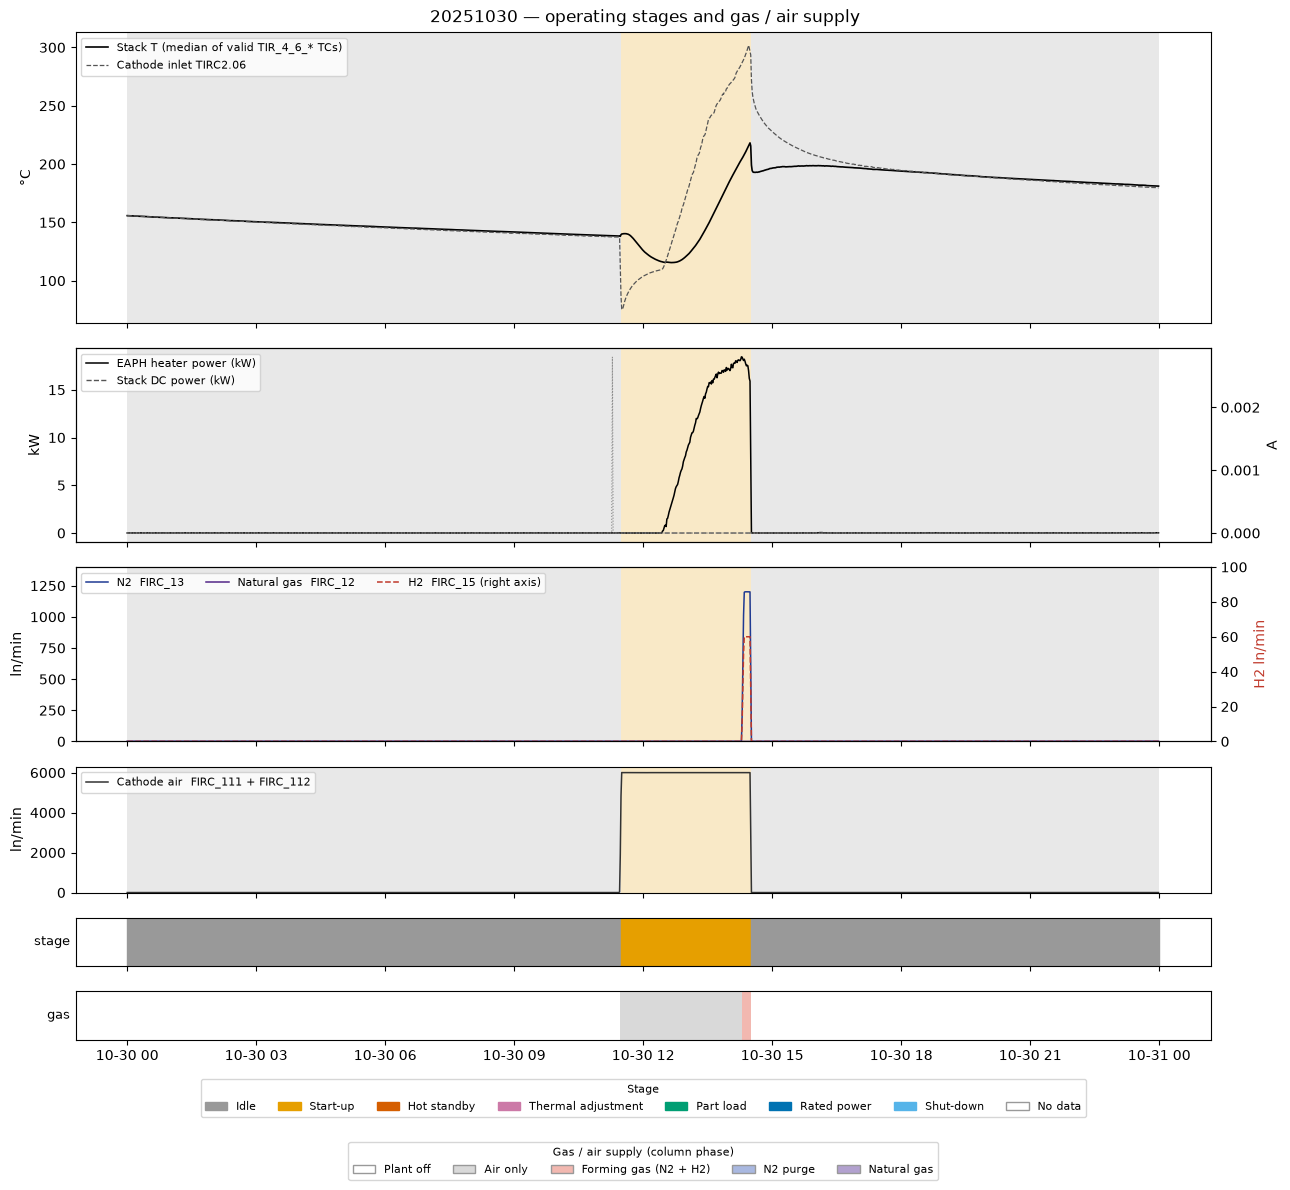

In [7]:
fig = ops.plot(DAY, states, segments)
plt.show()

## 5. Boundaries in detail

The stage boundaries are set by equipment events, not by the slow stack temperature. The window around noon shows the
three switching moments: air on at 11:29, heater on at ~12:27 (the ramp starts ~12:20 at low power), and air + heater off
together at 14:30–14:31. The two bottom panels show the gas and air flows in the same window: air (FIRC_111/112) goes on at 11:28, forming gas
(N₂ 1200 + H₂ 60 ln/min) only from 14:18, 12 min before the stop, and air and gas go off together at 14:30. No natural gas
flows on this day.


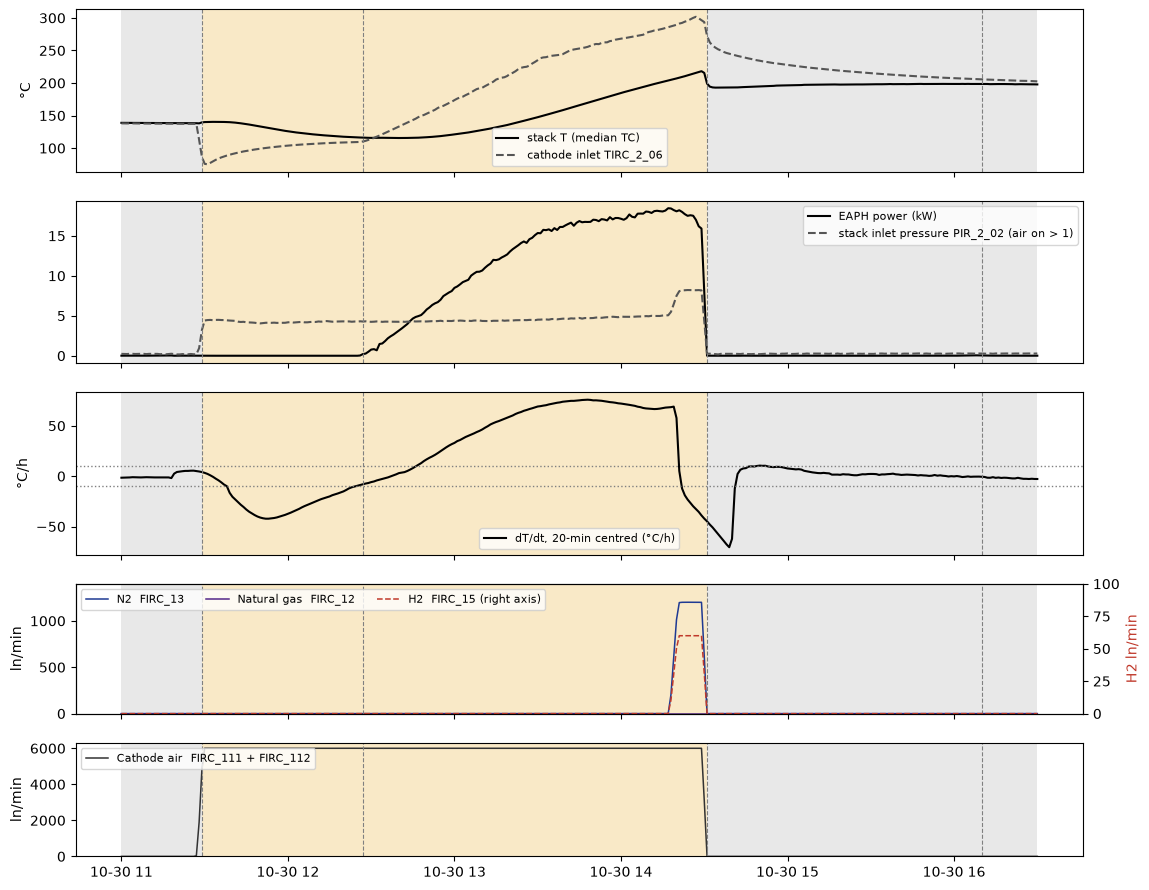

In [8]:
win = states.loc[
    f"{DAY[:4]}-{DAY[4:6]}-{DAY[6:]} 11:00" : f"{DAY[:4]}-{DAY[4:6]}-{DAY[6:]} 16:30"
]
fig, ax = plt.subplots(
    5,
    1,
    figsize=(13, 11),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 2, 2, 1.6, 1.4]},
)
ax[0].plot(win.index, win.T_stack_C, "k", label="stack T (median TC)")
ax[0].plot(
    win.index,
    win.T_cathode_in_C,
    color="#555555",
    ls="--",
    label="cathode inlet TIRC_2_06",
)
ax[0].set_ylabel("°C")
ax[0].legend(fontsize=8)
ax[1].plot(win.index, win.P_EAPH_kW, color="k", label="EAPH power (kW)")
ax[1].plot(
    win.index,
    win.P_air_in,
    color="#555555",
    ls="--",
    label="stack inlet pressure PIR_2_02 (air on > 1)",
)
ax[1].legend(fontsize=8)
ax[2].plot(
    win.index, win.dTdt_20min_C_per_h, color="k", label="dT/dt, 20-min centred (°C/h)"
)
for y in (ops.DTDT_HEAT, -ops.DTDT_HEAT):
    ax[2].axhline(y, color="grey", ls=":", lw=1)
ax[2].set_ylabel("°C/h")
ax[2].legend(fontsize=8)
ops.plot_flows(win, ax[3], ax[4])
for _, r in segments.iterrows():
    for a in ax:
        a.axvspan(
            max(r.start, win.index[0]),
            min(r.end, win.index[-1]),
            color=ops.STAGE_COLORS[r.stage],
            alpha=ops.STAGE_TINT,
            lw=0,
        )
    if win.index[0] < r.start < win.index[-1]:
        for a in ax:
            a.axvline(r.start, color="grey", lw=0.8, ls="--")
plt.show()

## 6. Time per stage and per operation

In [9]:
summary = (
    segments.groupby(["stage", "operation"], sort=False)["duration_min"]
    .sum()
    .to_frame("minutes")
)
summary["share_%"] = (100 * summary.minutes / summary.minutes.sum()).round(1)
display(summary)
display(
    states.stage.value_counts()
    .rename("minutes")
    .to_frame()
    .assign(**{"share_%": lambda d: (100 * d.minutes / d.minutes.sum()).round(1)})
)

minutes  share_%
stage    operation                                                     
Idle     Natural cooling (heater off, no air)             1159     80.5
Start-up Air flow start (purge, heater off)                 58      4.0
         Heat-up (EAPH on)                                 124      8.6
Idle     Heat-up stopped - settling / natural cooling       99      6.9

,minutes,share_%
stage,,
Idle,1258,87.4
Start-up,182,12.6


## 7. Checks against the limits in the operational-modes file

In [10]:
heat = states[states.operation == "Heat-up (EAPH on)"]
pd.Series(
    {
        "max heat-up rate, 1 h centred (°C/h)  [limit 120]": heat.dTdt_C_per_h.max(),
        "max stack T reached (°C)  [Hot standby ≈ 575–600]": states.T_stack_C.max(),
        "max EAPH power (kW)  [rated 40]": states.P_EAPH_kW.max(),
        "max string current (A)  [rated 30]": states.I_string_A.max(),
    }
).round(1).to_frame("value")

,value
"max heat-up rate, 1 h centred (°C/h) [limit 120]",71.8
max stack T reached (°C) [Hot standby ≈ 575–600],218.2
max EAPH power (kW) [rated 40],18.5
max string current (A) [rated 30],0.0


## 8. Save results

In [11]:
ops.OUT.mkdir(parents=True, exist_ok=True)
states.to_csv(ops.OUT / f"{DAY}_states_1min.csv", float_format="%.3f")
segments.to_csv(ops.OUT / f"{DAY}_segments.csv", index=False)
ops.plot(DAY, states, segments, ops.OUT / f"{DAY}_states.png")
sorted(p.name for p in ops.OUT.glob(f"{DAY}_*"))

['20251030_segments.csv', '20251030_states.png', '20251030_states_1min.csv']

## 9. Number of stages performed on each day (all 39 day files)

The same segmentation runs on every day file. For each day and stage it counts **episodes**: an episode is a
contiguous run of minutes in that stage. Operations inside a stage (e.g. heat-up → pause → heat-up) do not add episodes.
Logger gaps (`No data`) are skipped, so a stage interrupted only by a gap counts once.

Because each file covers one calendar day, a stage that runs across midnight shows up on both days. Section 9.2 therefore
also counts **new starts**: an episode that merely continues from the end of the previous calendar day is not counted again.

In [12]:
import contextlib
import io

log = io.StringIO()
with contextlib.redirect_stdout(log):  # segment() prints excluded thermocouples per day
    all_days = ops.segment_all()
print(f"{len(all_days)} day files segmented")
print(
    "Days with excluded stack thermocouples:",
    sum("Excluded" in line for line in log.getvalue().splitlines()),
)

39 day files segmented
Days with excluded stack thermocouples: 39


### 9.1 Stage episodes per day

In [13]:
counts = pd.DataFrame({d: ops.count_episodes(s) for d, (s, _) in all_days.items()}).T
counts.index = pd.to_datetime(counts.index, format="%Y%m%d").date
counts.index.name = "day"
counts["total"] = counts.sum(axis=1)
counts.loc["TOTAL"] = counts.sum()
counts.style.background_gradient(
    cmap="Oranges", subset=(counts.index[:-1], ops.STAGES)
).format("{:d}")

stage,Idle,Start-up,Hot standby,Thermal adjustment,Part load,Rated power,Shut-down,total
day,,,,,,,,
2025-10-30,2,1,0,0,0,0,0,3
2025-11-13,0,1,0,0,0,0,2,3
2025-11-14,0,0,0,0,0,0,1,1
2025-11-15,0,0,0,0,0,0,1,1
2025-11-16,0,0,0,0,0,0,1,1
2025-11-17,0,0,0,0,0,0,1,1
2025-11-18,0,0,0,0,0,0,1,1
2026-01-30,0,1,0,0,0,0,2,3
2026-01-31,0,1,2,1,0,0,1,5


### 9.2 New starts per day (episodes continued from the previous day not counted twice)

In [14]:
def new_starts(all_days):
    rows, prev_day, prev_last = {}, None, None
    for d, (s, _) in all_days.items():
        c = ops.count_episodes(s)
        st = s["stage"][s["stage"] != "No data"]
        day = pd.Timestamp(d)
        if (
            prev_day is not None
            and day - prev_day == pd.Timedelta("1D")
            and len(st)
            and st.iloc[0] == prev_last
        ):
            c[st.iloc[0]] -= 1  # continues yesterday's last episode
        rows[day.date()] = c
        prev_day, prev_last = day, (st.iloc[-1] if len(st) else None)
    return pd.DataFrame(rows).T


starts = new_starts(all_days)
starts.index.name = "day"
starts["total"] = starts.sum(axis=1)
starts.loc["TOTAL"] = starts.sum()
starts.style.background_gradient(
    cmap="Blues", subset=(starts.index[:-1], ops.STAGES)
).format("{:d}")

stage,Idle,Start-up,Hot standby,Thermal adjustment,Part load,Rated power,Shut-down,total
day,,,,,,,,
2025-10-30,2,1,0,0,0,0,0,3
2025-11-13,0,1,0,0,0,0,2,3
2025-11-14,0,0,0,0,0,0,0,0
2025-11-15,0,0,0,0,0,0,0,0
2025-11-16,0,0,0,0,0,0,0,0
2025-11-17,0,0,0,0,0,0,0,0
2025-11-18,0,0,0,0,0,0,0,0
2026-01-30,0,1,0,0,0,0,2,3
2026-01-31,0,1,2,1,0,0,0,4


### 9.3 Minutes in each stage per day

In [15]:
minutes = pd.DataFrame({d: ops.stage_minutes(s) for d, (s, _) in all_days.items()}).T
minutes.index = pd.to_datetime(minutes.index, format="%Y%m%d").date
minutes.index.name = "day"
minutes.loc["TOTAL"] = minutes.sum()
minutes

stage,Idle,Start-up,Hot standby,Thermal adjustment,Part load,Rated power,Shut-down,No data
day,,,,,,,,
2025-10-30,1258,182,0,0,0,0,0,0
2025-11-13,0,645,0,0,0,0,795,0
2025-11-14,0,0,0,0,0,0,1440,0
2025-11-15,0,0,0,0,0,0,1440,0
2025-11-16,0,0,0,0,0,0,1440,0
2025-11-17,0,0,0,0,0,0,1440,0
2025-11-18,0,0,0,0,0,0,1440,0
2026-01-30,0,540,0,0,0,0,900,0
2026-01-31,0,578,170,203,0,0,489,0


### 9.4 All days at a glance

One row per day file, 00:00 to 24:00, coloured by stage. White = logger gap. The number on the right is the total
number of stage episodes that day.

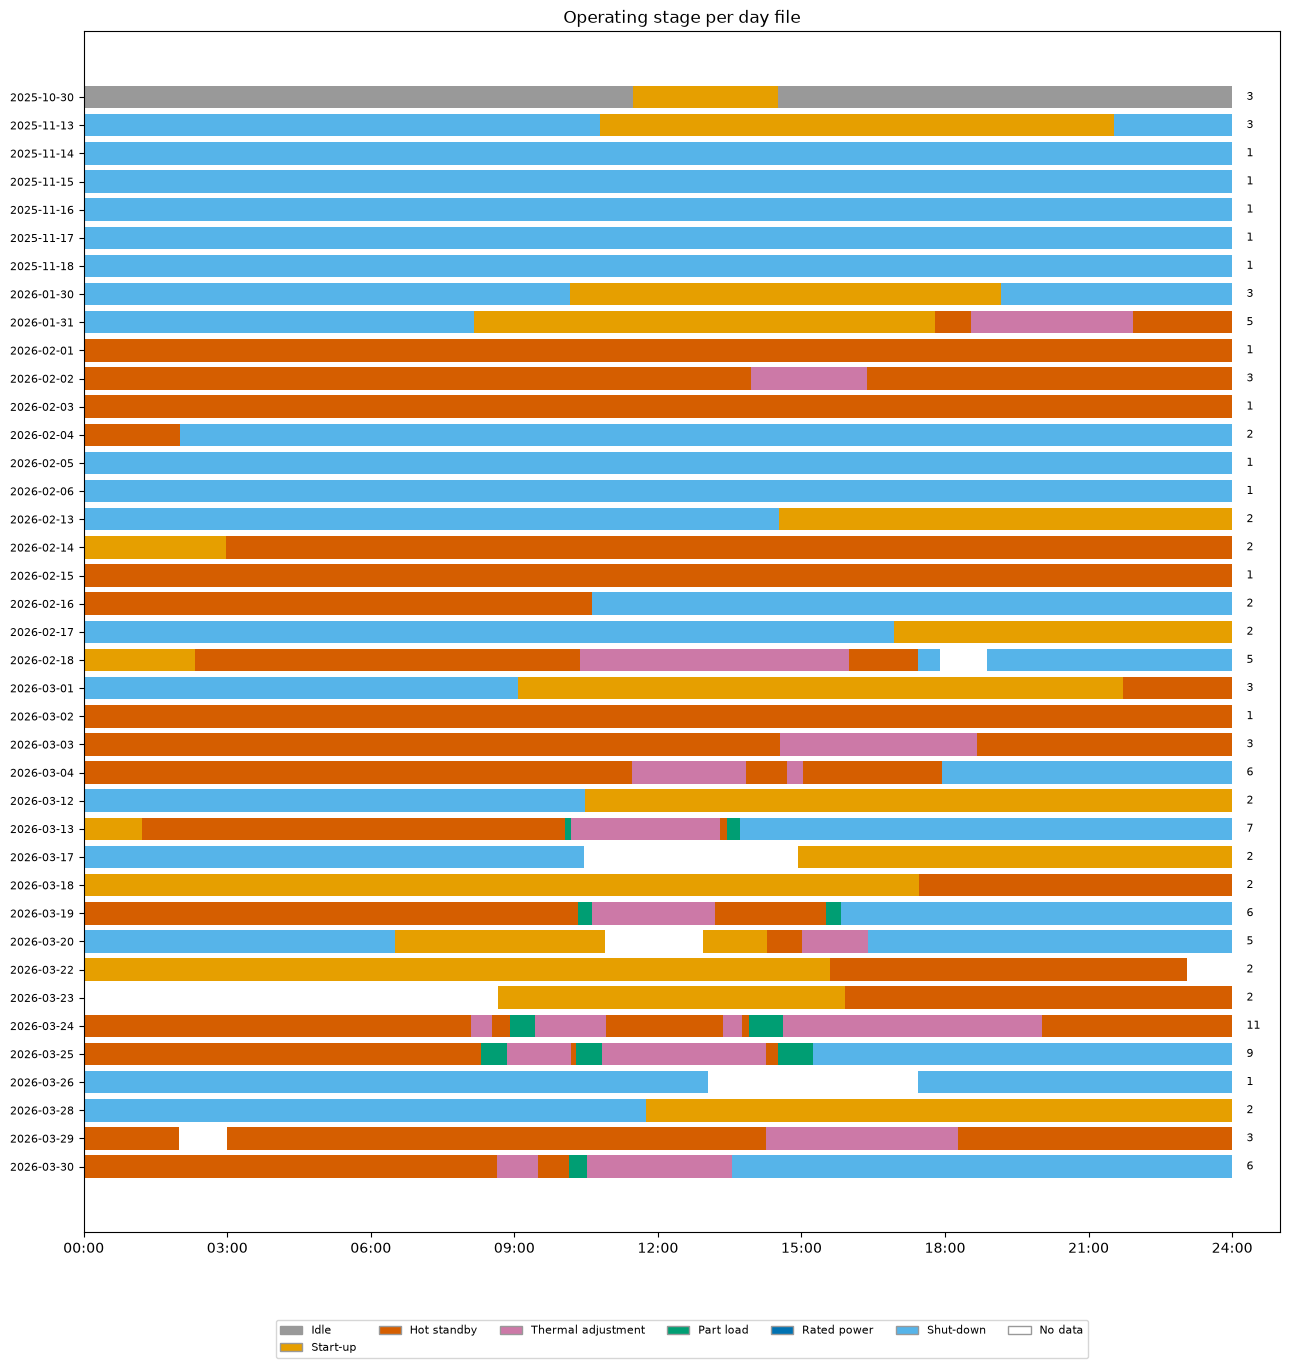

In [16]:
import matplotlib.dates as mdates
import numpy as np

colors = {**ops.STAGE_COLORS, "No data": "#ffffff"}
fig, ax = plt.subplots(figsize=(13, 0.32 * len(all_days) + 1.2))
for row, (d, (s, seg)) in enumerate(all_days.items()):
    base = pd.Timestamp(d)
    for r in seg.itertuples():
        x0 = (r.start - base) / pd.Timedelta("1h")
        w = (r.end - r.start) / pd.Timedelta("1h")
        ax.barh(row, w, left=x0, height=0.8, color=colors[r.stage], edgecolor="none")
    ax.text(24.3, row, int(ops.count_episodes(s).sum()), va="center", fontsize=8)
ax.set_yticks(
    range(len(all_days)),
    [pd.Timestamp(d).strftime("%Y-%m-%d") for d in all_days],
    fontsize=8,
)
ax.invert_yaxis()
ax.set_xlim(0, 25)
ax.set_xticks(range(0, 25, 3), [f"{h:02d}:00" for h in range(0, 25, 3)])
ax.legend(
    [plt.Rectangle((0, 0), 1, 1, color=c, ec="#999") for c in colors.values()],
    colors.keys(),
    ncol=7,
    fontsize=8,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.03 - 1.5 / len(all_days)),
)
ax.set_title("Operating stage per day file")
plt.tight_layout()
plt.show()

### 9.4b Stage-deciding sensors, stages and gas flows per stretch of consecutive days, with gas overlaps labelled

The 39 day files form **9 stretches of consecutive days** (gaps between them are days without a file). Each stretch gets
one plot on a clock-time axis (thin vertical line = midnight). From top to bottom:

**Sensors that decide the stage** (section 2), shaded by stage, gate thresholds as dotted lines:

1. **Temperature**: stack T, the median of the healthy `TIR_4_6_*` thermocouples (the signal the stage is decided on),
   cathode inlet `TIRC_2_06`, and the ambient proxy + 30 K (below it with the plant off = Shut-down, at ambient).
   Dotted lines at 450 °C (Hot standby lower bound) and 550 °C (below = low-temperature hold).
2. **dT/dt** of stack T, 20-min centred: ±10 °C/h (dashed) separates warming / cooling from steady, ±5 °C/h
   (dotted) is the steady band for Hot standby.
3. **EAPH heater power** `EIRC_2_01` (on > 0.2 kW) and **string current** from the PLC monitor `EIRC41…45`
   (green, right axis; load ≥ 1 A per string).
4. **Stack inlet pressure** `PIR_2_02`: air on > 1.

Logger gaps leave breaks in the lines.

**Stage and gas lanes:**

* **Stage**: operating stage, same colours as 9.4.
* **Air, POx air, N₂, H₂**: one lane per gas showing the measured flow. The lane runs from 0 at its bottom to the
  full scale printed at its right edge (the same scale on every figure); the dotted line is the "on" threshold
  (air > 100, POx air > 20, N₂ > 100, H₂ > 5 ln/min). POx air `FIRC_12` is the reformer air and only flows with natural gas.
* **Natural gas** `FIRC_14`: filled wherever it reads above 20 ln/min. Flows are taken from the **10 s data**, so short events are not
  averaged away. Each gas is drawn on its own, so overlaps stay visible (the `phase` column keeps only one supply per minute).
* **Gas overlap**: wherever **two or more anode gases** (N₂, H₂, natural gas) flow at the same time. Air is on the
  cathode side and does not mix with them, so air running alongside is not counted as an overlap.
  * **N₂ + H₂** (salmon) is the forming gas, mixed on purpose. Wide blocks are labelled with the stages they cover.
  * **NG + N₂ + H₂** (red ▼) are short handovers of 10–140 s when natural gas is switched in. Each is labelled
    with its time, length and stage. Handovers close together share one label, one line each.

Stage abbreviations: HS Hot standby · SD Shut-down · SU Start-up · TA Thermal adjustment · PL Part load · – No data.
The two tables after the plots give the overlap minutes per stage and every natural-gas handover.


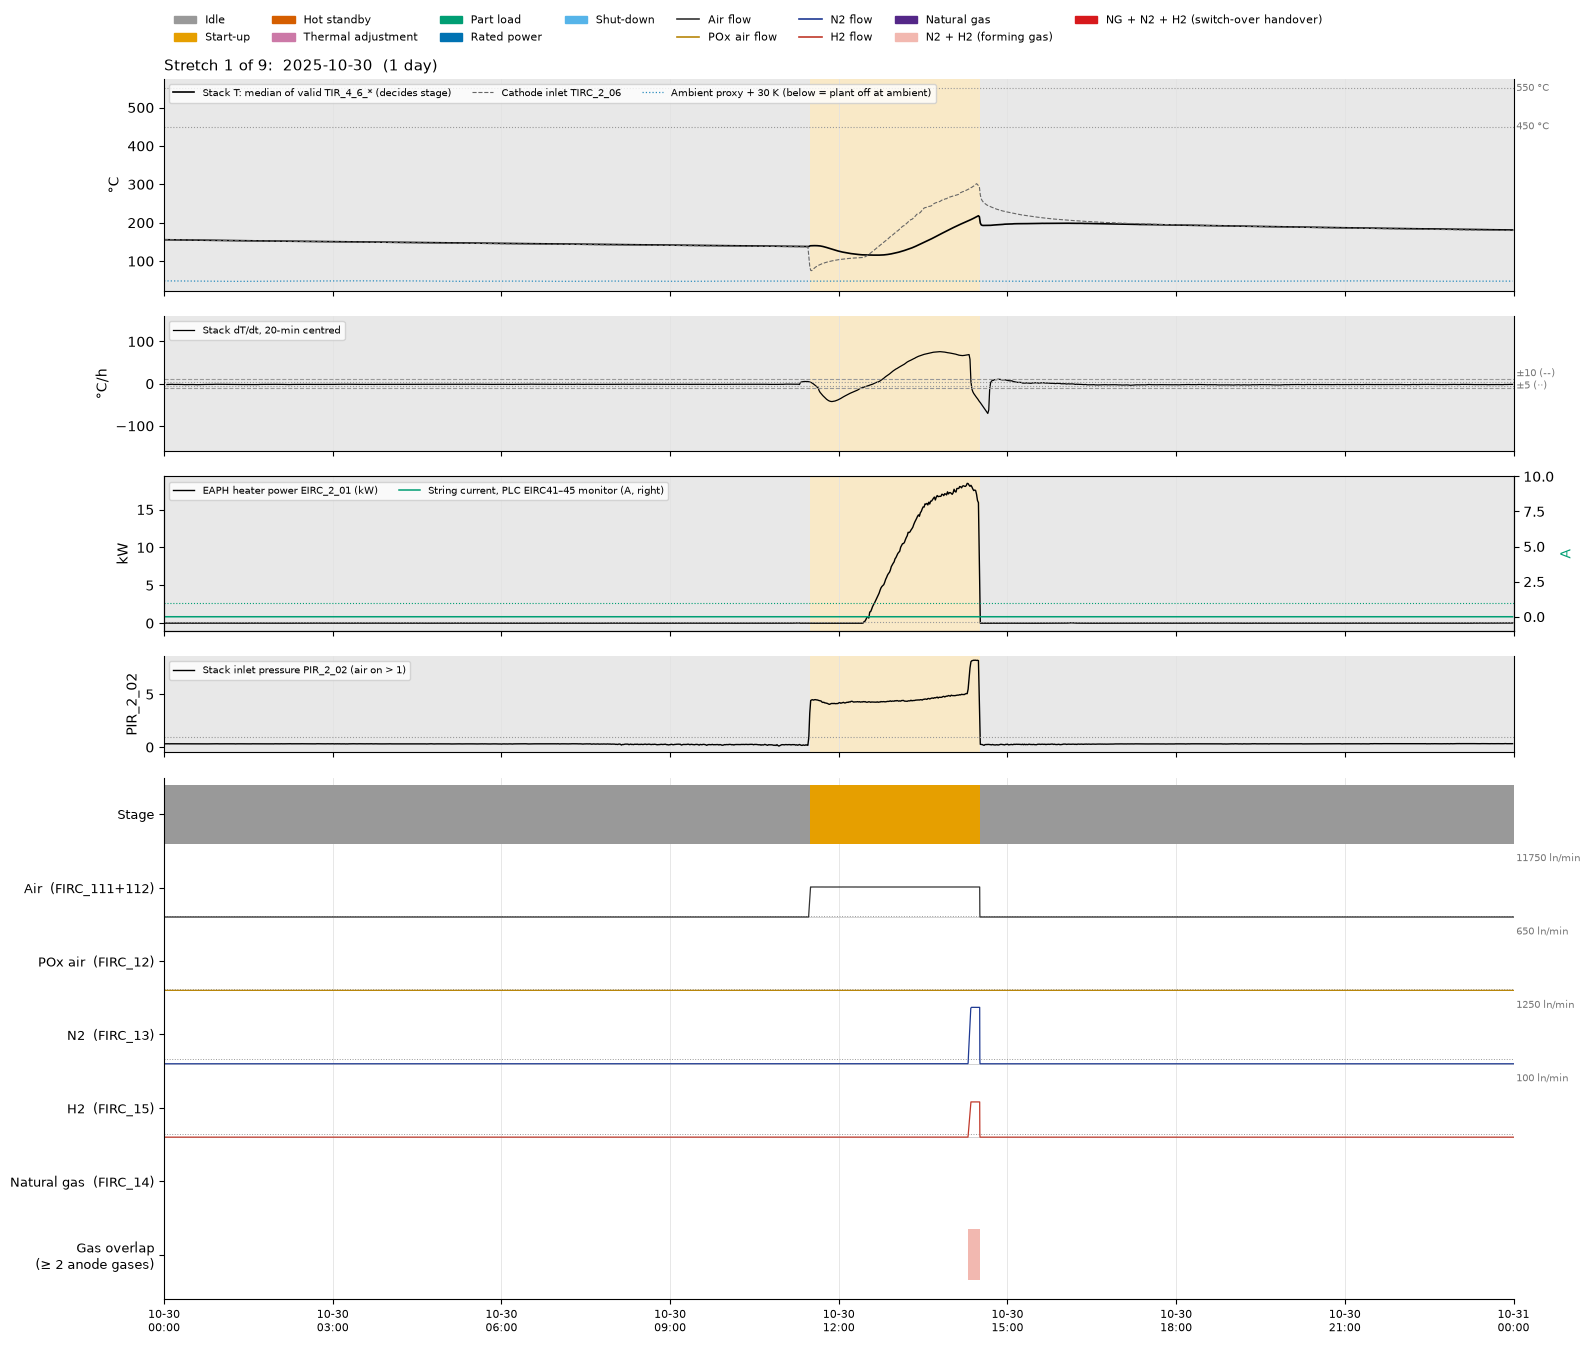

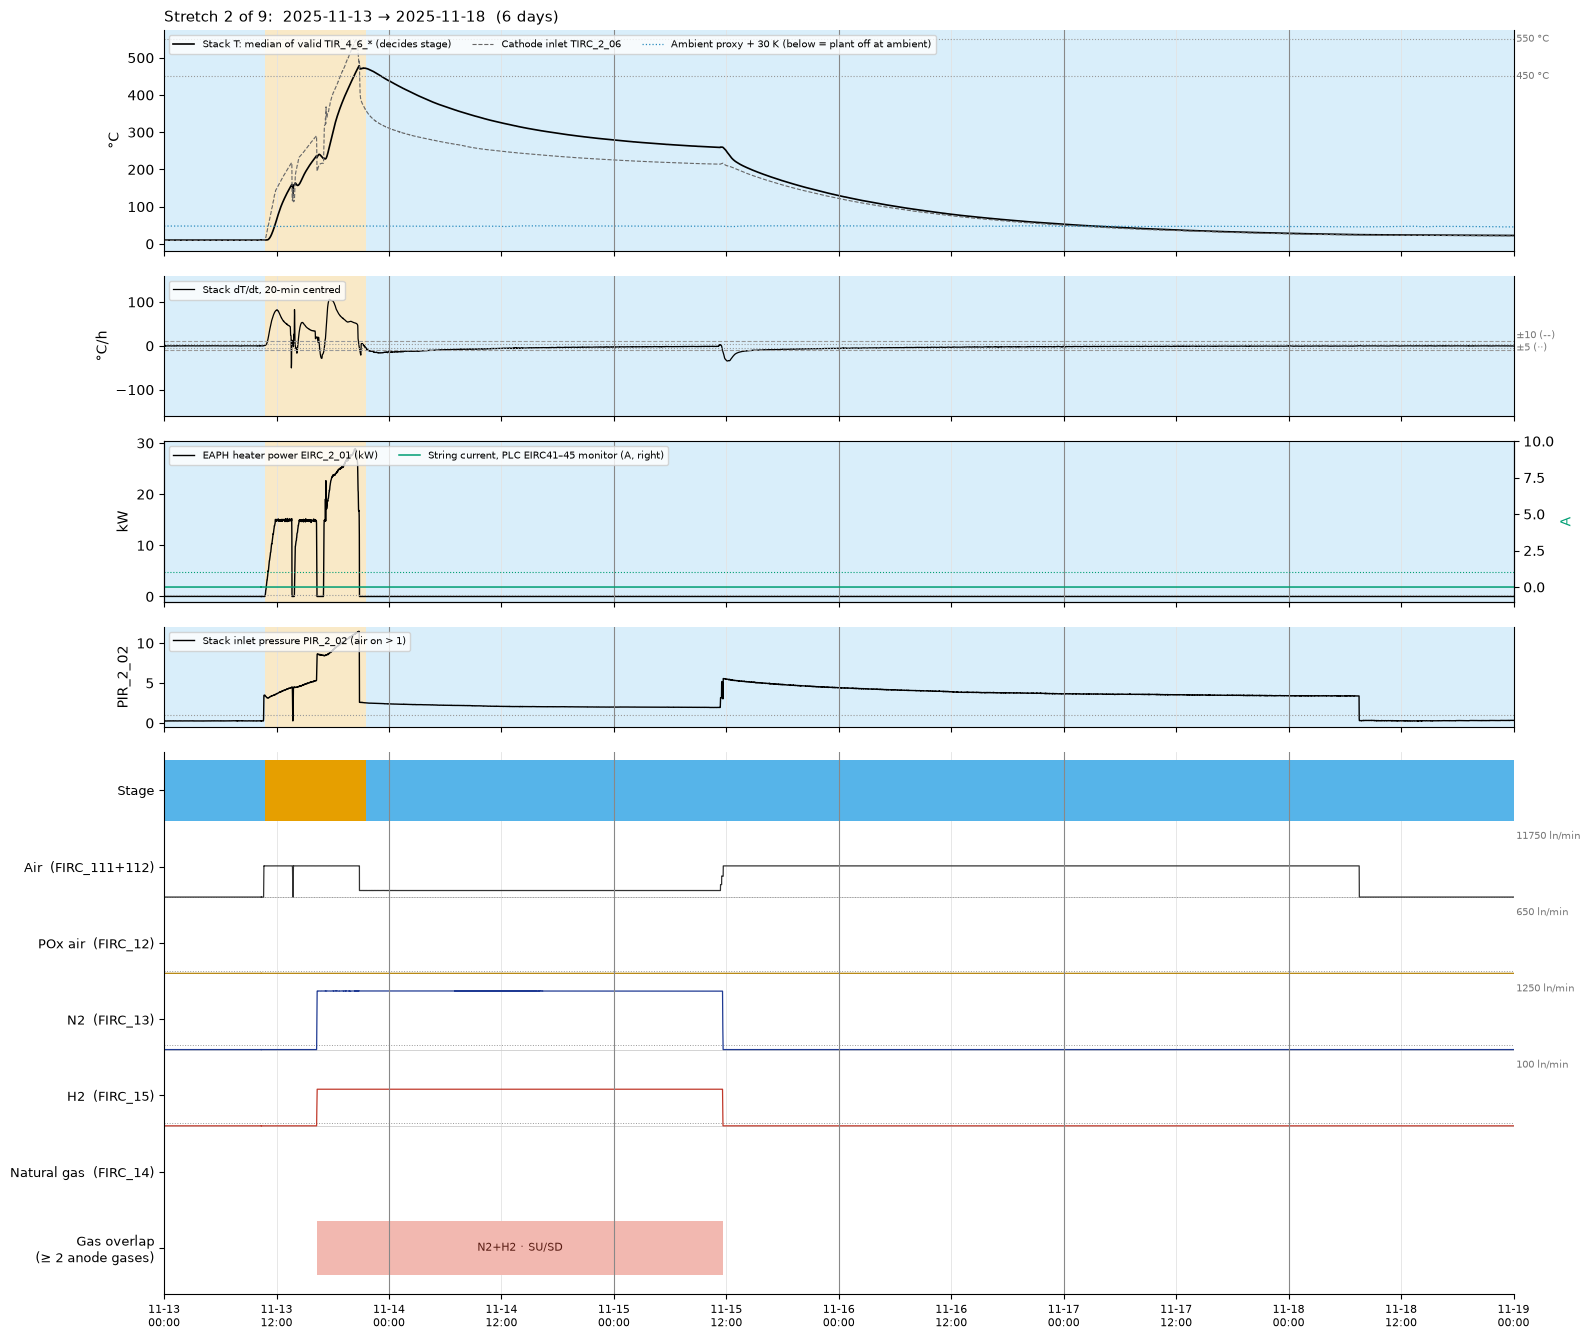

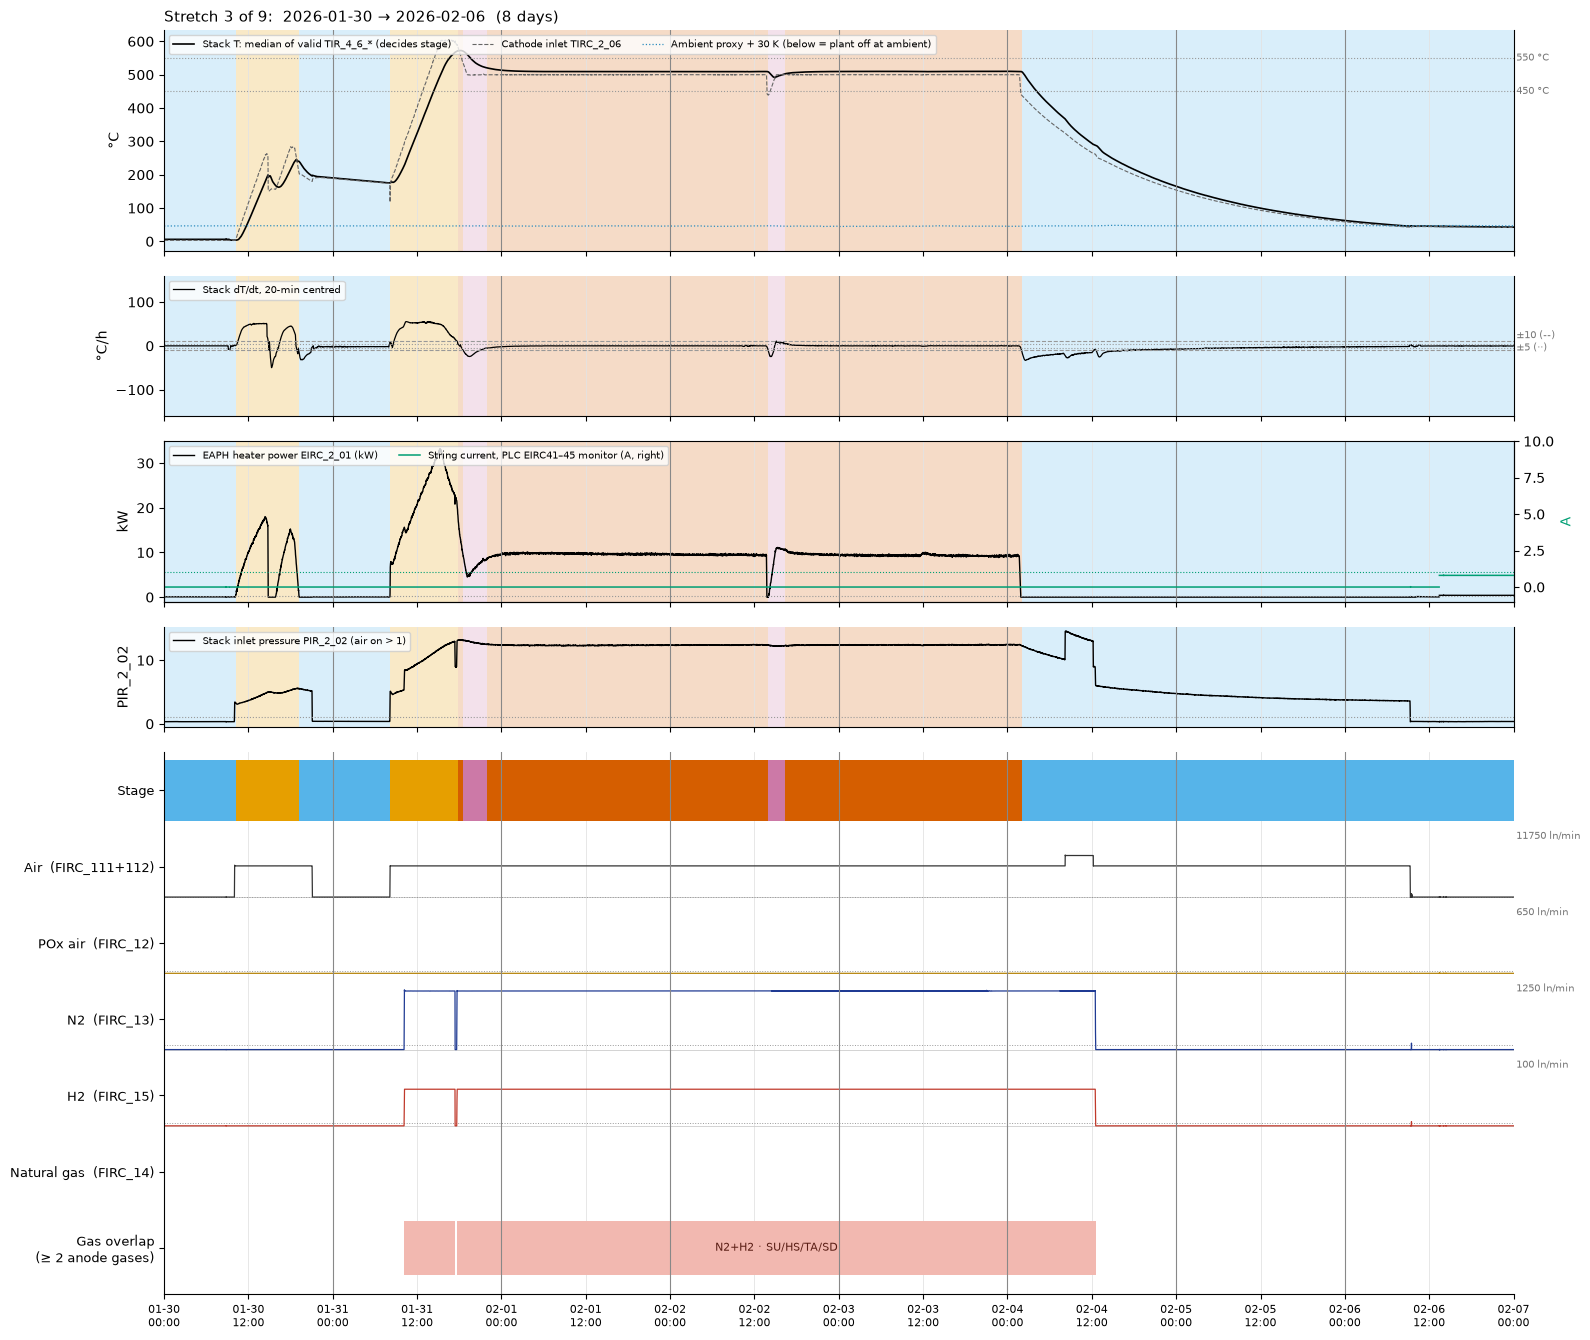

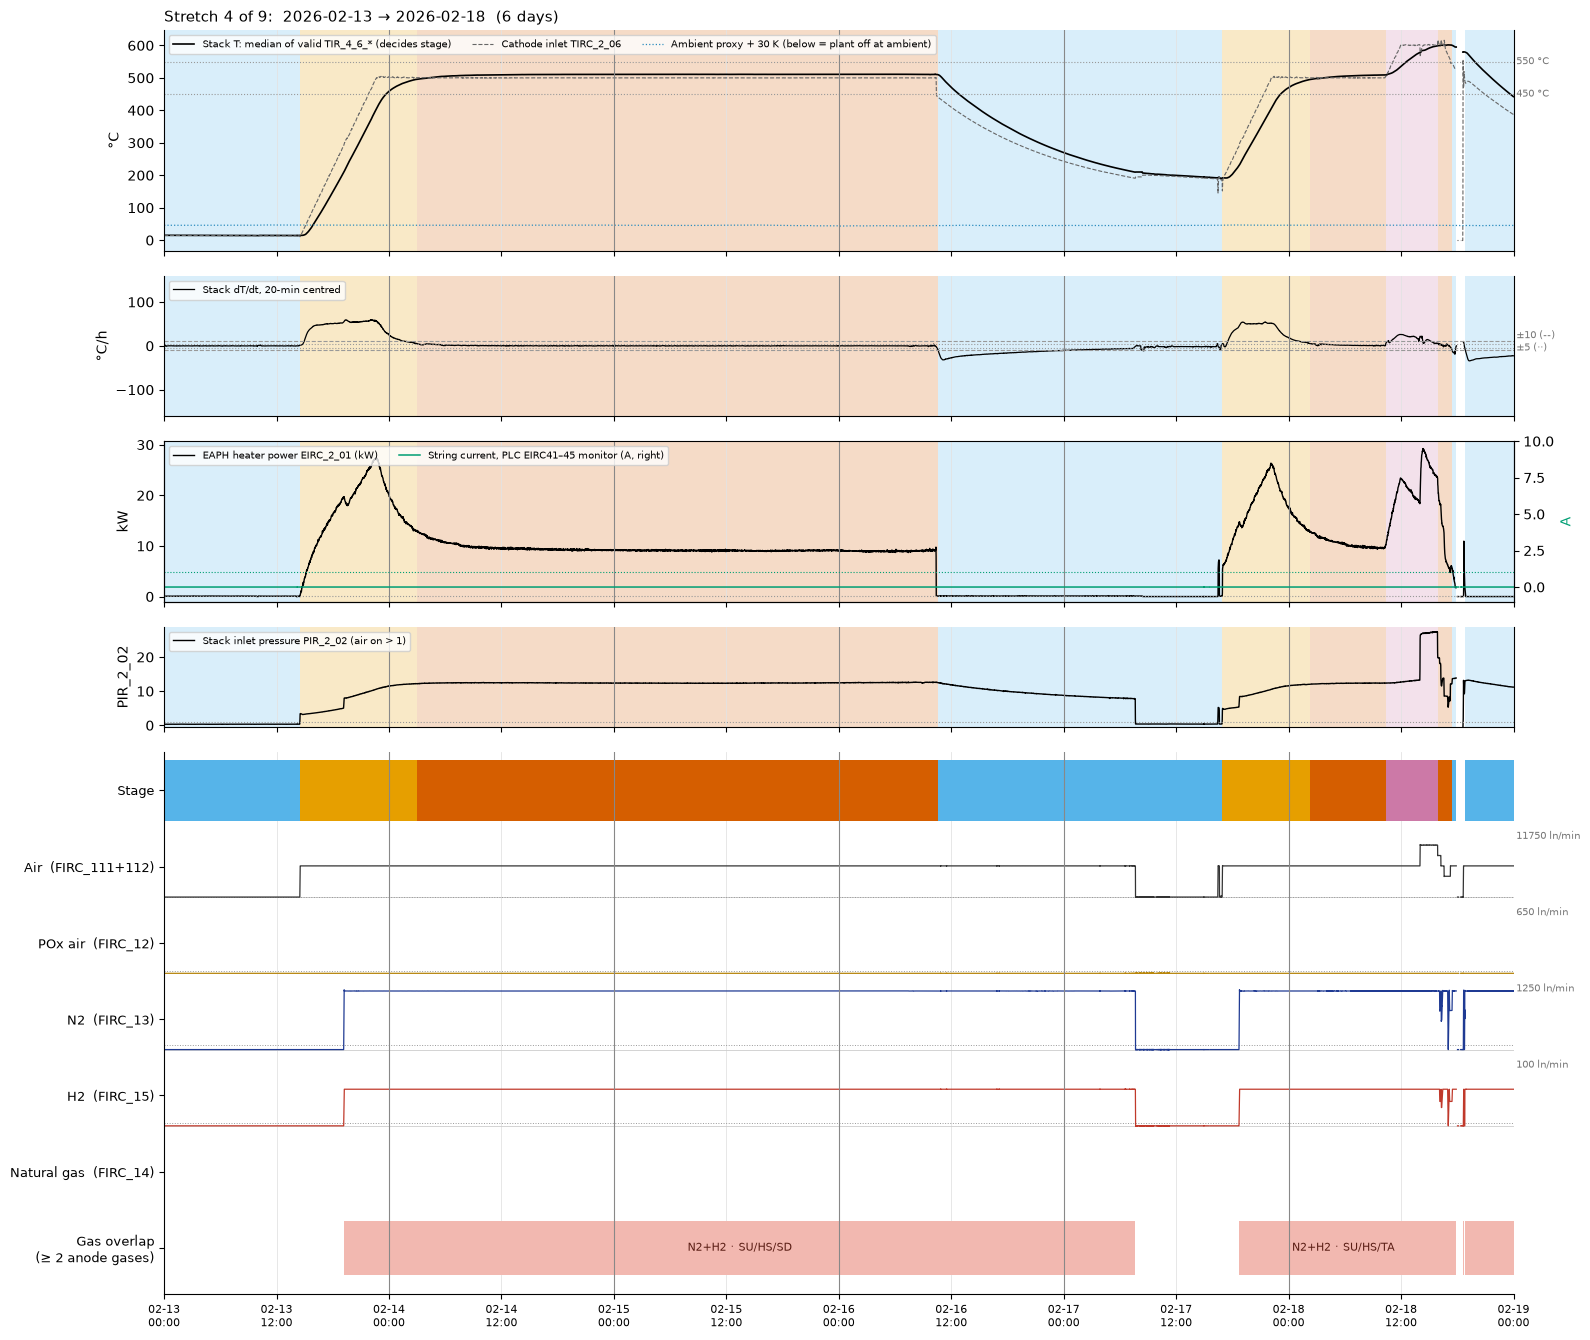

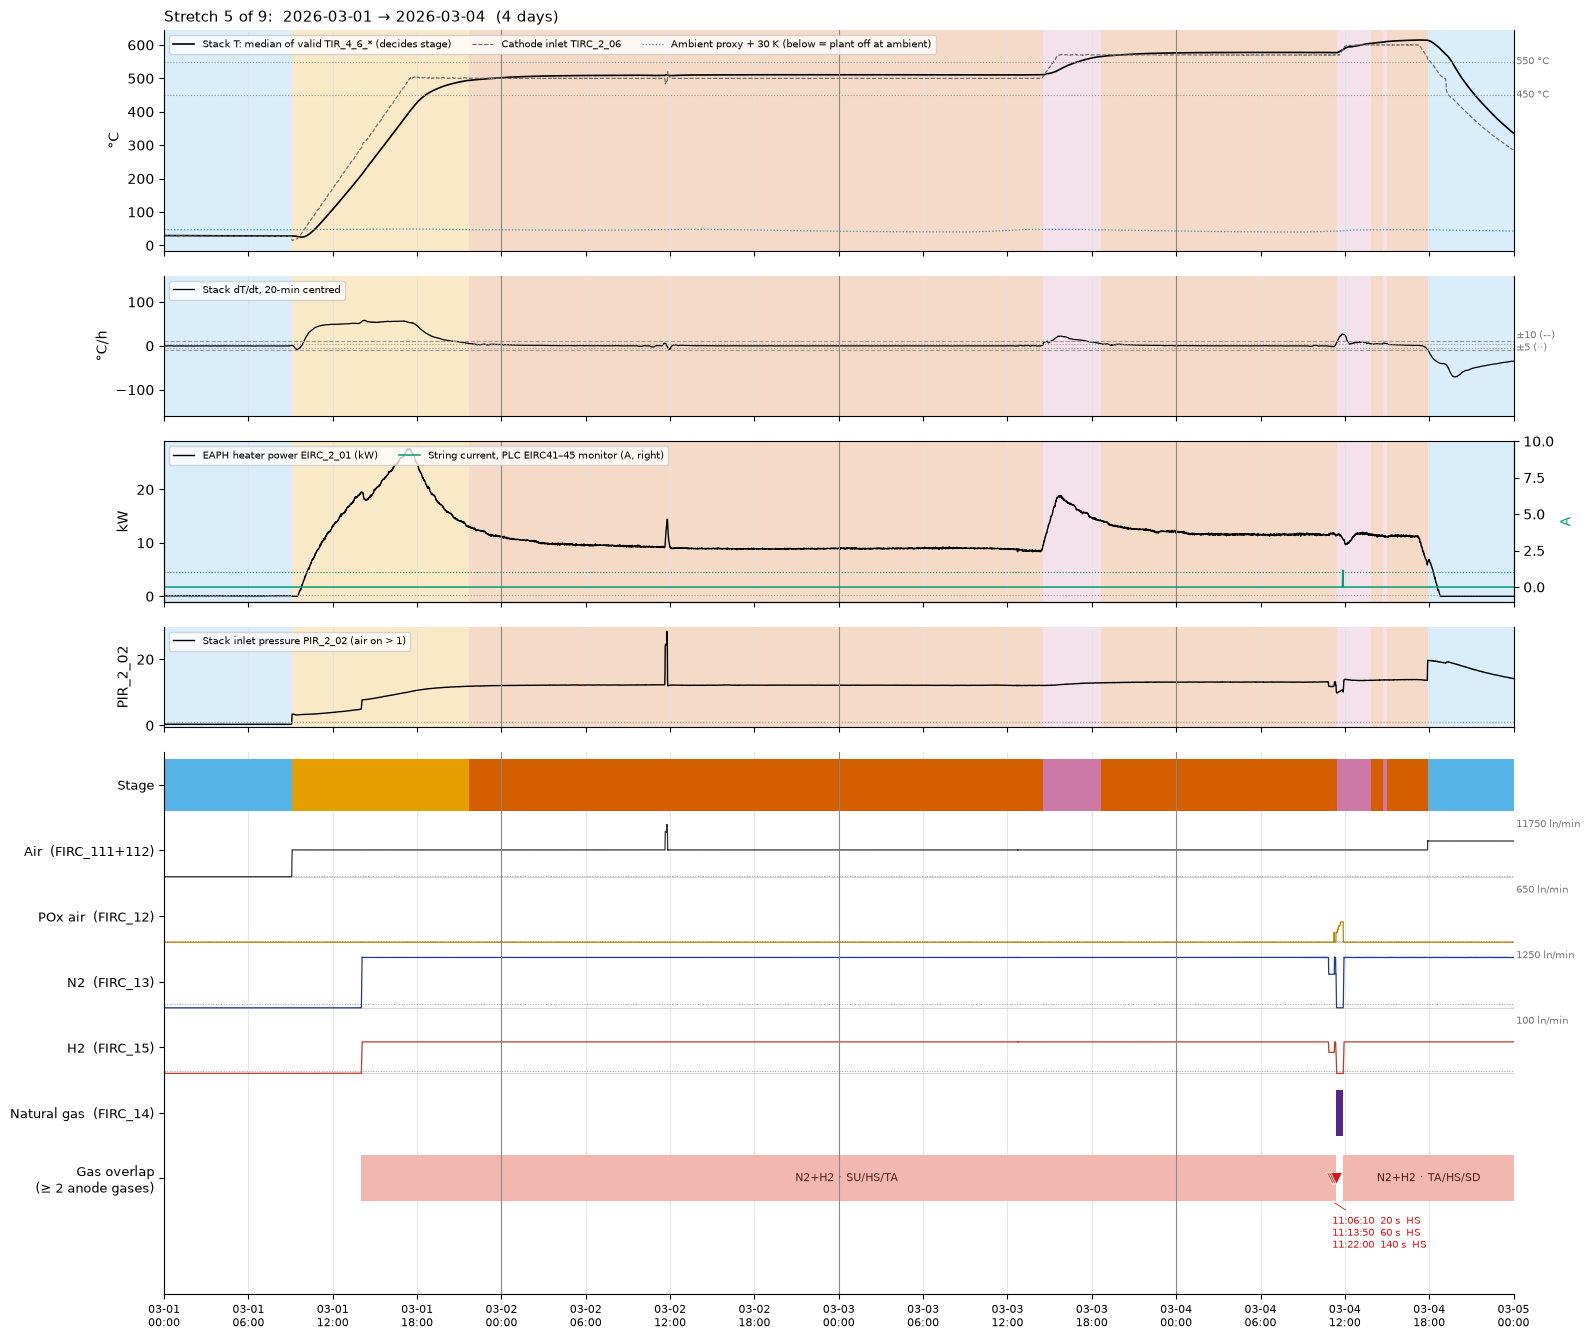

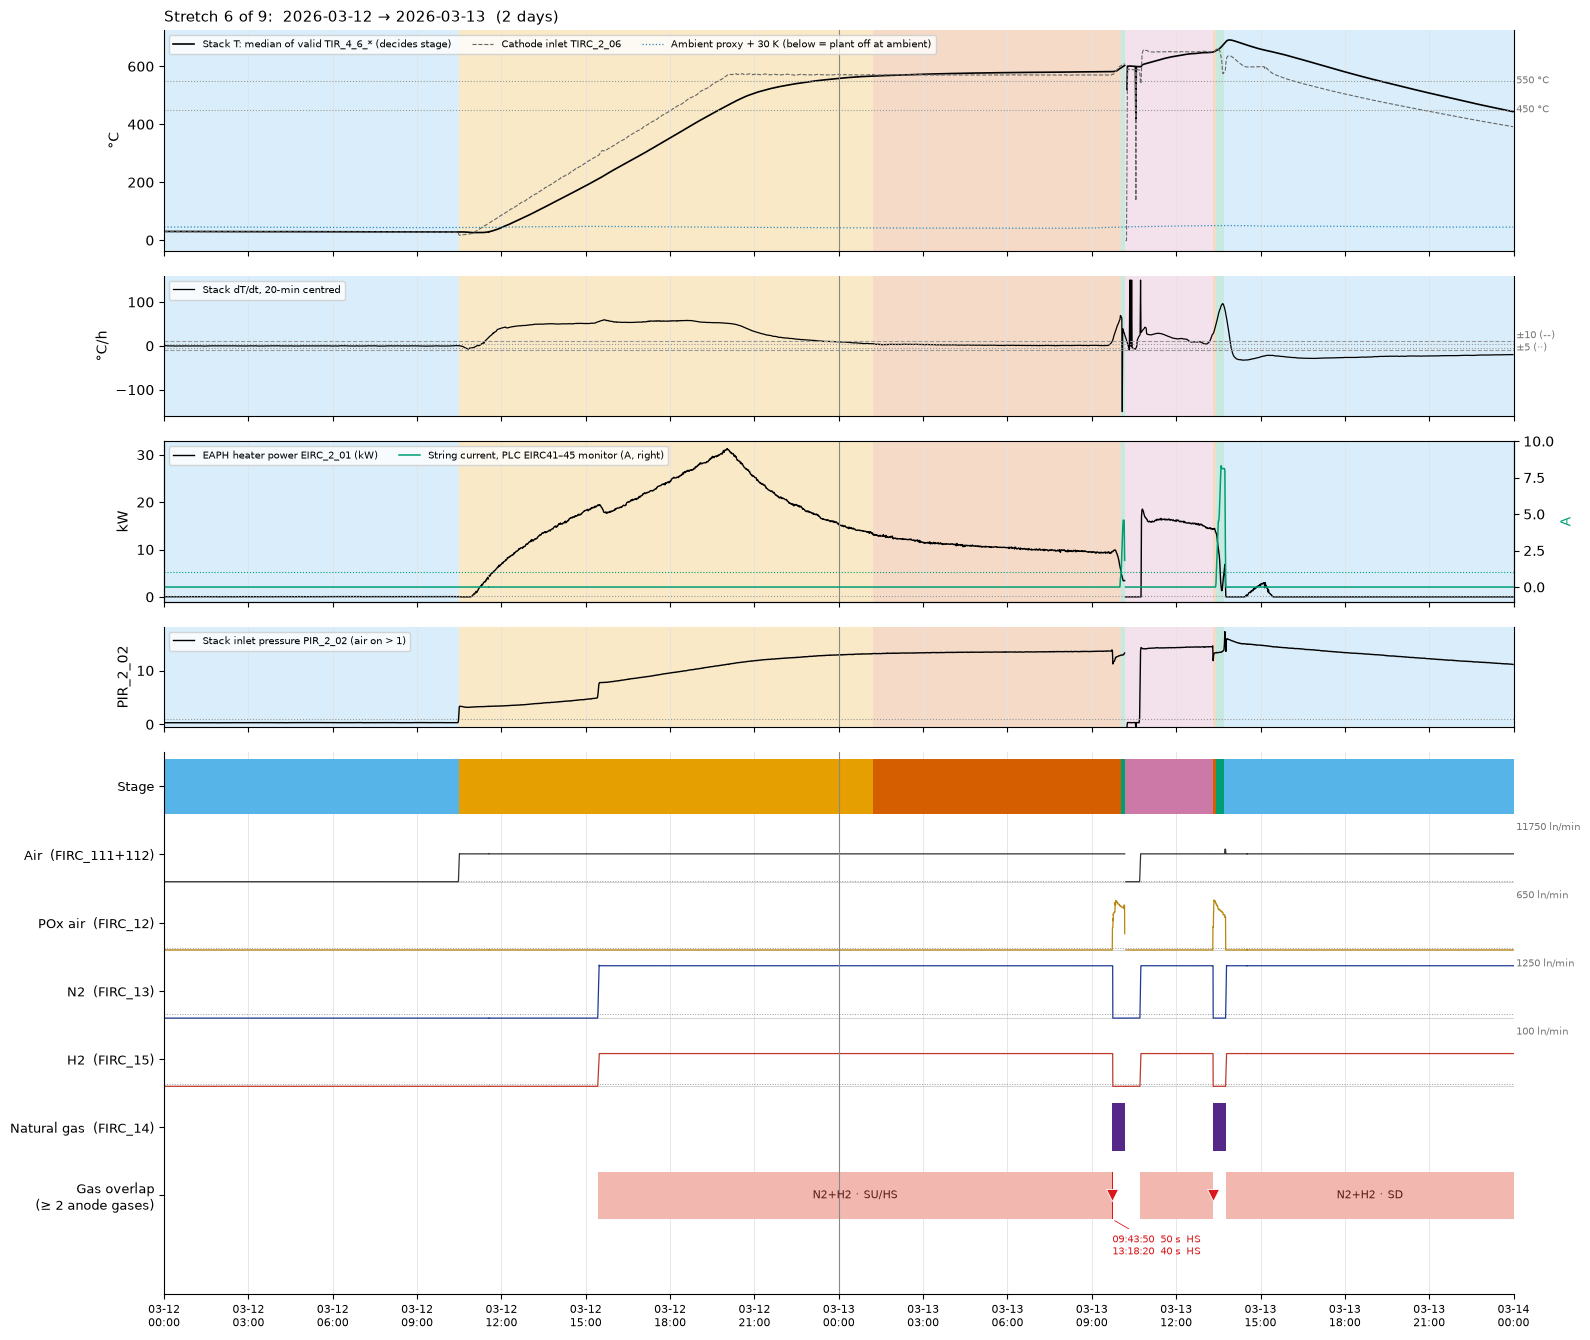

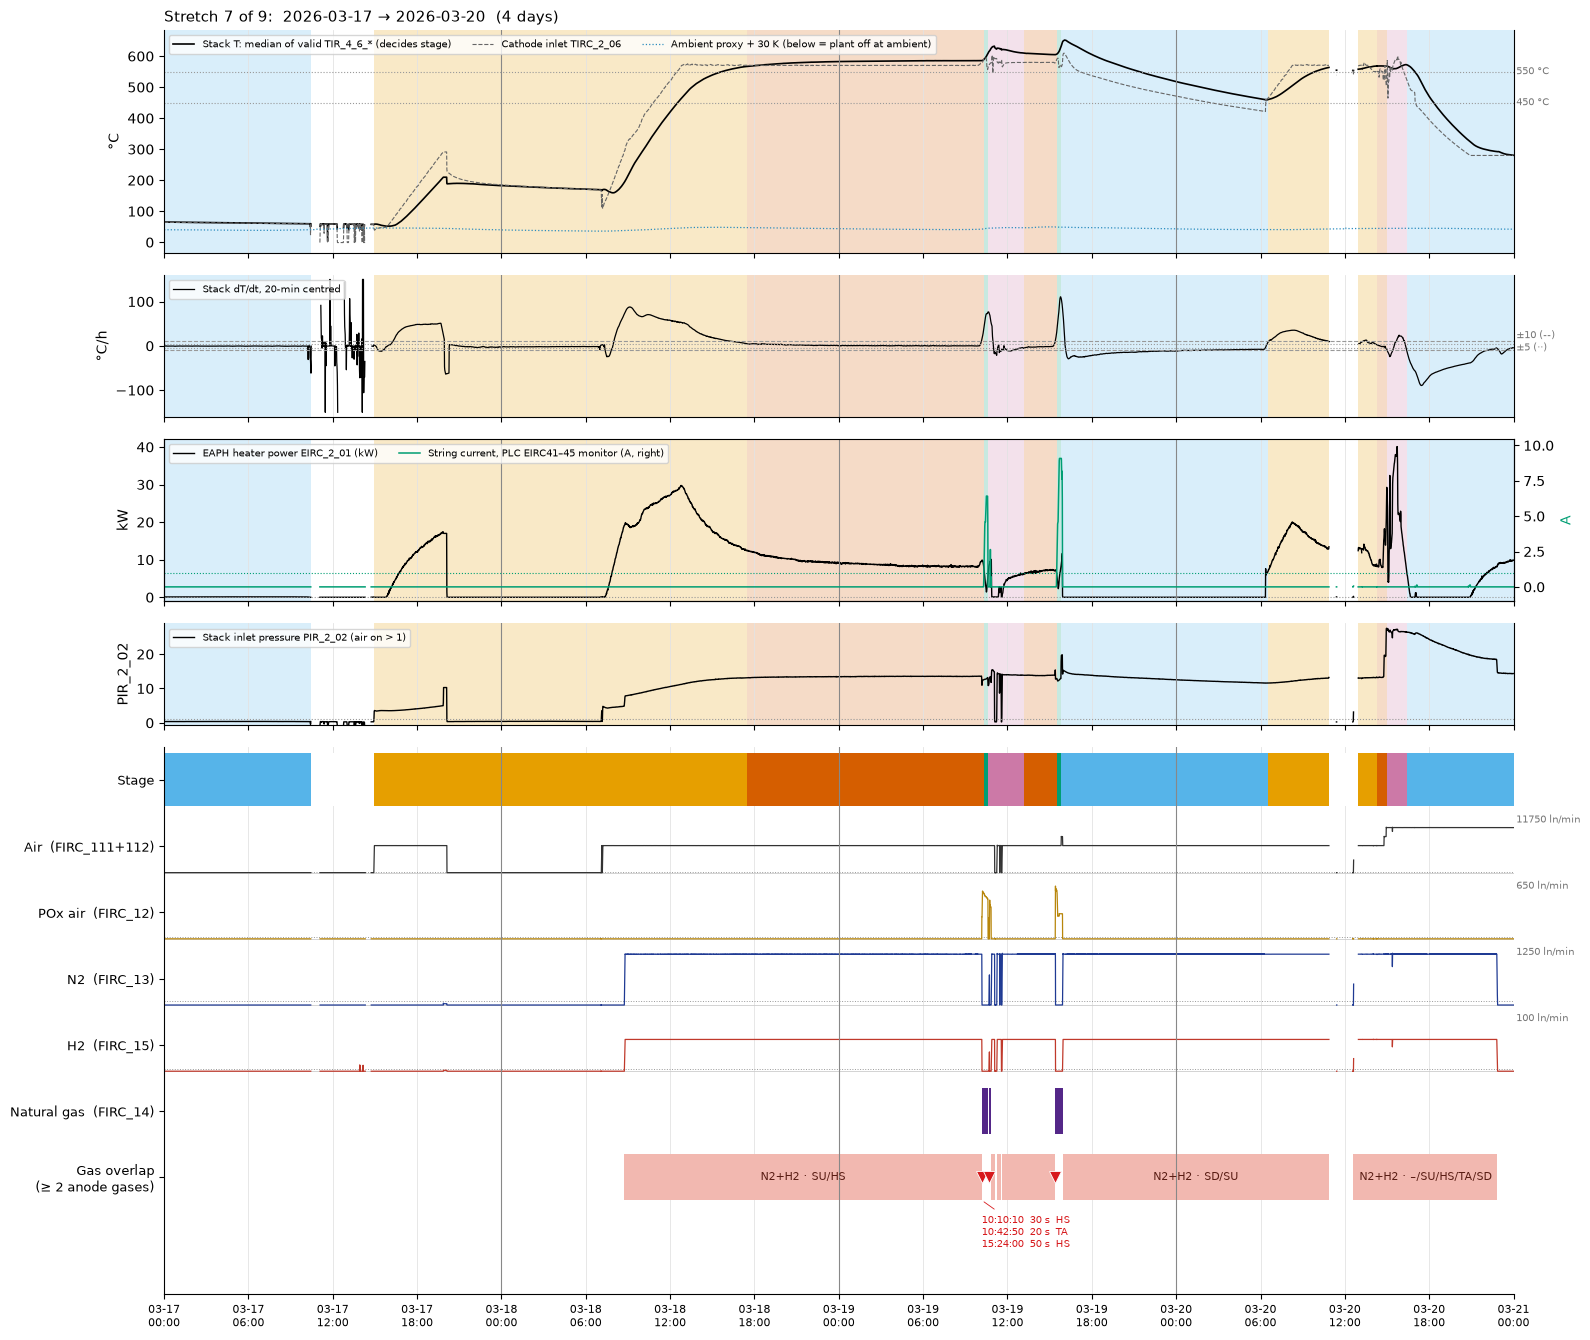

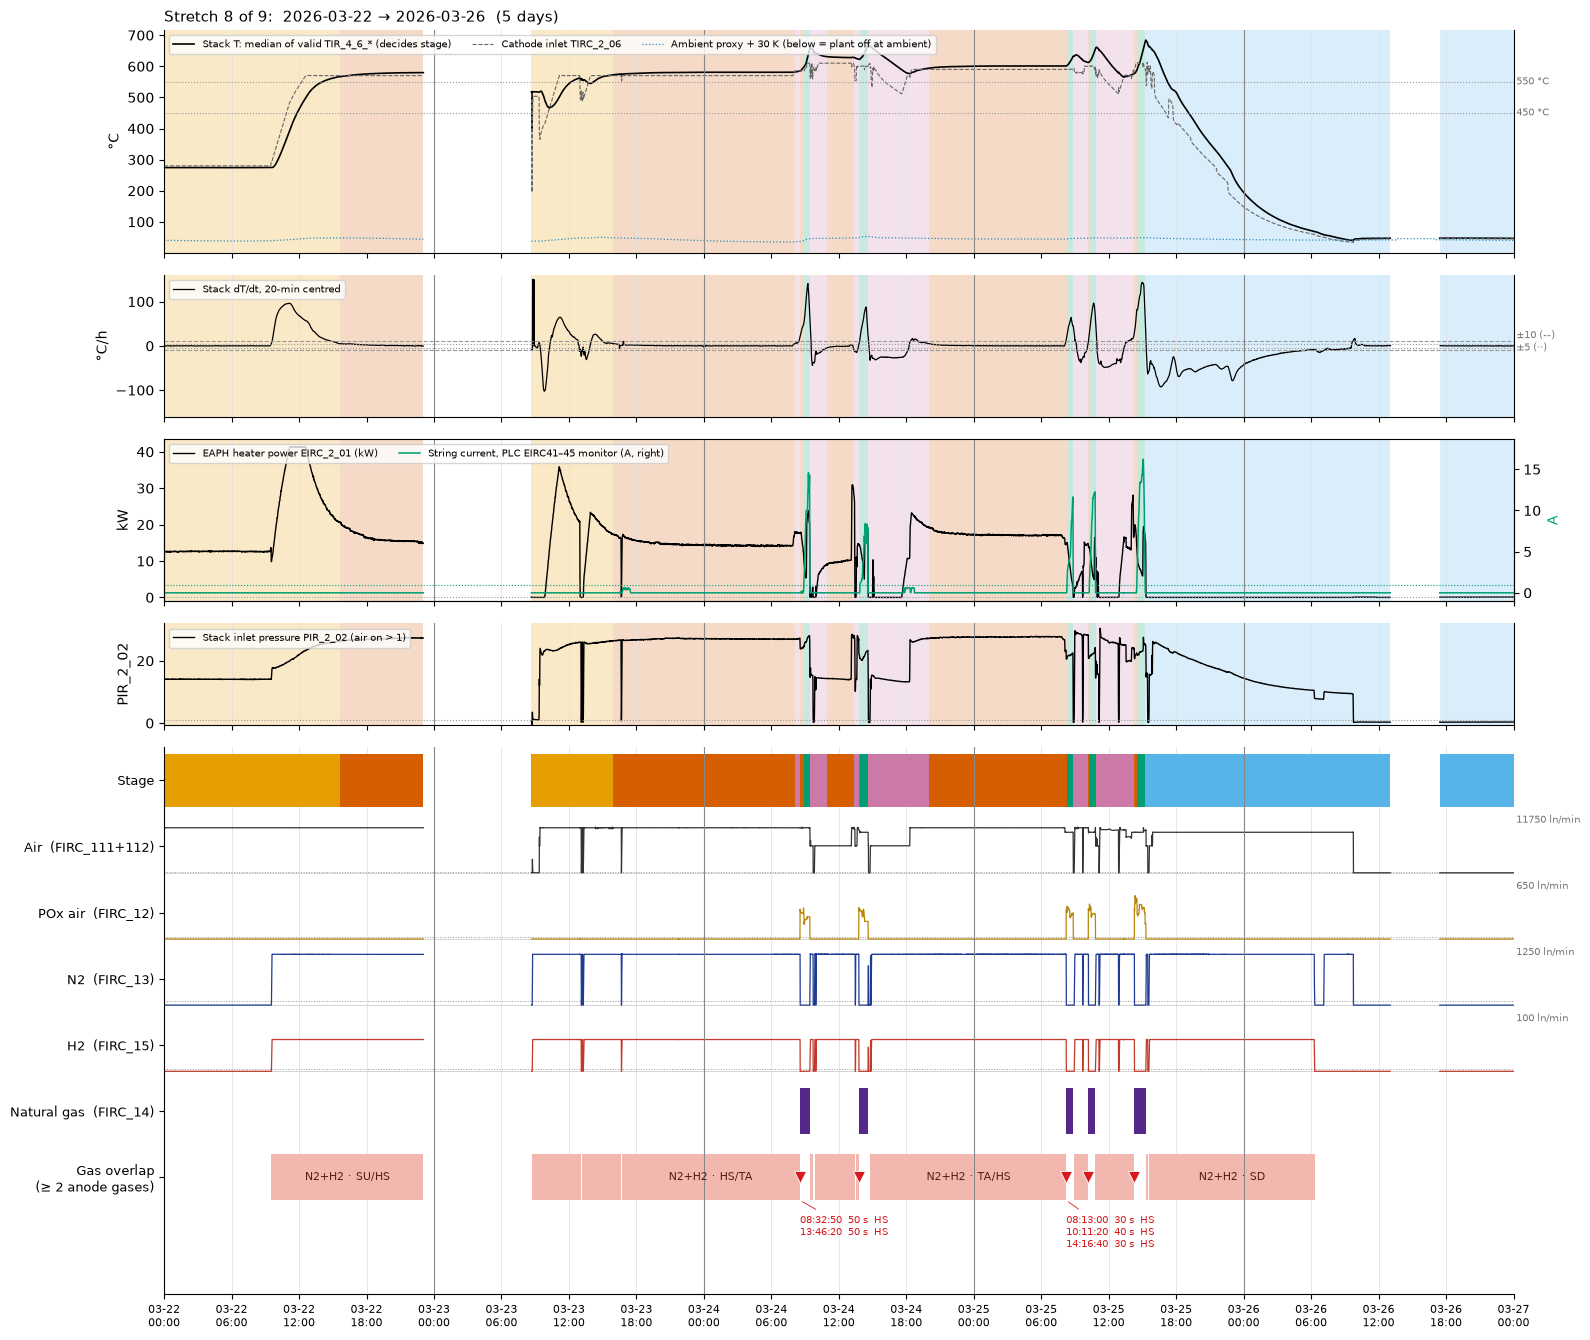

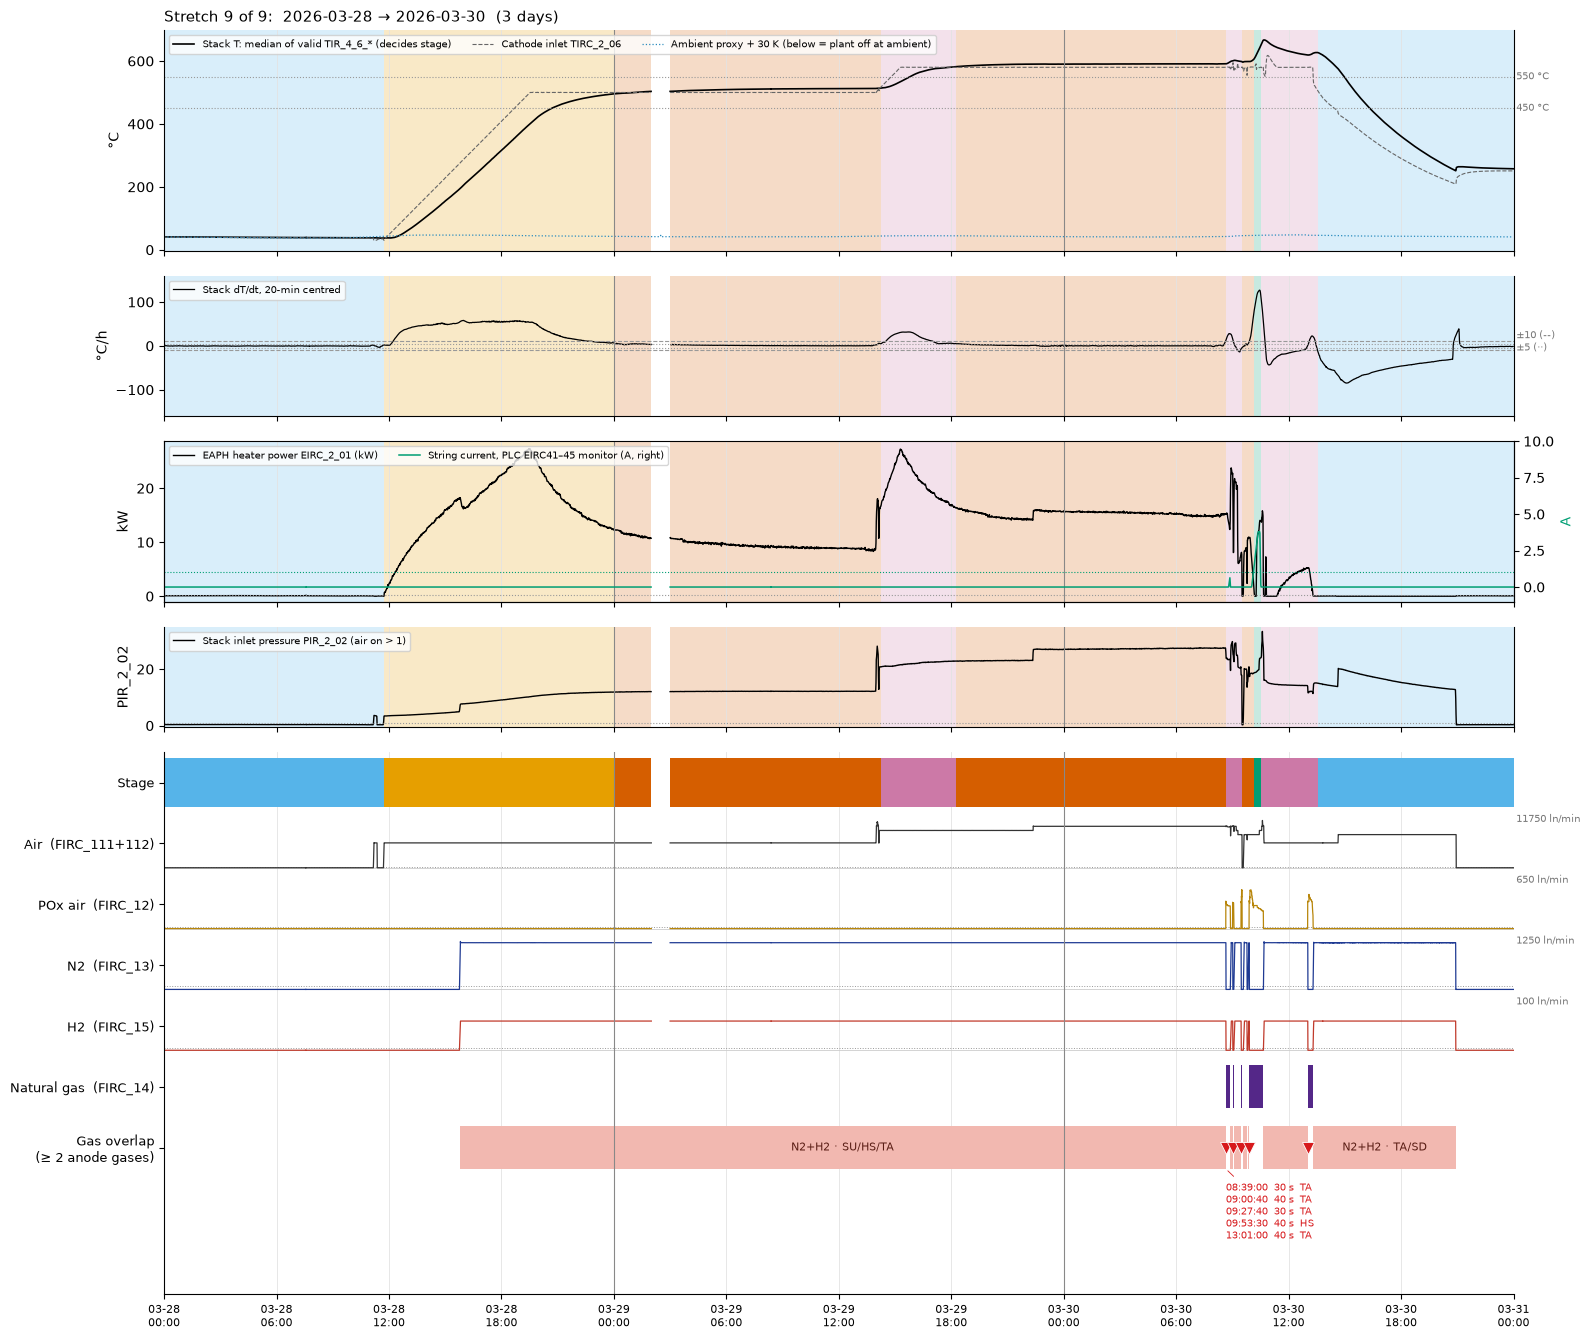

Labels:  HS Hot standby · SD Shut-down · SU Start-up · TA Thermal adjustment · PL Part load


stage,Start-up,Hot standby,Thermal adjustment,Part load,Shut-down
overlap,,,,,
N2 + H2,4880.2,17707.0,2578.8,1.3,8087.8
NG + N2 + H2,0.0,10.5,2.7,0.0,0.0


,stretch,start,seconds,stage
0,5,2026-03-04 11:06:10,20,Hot standby
1,5,2026-03-04 11:13:50,60,Hot standby
2,5,2026-03-04 11:22:00,140,Hot standby
3,6,2026-03-13 09:43:50,50,Hot standby
4,6,2026-03-13 13:18:20,40,Hot standby
5,7,2026-03-19 10:10:10,30,Hot standby
6,7,2026-03-19 10:42:50,20,Thermal adjustment
7,7,2026-03-19 15:24:00,50,Hot standby
8,8,2026-03-24 08:32:50,50,Hot standby
9,8,2026-03-24 13:46:20,50,Hot standby


In [17]:
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

GASES = {
    "Air": (
        ["ct_FIRC_111_PV_ProcessValue", "ct_FIRC_112_PV_ProcessValue"],
        ops.AIR_FLOW_ON,
        ops.GAS_COLORS["air"],
    ),
    "N2": (["ct_FIRC_13_PV_ProcessValue"], ops.N2_ON, ops.GAS_COLORS["N2"]),
    "H2": (["ct_FIRC_15_PV_ProcessValue"], ops.H2_ON, ops.GAS_COLORS["H2"]),
    "POx air": (
        ["ct_FIRC_12_PV_ProcessValue"],
        ops.NG_ON,
        "#B8860B",
    ),  # reformer air, only with NG
    "NG": (["ct_FIRC_14_PV_ProcessValue"], ops.NG_ON, ops.GAS_COLORS["NG"]),
}
ANODE = ["N2", "H2", "NG"]  # air is on the cathode side and never mixes with these
TRACED = [
    "Air",
    "POx air",
    "N2",
    "H2",
]  # drawn as flow traces inside their lane; NG stays an on/off bar
OVERLAP_COLORS = {
    "N2 + H2": "#F2B8B0",
    "NG + N2 + H2": "#D7191C",
    "NG + N2": "#FDAE61",
    "NG + H2": "#FDAE61",
}


def gas_on_10s(d, stage_1min):
    cols = sorted({c for v in GASES.values() for c in v[0]})
    r = pd.read_parquet(ops.SRC / f"{d}_10s.parquet", columns=["Date Time", *cols])
    r.index = pd.to_datetime(r.pop("Date Time"))
    r = r.apply(pd.to_numeric, errors="coerce")
    flow = pd.DataFrame(
        {g: r[c].sum(axis=1, min_count=1) for g, (c, _, _) in GASES.items()}
    )
    on = pd.DataFrame({g: flow[g] > lim for g, (_, lim, _) in GASES.items()})
    on[[f"F_{g}" for g in TRACED]] = flow[TRACED].to_numpy()
    names = {"N2": "N2", "H2": "H2", "NG": "NG"}
    on["overlap"] = on[ANODE].apply(
        lambda row: (
            " + ".join(names[g] for g in ["NG", "N2", "H2"] if row[g])
            if row[ANODE].sum() >= 2
            else ""
        ),
        axis=1,
    )
    on["stage"] = stage_1min.reindex(on.index, method="ffill")
    return on


def runs(mask_or_labels, index):
    """Contiguous runs as (label, start, end, n_rows) of a boolean or label series
    (empty label / False skipped)."""
    v = mask_or_labels
    run = (v != v.shift()).cumsum()
    for _, g in v.groupby(run):
        if (
            isinstance(g.iloc[0], str)
            and g.iloc[0]
            or not isinstance(g.iloc[0], str)
            and bool(g.iloc[0])
        ):
            yield g.iloc[0], g.index[0], g.index[-1] + pd.Timedelta("10s"), len(g)


days = list(all_days)

days = list(all_days)
gas10 = {d: gas_on_10s(d, all_days[d][0]["stage"]) for d in days}
# One full scale per traced gas over all days, so lane heights compare across stretches
FULL = {
    g: max(
        50.0, float(np.ceil(max(v[f"F_{g}"].max() for v in gas10.values()) / 50) * 50)
    )
    for g in TRACED
}


def sensor_panels(axs, s, seg):
    """The signals that decide the stage (section 2), with the gate thresholds as
    dotted lines."""
    a0, a1, a2, a3 = axs
    a0.plot(
        s.index,
        s.T_stack_C,
        color="k",
        lw=1.2,
        label="Stack T: median of valid TIR_4_6_* (decides stage)",
    )
    a0.plot(
        s.index,
        s.T_cathode_in_C,
        color="#666",
        lw=0.8,
        ls="--",
        label="Cathode inlet TIRC_2_06",
    )
    a0.plot(
        s.index,
        s.T_amb_C + ops.DT_AMBIENT,
        color="#2b8cbe",
        lw=0.9,
        ls=":",
        label=f"Ambient proxy + {ops.DT_AMBIENT:.0f} K (below = plant off at ambient)",
    )
    for y in (ops.T_HOT, ops.T_STANDBY):
        a0.axhline(y, color="#999", ls=":", lw=0.8)
        a0.text(
            1.002,
            y,
            f"{y:.0f} °C",
            transform=a0.get_yaxis_transform(),
            fontsize=7,
            color="#777",
            va="center",
        )
    a0.set_ylabel("°C")
    a1.plot(
        s.index,
        s.dTdt_20min_C_per_h.clip(-150, 150),
        color="k",
        lw=0.9,
        label="Stack dT/dt, 20-min centred",
    )
    for y, ls in (
        (ops.DTDT_HEAT, "--"),
        (-ops.DTDT_HEAT, "--"),
        (ops.DTDT_STABLE, ":"),
        (-ops.DTDT_STABLE, ":"),
    ):
        a1.axhline(y, color="#999", ls=ls, lw=0.8)
    a1.set_ylabel("°C/h")
    a1.set_ylim(-160, 160)
    a1.text(
        1.002,
        ops.DTDT_HEAT,
        f"±{ops.DTDT_HEAT:.0f} (--)\n±{ops.DTDT_STABLE:.0f} (··)",
        transform=a1.get_yaxis_transform(),
        fontsize=7,
        color="#777",
        va="center",
    )
    a2.plot(
        s.index, s.P_EAPH_kW, color="k", lw=1, label="EAPH heater power EIRC_2_01 (kW)"
    )
    a2.set_ylabel("kW")
    a2.set_ylim(bottom=-1)
    a2b = a2.twinx()
    a2b.plot(
        s.index,
        s.I_string_A,
        color="#009E73",
        lw=1.1,
        label="String current, PLC EIRC41–45 monitor (A, right)",
    )
    a2b.axhline(ops.I_LOAD, color="#009E73", ls=":", lw=0.8)
    a2.axhline(ops.EAPH_ON_W / 1000, color="#999", ls=":", lw=0.8)
    a2b.set_ylabel("A", color="#009E73")
    a2b.set_ylim(-1, max(10, s.I_string_A.max() * 1.15))
    a3.plot(
        s.index,
        s.P_air_in,
        color="k",
        lw=1,
        label="Stack inlet pressure PIR_2_02 (air on > 1)",
    )
    a3.axhline(ops.AIR_ON, color="#999", ls=":", lw=0.8)
    a3.set_ylabel("PIR_2_02")
    a3.set_ylim(bottom=-0.5)
    for r in seg.itertuples():
        for a in axs:
            a.axvspan(
                r.start,
                r.end,
                color=ops.STAGE_COLORS.get(r.stage, "#fff"),
                alpha=ops.STAGE_TINT,
                lw=0,
            )
    lines = a2.get_lines()[:1] + a2b.get_lines()[:1]
    a2.legend(
        lines,
        [line.get_label() for line in lines],
        loc="upper left",
        fontsize=7.5,
        ncol=2,
    )
    for a in (a0, a1, a3):
        a.legend(loc="upper left", fontsize=7.5, ncol=3)
    for a in axs:
        a.spines["top"].set_visible(False)
        a.grid(axis="x", color="#e3e3e3", lw=0.6)


# Split into stretches of consecutive day files; one figure per stretch on a clock-time
# axis.
groups = []
for d in days:
    if groups and pd.Timestamp(d) - pd.Timestamp(groups[-1][-1]) == pd.Timedelta("1D"):
        groups[-1].append(d)
    else:
        groups.append([d])

LANES = ["Stage", "Air", "POx air", "N2", "H2", "NG", "Overlap"]
Y = {k: len(LANES) - 1 - i for i, k in enumerate(LANES)}
LANE_LABELS = [
    "Stage",
    "Air  (FIRC_111+112)",
    "POx air  (FIRC_12)",
    "N2  (FIRC_13)",
    "H2  (FIRC_15)",
    "Natural gas  (FIRC_14)",
    "Gas overlap\n(≥ 2 anode gases)",
]
SHORT = {
    "Hot standby": "HS",
    "Shut-down": "SD",
    "Start-up": "SU",
    ops.ADJUST: "TA",
    "Part load": "PL",
    "Rated power": "RP",
    "Idle": "Idle",
    "No data": "–",
}
num = mdates.date2num


def span(a, b):
    return (num(a), num(b) - num(a))


legend_handles = (
    [mpatches.Patch(color=c, label=k) for k, c in ops.STAGE_COLORS.items()]
    + [mpatches.Patch(color="none", label="   ")]
    + [Line2D([], [], color=GASES[g][2], lw=1.2, label=f"{g} flow") for g in TRACED]
    + [mpatches.Patch(color=GASES["NG"][2], label="Natural gas")]
    + [
        mpatches.Patch(color=OVERLAP_COLORS["N2 + H2"], label="N2 + H2 (forming gas)"),
        mpatches.Patch(color="#D7191C", label="NG + N2 + H2 (switch-over handover)"),
    ]
)

ov_rows = []
for gi, grp in enumerate(groups, 1):
    t0, t1 = pd.Timestamp(grp[0]), pd.Timestamp(grp[-1]) + pd.Timedelta("1D")
    fig, axs = plt.subplots(
        5,
        1,
        figsize=(16, 13.5),
        sharex=True,
        gridspec_kw={"height_ratios": [2.2, 1.4, 1.6, 1.0, 5.4]},
    )
    ax = axs[-1]  # gas lanes; axs[:4] = stage-deciding sensors
    st_1m = pd.concat([all_days[d][0] for d in grp])
    st_1m = st_1m.reindex(
        pd.date_range(t0, t1, freq="1min", inclusive="left")
    )  # logger gaps -> breaks in the lines
    sensor_panels(axs[:4], st_1m, pd.concat([all_days[d][1] for d in grp]))
    on = pd.concat([gas10[d] for d in grp])
    seg = pd.concat([all_days[d][1] for d in grp])
    for r in seg.itertuples():
        ax.broken_barh(
            [span(r.start, r.end)],
            (Y["Stage"] - 0.4, 0.8),
            color=ops.STAGE_COLORS.get(r.stage, "#fff"),
            lw=0,
        )
    ax.broken_barh(
        [span(a, b) for _, a, b, _ in runs(on["NG"], on.index)],
        (Y["NG"] - 0.35, 0.7),
        color=GASES["NG"][2],
        lw=0,
    )
    for g in TRACED:  # flow trace scaled into the lane: bottom = 0, top = FULL[g]
        f = (
            on[f"F_{g}"].resample("10s").mean()
        )  # empty 10 s bins -> NaN -> breaks at logger gaps

        def to_lane(v):
            return Y[g] - 0.4 + 0.8 * v / FULL[g]

        ax.axhline(Y[g] - 0.4, color="#ccc", lw=0.6)
        ax.axhline(to_lane(GASES[g][1]), color="#999", ls=":", lw=0.7)  # "on" threshold
        ax.plot(f.index, to_lane(f.clip(lower=0)), color=GASES[g][2], lw=0.9)
        ax.text(
            1.002,
            Y[g] + 0.4,
            f"{FULL[g]:.0f} ln/min",
            transform=ax.get_yaxis_transform(),
            fontsize=7,
            color="#777",
            va="center",
        )
    # Overlap runs, joined across midnight (day files are consecutive here)
    ovr = list(runs(on["overlap"], on.index))
    for lab, a, b, n in ovr:
        ax.broken_barh(
            [span(a, b)],
            (Y["Overlap"] - 0.35, 0.7),
            color=OVERLAP_COLORS.get(lab, "#FDAE61"),
            lw=0,
        )
        stages = list(
            dict.fromkeys(on.loc[a : b - pd.Timedelta("10s"), "stage"].dropna())
        )
        ov_rows.append(
            {
                "stretch": gi,
                "gases": lab,
                "start": a,
                "end": b,
                "seconds": n * 10,
                "stage": " / ".join(stages),
            }
        )
        if "NG" in lab:
            continue
        if (b - a) / (t1 - t0) >= 0.06:  # wide enough to hold a stage label
            ax.text(
                num(a + (b - a) / 2),
                Y["Overlap"],
                "N2+H2 · " + "/".join(SHORT.get(s, s) for s in stages),
                ha="center",
                va="center",
                fontsize=8,
                color="#5a1d14",
                clip_on=True,
            )
    # Natural-gas handovers: a marker each; handovers close together share one label,
    # one line per handover
    ng = [(a, n, on.loc[a, "stage"]) for lab, a, b, n in ovr if "NG" in lab]
    clusters = []
    for h in ng:
        if (
            clusters
            and num(h[0]) - num(clusters[-1][-1][0]) < (num(t1) - num(t0)) * 0.08
        ):
            clusters[-1].append(h)
        else:
            clusters.append([h])
    for a, n, st in ng:
        ax.plot(
            num(a),
            Y["Overlap"],
            marker="v",
            color="#D7191C",
            ms=8,
            mec="white",
            mew=0.6,
            zorder=5,
        )
    for c in clusters:
        x = num(c[0][0])
        txt = "\n".join(
            f"{a:%H:%M:%S}  {n * 10} s  {SHORT.get(st, st)}" for a, n, st in c
        )
        ax.annotate(
            txt,
            (x, Y["Overlap"] - 0.35),
            xytext=(x, Y["Overlap"] - 0.55),
            fontsize=7.5,
            color="#D7191C",
            ha="left",
            va="top",
            linespacing=1.15,
            arrowprops=dict(arrowstyle="-", color="#D7191C", lw=0.6),
        )
    n_lines = max((len(c) for c in clusters), default=0)
    for d in grp[1:]:
        for a_ in axs:
            a_.axvline(num(pd.Timestamp(d)), color="#888", lw=0.8)
    ax.set_xlim(num(t0), num(t1))
    hours = (t1 - t0) / pd.Timedelta("1h")
    ax.xaxis.set_major_locator(
        mdates.HourLocator(
            byhour=range(0, 24, 3 if hours <= 48 else 6 if hours <= 120 else 12)
        )
    )
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d\n%H:%M"))
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", color="#e3e3e3", lw=0.6)
    ax.set_axisbelow(True)
    ax.set_yticks(list(Y.values()), LANE_LABELS, fontsize=9)
    ax.set_ylim(-0.6 - 0.32 * n_lines - (0.2 if n_lines else 0), len(LANES) - 0.5)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    title = f"{t0:%Y-%m-%d}" + (
        f" → {pd.Timestamp(grp[-1]):%Y-%m-%d}" if len(grp) > 1 else ""
    )
    axs[0].set_title(
        f"Stretch {gi} of {len(groups)}:  {title}  ({len(grp)} "
        f"day{'s' if len(grp) > 1 else ''})",
        loc="left",
        fontsize=11,
    )
    if gi == 1:
        axs[0].add_artist(
            axs[0].get_legend()
        )  # keep the sensor legend next to the shared one
        axs[0].legend(
            handles=legend_handles,
            ncol=8,
            fontsize=8,
            loc="lower left",
            bbox_to_anchor=(0, 1.12),
            frameon=False,
        )
    fig.tight_layout()
    plt.show()

print(
    "Labels:  HS Hot standby · SD Shut-down · SU Start-up · TA Thermal "
    "adjustment · PL Part load"
)
ov = pd.DataFrame(ov_rows)
all10 = pd.concat(gas10.values())
all10 = all10[all10.overlap != ""]
overlap_min = (
    (pd.crosstab(all10.overlap, all10.stage) / 6)
    .round(1)
    .reindex(columns=[c for c in ops.STAGES if c in set(all10.stage)])
)
display(overlap_min)
ov[ov.gases.str.contains("NG")][["stretch", "start", "seconds", "stage"]].reset_index(
    drop=True
)

In [18]:
counts.to_csv(ops.OUT / "stage_episodes_per_day.csv")
starts.to_csv(ops.OUT / "stage_new_starts_per_day.csv")
minutes.to_csv(ops.OUT / "stage_minutes_per_day.csv")
sorted(p.name for p in ops.OUT.glob("stage_*_per_day.csv"))

['stage_episodes_per_day.csv',
 'stage_minutes_per_day.csv',
 'stage_new_starts_per_day.csv']

### 9.5 What the counts show

* **Rated power was never reached** on any day (0 episodes), matching §6.1 of the operational-modes file.
* **Part load** occurs on 5 days: 2026-03-13, 03-19, 03-24, 03-25 and 03-30. 2026-03-04 is not among them, because its
  only current was a 1-minute blip of 1.15 A. 2026-03-13 shows two load periods (up to 8.3 A / 19 kW) that the
  operational-modes file does not list, because its load table starts on 03-19.
* **2026-03-20 has no load.** The 18.8 A quoted for that day in the operational-modes file comes from the corrupted
  `EIRC_4X_CurrentMon` columns. The PLC current reads ~0 A while the stack cools to 280 °C.
* The multi-day holds at ~510 °C (2026-01-31 → 02-04, 02-14 → 16, 03-01 → 03) are **Hot standby, low-temperature hold**:
  the stack sits flat (< 0.1 °C/h) with the heater trimming at ~9–10 kW and no load. Before this rule the heater-on gate
  labelled them Start-up, heat-up for whole days.
* **Thermal adjustment** (no-load re-heat or cool-back of a hot stack) occurs in 18 episodes (2,729 min, 45 h). Every
  Part load episode starts from Hot standby (pre-load), and 7 of the 10 are followed by a Thermal adjustment, 3 by a Shut-down.
* **Idle** occurs only on 2025-10-30 (2 episodes, 1,258 min). Every other Start-up begins from a Shut-down.
* Multi-day stages (e.g. these holds, or the 2025-11-14→17 cool-down) appear as one episode on every day they
  span. The new-starts table counts them once.

### 9.6 Multi-day holds at ~510 °C → Hot standby, low-temperature hold

Three times the stack was parked at ~510 °C for 1.7–3 days: flat temperature, heater trimming at ~9–10 kW, air on, no
load. The heater-on gate used to label these days **Start-up, heat-up** from midnight to midnight. A Start-up
intermediate hold (§4.3) is a step of a few hours, so a steady 450–550 °C hold of **≥ 6 h** (`MIN_HOLD_MIN`) is now
**Hot standby, low-temperature hold**. Shorter holds stay Start-up. Once in Hot standby the stack does not go back to Start-up: the climb from ~510 °C to the
operating window is **Thermal adjustment, re-heat to operating temperature**, and a cool-down that levels off in the hold is
**Thermal adjustment, cool-back (no load)**. Decided 2026-10-14 and recorded in `../01_docs/operational-modes.md` §1, §3.1, §4.3.

Effect of the hold rule alone over all 39 day files, at the time it was introduced (before Hot standby was restricted to a
constant temperature and the Thermal adjustment stage was added; today's totals are in 9.1 and 9.3):

| | Before (heater rule first) | After (hold rule) |
|---|---|---|
| Hot standby, minutes | 8,001 | 20,432 |
| Start-up, minutes | 19,791 | 7,702 |
| Shut-down, minutes | 15,618 | 15,279 |
| Start-up episodes | 25 | 16 |
| Hot standby episodes | 20 | 29 |

Only the 14 days around the holds changed; load and plant-off (then *Cold / idle*) minutes were identical.

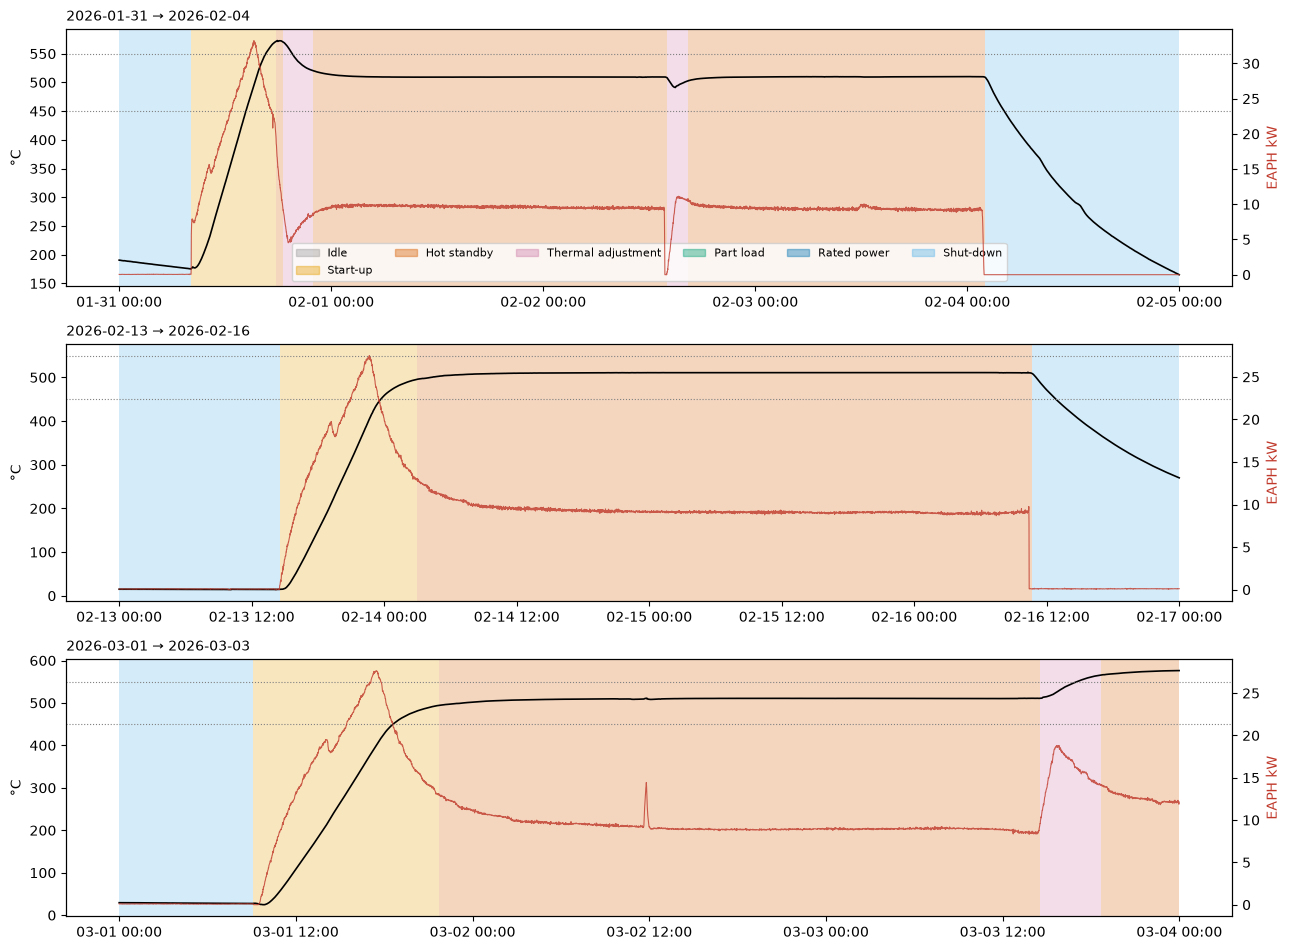

,start,end,hours,T mean °C,T min–max °C,EAPH mean kW,followed by
0,2026-01-31 21:56:00,2026-02-04 02:01:00,76.1,509.3,491–521,9.4,"Shut-down, Cool-down (air flow on)"
1,2026-02-14 02:58:00,2026-02-16 10:37:00,55.6,509.9,496–512,9.3,"Shut-down, Cool-down (air flow on)"
2,2026-03-01 21:43:00,2026-03-03 14:33:00,40.8,509.1,494–511,9.4,"Thermal adjustment, Re-heat to operating tempe..."


In [19]:
holds = [
    ("2026-01-31", "2026-02-04"),
    ("2026-02-13", "2026-02-16"),
    ("2026-03-01", "2026-03-03"),
]
fig, ax = plt.subplots(len(holds), 1, figsize=(13, 3.2 * len(holds)))
rows = []
for a, (d0, d1) in zip(ax, holds):
    days = [d.strftime("%Y%m%d") for d in pd.date_range(d0, d1)]
    s = pd.concat([all_days[d][0] for d in days if d in all_days])
    seg = pd.concat([all_days[d][1] for d in days if d in all_days])
    for r in seg.itertuples():
        a.axvspan(
            r.start,
            r.end,
            color=ops.STAGE_COLORS.get(r.stage, "#fff"),
            alpha=0.25,
            lw=0,
        )
    a.plot(s.index, s.T_stack_C, "k", lw=1.2, label="stack T (median TC)")
    a.axhline(ops.T_HOT, color="grey", ls=":", lw=0.8)
    a.axhline(ops.T_STANDBY, color="grey", ls=":", lw=0.8)
    a.set_ylabel("°C")
    a.set_title(f"{d0} → {d1}", fontsize=10, loc="left")
    b = a.twinx()
    b.plot(s.index, s.P_EAPH_kW, color="#c0392b", lw=0.8, alpha=0.8)
    b.set_ylabel("EAPH kW", color="#c0392b")
    a.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M"))
    # one row per hold, joined across midnight
    h = s.operation.eq(ops.LOW_HOLD) | s.operation.isin(
        ["Temperature dip during hold", "Re-heat to hold"]
    )
    run = (h != h.shift()).cumsum()
    for _, g in s[h].groupby(run[h]):
        if len(g) < ops.MIN_HOLD_MIN:
            continue
        after = s.loc[s.index > g.index[-1]]
        after = after[after.stage != "No data"]
        rows.append(
            {
                "start": g.index[0],
                "end": g.index[-1] + pd.Timedelta("1min"),
                "hours": round(len(g) / 60, 1),
                "T mean °C": round(g.T_stack_C.mean(), 1),
                "T min–max °C": f"{g.T_stack_C.min():.0f}–{g.T_stack_C.max():.0f}",
                "EAPH mean kW": round(g.P_EAPH_kW.mean(), 1),
                "followed by": f"{after.stage.iloc[0]}, {after.operation.iloc[0]}"
                if len(after)
                else "-",
            }
        )
ax[0].legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.4)
        for c in ops.STAGE_COLORS.values()
    ],
    labels=list(ops.STAGE_COLORS),
    ncol=6,
    fontsize=8,
    loc="lower center",
)
fig.tight_layout()
plt.show()
pd.DataFrame(rows)

### 9.7 Idle as its own stage; near ambient = Shut-down

Decided 2026-10-14 (recorded in `../01_docs/operational-modes.md` §1). The old **Cold / idle** label mixed three things: a stack
settled at room temperature, the natural-cooling tail of a Shut-down, and a warm stack with nothing before it. It is now split:

| Plant off (no current, heater off, air off), \|dT/dt\| < 10 °C/h | Stage, operation |
|---|---|
| Stack ≤ ambient + 30 K | **Shut-down, plant off at ambient** |
| Stack warm, a Shut-down came before it | **Shut-down, natural cooling (air off)** |
| Stack warm, no Shut-down before it | **Idle** (natural cooling / stable / heat-up stopped) |
| Stack warm, between two parts of one heat-up | **Start-up, heat-up interrupted (plant off)** |

There is no ambient sensor; the fuel-module supply-line probes (10–18 °C) are the proxy, so "near ambient" is about
40–48 °C. This 30 K test replaces the earlier fixed 50 °C end point of Shut-down. A Shut-down before midnight is
followed into the next day file, across up to 7 missing days. Shut-down carries the sub-stage *Cooling* (forced or
natural cooling, stack still warm) or *At ambient (plant off)*.

Effect over all 39 day files: the 9,745 former Cold / idle minutes become 1,258 **Idle** (2025-10-30 only, no
history), 663 **Start-up, heat-up interrupted (plant off)** (2026-03-17 20:08 → 03-18 07:10, 188 → 167 °C at about
−2 °C/h between two parts of one heat-up, user confirmed) and 7,824 **Shut-down** (3,165 natural-cooling tail, 4,659
plant off at ambient). The 50 °C-rule conflicts in `flow_check.py` are gone.


In [20]:
allseg = pd.concat({d: v[1] for d, v in all_days.items()}, names=["day"]).reset_index(
    level=0
)
(
    allseg[allseg.stage.isin(["Idle", "Shut-down"])]
    .groupby(["stage", "operation"])["duration_min"]
    .sum()
    .to_frame("minutes")
)

minutes
stage     operation                                            
Idle      Heat-up stopped - settling / natural cooling       99
          Natural cooling (heater off, no air)             1159
Shut-down Controlled cool-down (heater trim)                 77
          Cool-down (air flow on)                         14900
          Heater on without air (false start)               633
          Load ramp-down to zero                              9
          Natural cooling (air off)                        3165
          Plant off at ambient                             4659
          Slow cool-down                                    299
          Temperature rise, heater off                       22

## 10. Findings and open questions (first day file)

* **No power operation.** Stack current and stack power are zero all day. The day is **87 % Idle** and **13 % Start-up**.
* **One aborted start-up:** air purge 11:29–12:27 (stack 139 → 116 °C), then EAPH heat-up 12:27–14:31 (116 → 216 °C,
  peak ~72 °C/h, within the 120 °C/h limit). It stopped far below Hot standby.
* **Open questions**
  1. Was the stop at 14:30 (air and EAPH off in the same minute) a trip or a planned stop? Event log needed.
  2. Is the hour of air flow with the heater off at 11:29 the intended purge step of Start-up?
  3. ~~Should "sitting warm, nothing on" stay Cold / idle?~~ Decided 2026-10-14: it is its own stage, **Idle**, unless a
     Shut-down comes before it (then it is the Shut-down natural-cooling tail); near ambient the plant is **Shut-down** (§9.7). The overnight pause of 2026-03-17/18 is Start-up, heat-up interrupted.
* To look at another day in detail, change `DAY` in the first code cell. Section 9 always covers all day files.

## 11. Trip conditions and emergency shutdown (all day files, 1 s raw data)

**Question:** did any S-PLC trip condition fire, and did the system go to emergency shutdown?

Trip values come from `../01_docs/component_sensor_map_en.md` §4 (Safety Functions, S-PLC 0xB9E8). Every trip acts when the
condition persists **> 50 ms**. A trip sends the plant to one of two emergency states:

| Emergency state | Triggered by | What the S-PLC does (fingerprint looked for in the data) |
|---|---|---|
| **SPLC_EMERGENCYPURGE** | process trips: TIRZ 8.x temperatures, insulation BE s.1, PIRZ 8.1.2, exhaust fans | purge valves open (air MV1.1.2/1.1.3, N₂ MV1.3.2, H₂ MV1.5.3, NG vents), POx air MV1.2 and NG MV1.4.3 close, **stack contactors and heaters cut at once** |
| **SPLC_EMERGENCYSTOP** | gas detectors, smoke, E-stop buttons | **all** supply valves close, only NG vent MV1.4.4 opens, contactors + PCM + **compressor off** (air pressure collapses); N₂/H₂ purge blocked |

**Limits of the data**

* The logger has no S-PLC state or trip-cause column, so an emergency shutdown is recognised by its fingerprint (valves + power + air).
* Raw data is 1 s. A 50 ms excursion between two samples is invisible, so a trip can fire while the logged value sits just below the limit.
* Gas detectors, smoke detectors, E-stop buttons and exhaust fans are **not logged**: an emergency stop can be detected but not explained.
* The valve columns are PLC set values (`MV_*_SetVal`), not position feedback.
* 2026-03-20 after 11:00 is excluded (column shift, see §9.5).

In [21]:
import matplotlib.dates as mdates
import trip_check as tc

pd.DataFrame(
    [
        {
            "sensor": s,
            "component": comp,
            "trip if": f"> {lim} °C" if lim else "> 100 / 200 / 300 °C (see note)",
        }
        for s, (comp, lim) in tc.TEMP_TRIPS.items()
    ]
    + [
        {
            "sensor": "PIRZ_8_1_2",
            "component": "Pressure monitoring",
            "trip if": f"< {tc.P_TRIP} bar a",
        },
        {
            "sensor": "BE1.1 … BE5.1 (Riso)",
            "component": "Stack insulation",
            "trip if": f"< {tc.RISO_TRIP} kΩ (logged unit unresolved)",
        },
    ]
)

,sensor,component,trip if
0,TIRZ_8_1_1,EAPH,> 1050 °C
1,TIRZ_8_1_3,Stack module,> 720 °C
2,TIRZ_8_1_9,Afterburner (TOX),> 930 °C
3,TIRZ_8_1_10,Exhaust outlet,> 100 / 200 / 300 °C (see note)
4,TIRZ_8_2_1,EAGH,> 950 °C
5,TIRZ_8_2_2,EAOH1,> 950 °C
6,TIRZ_8_2_3,EAOH2,> 950 °C
7,TIRZ_8_2_4,EAOH3,> 950 °C
8,TIRZ_8_2_5,ERH,> 860 °C
9,PIRZ_8_1_2,Pressure monitoring,< 0.75 bar a


Note: the exhaust trip value was **100 °C** until 2026-01-28, **200 °C** until 2026-03-27 and **300 °C** after
(`tc.exhaust_limit(day)`). Each day is checked against the value in force on that day.

### 11.1 How close each trip sensor came to its trip value

Worst value per day, while the instruments were live (stack TC > 0). `margin` = trip value − worst value; a negative margin means the trip value was crossed.

In [22]:
margins = tc.trip_margins()
mcols = [c for c in margins if c.endswith("margin")]
display(
    margins[mcols]
    .style.format("{:.0f}")
    .background_gradient(cmap="RdYlGn", vmin=-20, vmax=200, axis=None)
)
pd.DataFrame(
    {"closest approach (°C)": margins[mcols].min(), "on day": margins[mcols].idxmin()}
)

,TIRZ_8_1_1 margin,TIRZ_8_1_3 margin,TIRZ_8_1_9 margin,TIRZ_8_1_10 margin,TIRZ_8_2_1 margin,TIRZ_8_2_2 margin,TIRZ_8_2_3 margin,TIRZ_8_2_4 margin,TIRZ_8_2_5 margin
2025-10-30,748,507,679,47,641,494,506,700,316
2025-11-13,470,244,519,-80,556,491,480,710,208
2025-11-14,749,275,616,-68,674,586,579,906,547
2025-11-15,822,435,676,-32,744,704,700,876,625
2025-11-16,925,584,796,66,806,809,808,874,722
2025-11-17,997,662,874,74,883,875,873,882,803
2025-11-18,1020,687,899,77,915,904,903,899,829
2026-01-30,774,479,694,161,575,540,511,679,305
2026-01-31,394,143,393,84,468,437,420,699,213
2026-02-01,544,200,476,91,483,450,435,860,224


,closest approach (°C),on day
TIRZ_8_1_1 margin,352.8,2026-03-13
TIRZ_8_1_3 margin,15.6,2026-03-25
TIRZ_8_1_9 margin,133.0,2026-03-13
TIRZ_8_1_10 margin,-79.9,2025-11-13
TIRZ_8_2_1 margin,271.1,2026-03-13
TIRZ_8_2_2 margin,166.8,2026-03-24
TIRZ_8_2_3 margin,141.9,2026-03-24
TIRZ_8_2_4 margin,400.3,2026-03-25
TIRZ_8_2_5 margin,24.2,2026-03-13


In [23]:
margins[["PIRZ_8_1_2 min", "Riso min (logged value)"]].T

,2025-10-30,2025-11-13,2025-11-14,2025-11-15,2025-11-16,2025-11-17,2025-11-18,2026-01-30,2026-01-31,2026-02-01,...,2026-03-19,2026-03-20,2026-03-22,2026-03-23,2026-03-24,2026-03-25,2026-03-26,2026-03-28,2026-03-29,2026-03-30
PIRZ_8_1_2 min,0.996,1.007,1.016,1.019,1.014,1.01,1.024,0.997,1.0,1.02,...,0.935,1.03,1.02,0.924,0.93,0.911,0.999,1.023,1.033,0.922
Riso min (logged value),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,61.000,285.00,220.00,189.000,48.00,41.000,20000.000,930.000,151.000,46.000


### 11.2 Every abrupt cut, classified

Candidates are seconds where stack current or EAPH power drops to ~0, the NG valve closes, or the stack-inlet air pressure collapses.
Each is classified from the valve set values and power 20 s before vs. 3–12 s after. Valve strings are in the order
MV1.1.2 · 1.1.3 · 1.2 · 1.3.2 · 1.4.3 · 1.4.4 · 1.4.5 · 1.5.3 (1 = open):
`11101010` = running on NG, `11010011` = purge / forming gas, `00000100` = emergency-stop pattern.

In [24]:
events = tc.cut_events()
display(events.kind.value_counts().to_frame("events"))
routine = ["Load / heater off, valves unchanged", "Valve change only"]
events[~events.kind.isin(routine)].reset_index(drop=True)

,events
kind,
"Load / heater off, valves unchanged",15
Valve change only,13
All gas + compressor off (vent shut),9
"Gas to purge, heater kept on",6
"Power cut at trip value, gas unchanged",6
EMERGENCY STOP,6
EMERGENCY PURGE,2


,time,kind,valves before,valves after,I string A,EAPH kW,air before→after,T stack °C,trip value exceeded (60 s before),purge back after (min)
0,2026-03-04 11:06:29,"Gas to purge, heater kept on",11011011,11010011,0.0,11.6,11.9→11.7,581,-,NaN
1,2026-03-04 11:14:47,"Gas to purge, heater kept on",11111011,11010011,0.0,11.7,12.2→11.8,580,-,NaN
2,2026-03-13 13:45:15,"Power cut at trip value, gas unchanged",11101010,11101010,7.2,6.4,17.3→17.4,695,TIRZ_8_1_10 202 > 200,NaN
3,2026-03-17 20:07:05,All gas + compressor off (vent shut),11010011,00000000,0.0,17.0,10.3→0.4,196,-,NaN
4,2026-03-19 10:49:49,"Power cut at trip value, gas unchanged",11101010,11101010,2.0,9.3,13.5→13.5,638,TIRZ_8_1_10 202 > 200,NaN
5,2026-03-19 10:52:16,"Power cut at trip value, gas unchanged",11010011,11010011,0.0,9.6,13.8→14.5,641,TIRZ_8_1_10 202 > 200,NaN
6,2026-03-19 11:05:03,EMERGENCY STOP,11010011,00000100,0.0,0.1,14.8→0.3,643,-,9.3
7,2026-03-19 11:33:46,All gas + compressor off (vent shut),11010011,00000000,0.0,3.5,14.3→0.3,630,-,2.4
8,2026-03-19 15:54:35,"Power cut at trip value, gas unchanged",11101010,11101010,6.9,12.2,19.8→19.9,661,TIRZ_8_1_10 201 > 200,NaN
9,2026-03-23 13:05:36,All gas + compressor off (vent shut),11010011,00000000,0.0,0.0,26.6→0.3,561,-,1.4


### 11.3 Exhaust trip (TIRZ_8_1_10): every crossing of the limit in force, and what followed

In [25]:
crossings = tc.exhaust_crossings(events)
crossings

,first above limit,limit °C,peak in next 60 s,running (I > 1 A or EAPH > 5 kW),next cut
0,2025-11-13 20:52:34,100,106.4,False,-
1,2025-11-14 00:00:00,100,167.4,False,-
2,2025-11-15 00:00:00,100,131.4,False,-
3,2025-11-15 11:31:28,100,101.9,False,-
4,2026-02-18 18:38:34,200,238.2,False,-
5,2026-03-13 10:42:45,200,242.5,False,-
6,2026-03-13 13:44:56,200,202.7,True,"19 s later: Power cut at trip value, gas uncha..."
7,2026-03-19 10:49:27,200,202.1,True,"22 s later: Power cut at trip value, gas uncha..."
8,2026-03-19 10:58:27,200,204.7,False,-
9,2026-03-19 11:14:47,200,234.7,False,-


In [26]:
run = crossings[crossings["running (I > 1 A or EAPH > 5 kW)"]]
print(
    f"{len(run)} crossings while running; followed by a cut within 5 min: "
    f"{(run['next cut'] != '-').sum()}"
)
print(
    f"{len(crossings) - len(run)} crossings while already stopped/purging (a trip "
    "changes nothing there)"
)

7 crossings while running; followed by a cut within 5 min: 7
17 crossings while already stopped/purging (a trip changes nothing there)


### 11.4 Three shutdowns side by side

Left: an emergency purge at the exhaust trip value. Middle: an emergency stop under load. Right: a planned stop on the
same days, for contrast (current ramped down first, gas switched minutes later, compressor kept running).

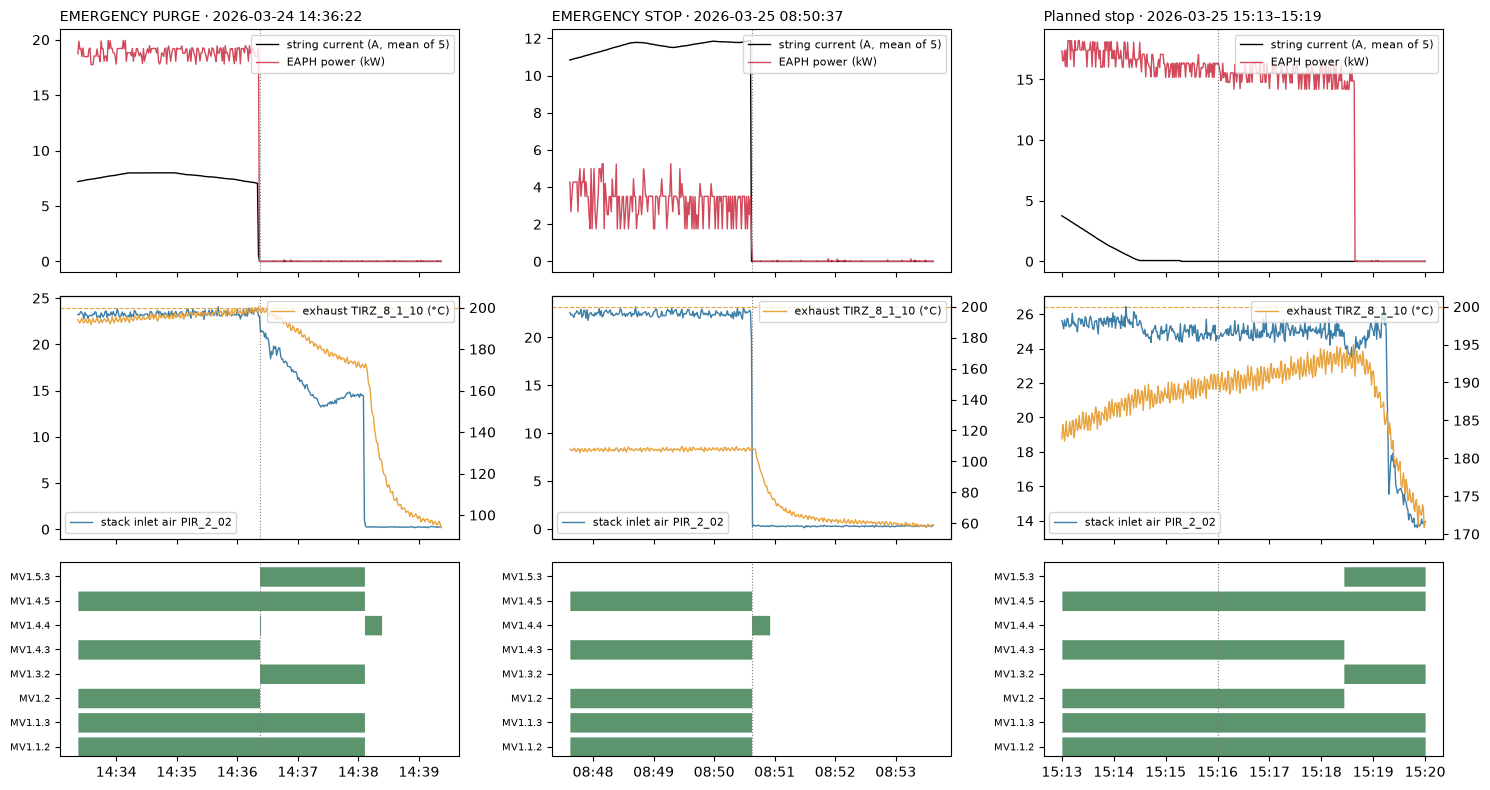

In [27]:
fig, ax = plt.subplots(
    3, 3, figsize=(15, 8), sharex="col", gridspec_kw={"height_ratios": [2, 2, 1.6]}
)
tc.plot_event(
    "2026-03-24 14:36:22",
    ax[:, 0],
    "EMERGENCY PURGE · 2026-03-24 14:36:22",
    exh_limit=200,
)
tc.plot_event(
    "2026-03-25 08:50:37",
    ax[:, 1],
    "EMERGENCY STOP · 2026-03-25 08:50:37",
    exh_limit=200,
)
tc.plot_event(
    "2026-03-25 15:16:00",
    ax[:, 2],
    "Planned stop · 2026-03-25 15:13–15:19",
    before="3min",
    after="4min",
    exh_limit=200,
)
for a in ax[2]:
    a.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
fig.tight_layout()
plt.show()

In [28]:
events.to_csv(ops.OUT / "trip_cut_events.csv", index=False)
crossings.to_csv(ops.OUT / "trip_exhaust_crossings.csv", index=False)
margins.to_csv(ops.OUT / "trip_margins_per_day.csv")
sorted(p.name for p in ops.OUT.glob("trip_*.csv"))

['trip_cut_events.csv',
 'trip_exhaust_crossings.csv',
 'trip_margins_per_day.csv']

### 11.5 Findings

**Yes, the system went to emergency shutdown, in late March 2026 only. The trigger that can be identified is the exhaust trip at 200 °C; no equipment over-temperature trip was ever reached.**

* **No heater or stack over-temperature trip was crossed** on any day (EAPH, stack, TOX, EAGH, EAOH1–3, ERH).
  The tightest margins are the **stack module TIRZ 8.1.3: 15.6 °C below 720 °C (2026-03-25)** and the **ERH TIRZ 8.2.5: 24 °C below 860 °C (2026-03-13)**.
* **Pressure PIRZ 8.1.2 did not trip:** the lowest live reading is 0.907 bar a (limit 0.750). Readings below the limit are logger dropouts (−1) or the instrument switched off with a cold plant (0.0 on 03-17).
* **Insulation: no trip seen.** The unit of the Riso column is unresolved (CONFLICT-RISO-01). Read as Ω, every running day would sit in permanent trip, which the data contradicts. Its minimum (41 on 2026-03-24/25) falls steadily from ~10⁶ in early March, which is worth a separate look.
* **The exhaust trip TIRZ 8.1.10 (200 °C at the time) is what tripped the plant.** All **7 of 7** crossings of 200 °C while stack current or heater was on were followed by a cut 2–25 s later (03-13, 03-19 ×2, 03-24 ×3, 03-25). Crossings while already stopped changed nothing.
  * Two of them are the full **SPLC_EMERGENCYPURGE** fingerprint: **2026-03-24 09:25:26** (13.8 A, 20.5 kW heater) and **14:36:22** (7.2 A, 18.9 kW): NG → purge in one second, stack current and heater cut together.
  * In the other five, current and heater were cut but the valve set values did not move.
  * The logged value hovered at 197–200 °C, so the trip most likely fired on a sub-second spike that the 1 s logger missed (hence the 2–25 s lag).
  * The trip value was raised to 300 °C on 2026-03-27. After that no exhaust trip occurred (max ≈ 250 °C on 03-30).
  * Before 2026-01-28 the limit was 100 °C, and the exhaust exceeded it in November 2025 (up to 180 °C), but only with the plant already off.
* **The SPLC_EMERGENCYSTOP fingerprint appears 6 times with a hot stack (608–690 °C):** 2026-03-19 11:05, 03-24 09:42 and 14:38, 03-25 08:50 and 15:28, 03-30 09:30. In each, all gas closed, NG vent MV1.4.4 opened for ~17 s, and the compressor stopped.
  * On **03-25 08:50** it cut 11.8 A of live load. No logged trip sensor explains it, so the cause is an unlogged input (gas detector, smoke, E-stop button) or a manual action.
  * Three follow a purge trip by 1–17 min (03-24 09:25 → 09:42, 14:36 → 14:38, 03-25 15:18 → 15:28), which looks like an operator/reset sequence, not a new fault.
* **The anode had no N₂/H₂ purge for 4–10 min after each emergency stop**, at 600–690 °C. Nine more "all gas + compressor off" events (same as the stop, but MV1.4.4 stays shut) add 0.5–3 min each, six of them with the stack hot. This is direct evidence for the unprotected-anode-cooling hypothesis.
* **Not S-PLC trips:**
  * The load stop on 03-25 at 15:15 was controlled: current was ramped to 0, the strings switched off, and the gas switched 3 min later.
  * On 03-25 10:49 and 03-30 08:53 / 09:04 the gas switched to purge with the heater left running. That is not the S-PLC action, so these were probably normal-PLC stops.
  * The all-gas stops at 196–268 °C (2026-03-17 20:07, 03-30 20:56) are the plant being switched off at the end of a cool-down.

**Open questions (need the S-PLC event log)**

1. What triggered the six emergency stops: gas detector, smoke, E-stop button, or operator?
2. Why did five exhaust trips cut power without the purge valve set values moving? Was the S-PLC configured differently before 03-24, or do the set values not show the S-PLC override?
3. Does resetting the S-PLC after a purge trip pass through the emergency-stop state?


## 12. Plant stages decided 2026-11-02 (current stage set)

Sections 1–11 label the data with the older stages from `operational-modes.md`. On 2026-11-02 the plant walkthrough
and the devices-on check settled on **eight plant stages**. Each one is named after what the plant is doing (which
supplies and devices are on), not after the stack temperature alone. They are built on top of the labels above, so no
rule in `operating_states.py` changes. The logic lives in `scripts/plant_stages.py`
(command line: `python 03_data_analysis/scripts/plant_stages.py`).

| # | Plant stage | How it is found in the data | Comes from (sections 1–11) |
|---|---|---|---|
| 1 | **Heat-up air** | Start-up, cathode air only (EAPH heats the air) | Start-up, phase *Air only* |
| 2 | **Heat-up N₂+H₂** | Start-up, forming gas on (stack > ~210 °C) | Start-up, phase *Forming gas* / *N₂ purge* |
| 3 | **Hot standby** | hot, forming gas, no load | Hot standby + Thermal adjustment |
| 4 | **Fuel switch** | natural gas on, string current < 1 A | NG minutes outside Part load / Shut-down |
| 5 | **Part load** | string current ≥ 1 A | Part load (Rated power never reached) |
| 6 | **Air-flow cooling** | Shut-down with cathode air > 20 ln/min | Shut-down, air on |
| 7 | **Shutdown** | everything off except control | Shut-down air off (natural cooling, at ambient), Idle, plant-off pauses, **emergency stop** until the air is back on |
| 8 | **Trip: purge** | emergency purge: air, N₂, H₂, control on | trip windows (§11) with a purge or power-cut-at-trip-value cut |

Changes against the older stages:

* **Thermal adjustment** is merged into Hot standby (same devices on).
* **Idle**, **Shut-down at ambient**, natural cooling (air off) and the **emergency stop** are one stage, **Shutdown**.
  After an emergency stop the minutes stay Shutdown until the air is switched back on, then the cool-down follows the
  normal rules.
* Start-up is split by the gas: **Heat-up air** and then **Heat-up N₂+H₂**.
* **Fuel switch** is its own stage between Hot standby and Part load.
* Rule of thumb from the data: **stack > 210 °C → N₂ + H₂ on** (unless natural gas is on, or after an emergency
  stop). It is checked in 12.6, not used to cut the stages.

Order: Heat-up air → Heat-up N₂+H₂ → Hot standby → Fuel switch → Part load → Air-flow cooling → Shutdown, with
Trip: purge breaking in from Part load / Fuel switch.

In [ ]:
import industrial_stages as ins
import plant_stages as ps

windows = ins.trip_windows(
    ins.trip_events()
)  # reads the §11 cut list (operating_states/trip_cut_events.csv)
plant = ps.label(pd.concat(s for s, _ in all_days.values()), windows)
pblocks = ps.blocks(plant)
pepis = ps.episodes(pblocks)

overview = (
    pd.DataFrame(
        {
            "minutes": plant.plant_stage.value_counts(),
            "blocks": pepis.stage.value_counts(),
            "median block (min)": pepis.groupby("stage").minutes.median(),
            "longest block (h)": (pepis.groupby("stage").minutes.max() / 60).round(1),
        }
    )
    .reindex(ps.STAGES + ["No data"])
    .fillna(0)
)
overview["hours"] = (overview.minutes / 60).round(1)
overview["share_%"] = (100 * overview.minutes / overview.minutes.sum()).round(1)
overview.astype({"minutes": int, "blocks": int})[
    ["hours", "share_%", "blocks", "median block (min)", "longest block (h)"]
]

,hours,share_%,blocks,median block (min),longest block (h)
Heat-up air,56.3,6.1,14,236.5,9.6
Heat-up N₂+H₂,81.5,8.8,14,432.5,9.8
Hot standby,337.8,36.5,26,209.5,80.2
Fuel switch,3.5,0.4,19,9.0,0.5
Part load,4.5,0.5,10,27.5,0.7
Air-flow cooling,254.9,27.5,27,11.0,106.0
Shutdown,173.7,18.8,32,105.0,16.4
Trip: purge,1.3,0.1,6,15.0,0.3
No data,12.9,1.4,0,0.0,0.0


### 12.1 Where each plant stage comes from

Minutes per older stage (rows) and plant stage (columns). Each plant stage collects only a few older stages, so the
two sets can be translated into each other.

In [ ]:
pd.crosstab(plant.stage, plant.plant_stage).reindex(
    columns=ps.STAGES + ["No data"], fill_value=0
)

plant_stage,Heat-up air,Heat-up N₂+H₂,Hot standby,Fuel switch,Part load,Air-flow cooling,Shutdown,Trip: purge,No data
stage,,,,,,,,,
Hot standby,0,0,17714,121,0,0,4,0,0
Idle,0,0,0,0,0,0,1258,0,0
No data,0,0,0,0,0,0,0,0,774
Part load,0,0,0,0,268,0,0,0,0
Shut-down,0,0,0,0,0,15292,8442,30,0
Start-up,3376,4892,0,0,0,0,667,0,0
Thermal adjustment,0,0,2555,88,0,0,53,50,0


### 12.2 Stage after stage

How often each plant stage was followed by each other stage (blocks over all days joined; a logger gap > 6 h breaks
the chain).

In [ ]:
ps.transitions(pepis).style.background_gradient(cmap="Blues", axis=None).format("{:d}")

,Heat-up air,Heat-up N₂+H₂,Hot standby,Fuel switch,Part load,Air-flow cooling,Shutdown,Trip: purge
from \ to,,,,,,,,
Heat-up air,0,11,0,0,0,1,2,0
Heat-up N₂+H₂,1,0,9,0,0,1,3,0
Hot standby,0,0,0,17,0,6,1,1
Fuel switch,0,0,7,0,10,0,1,1
Part load,0,0,2,2,0,3,1,2
Air-flow cooling,8,1,0,0,0,0,12,2
Shutdown,4,2,7,0,0,14,0,0
Trip: purge,0,0,1,0,0,2,3,0


### 12.3 All days at a glance, plant stages

Same layout as 9.4, coloured by plant stage.

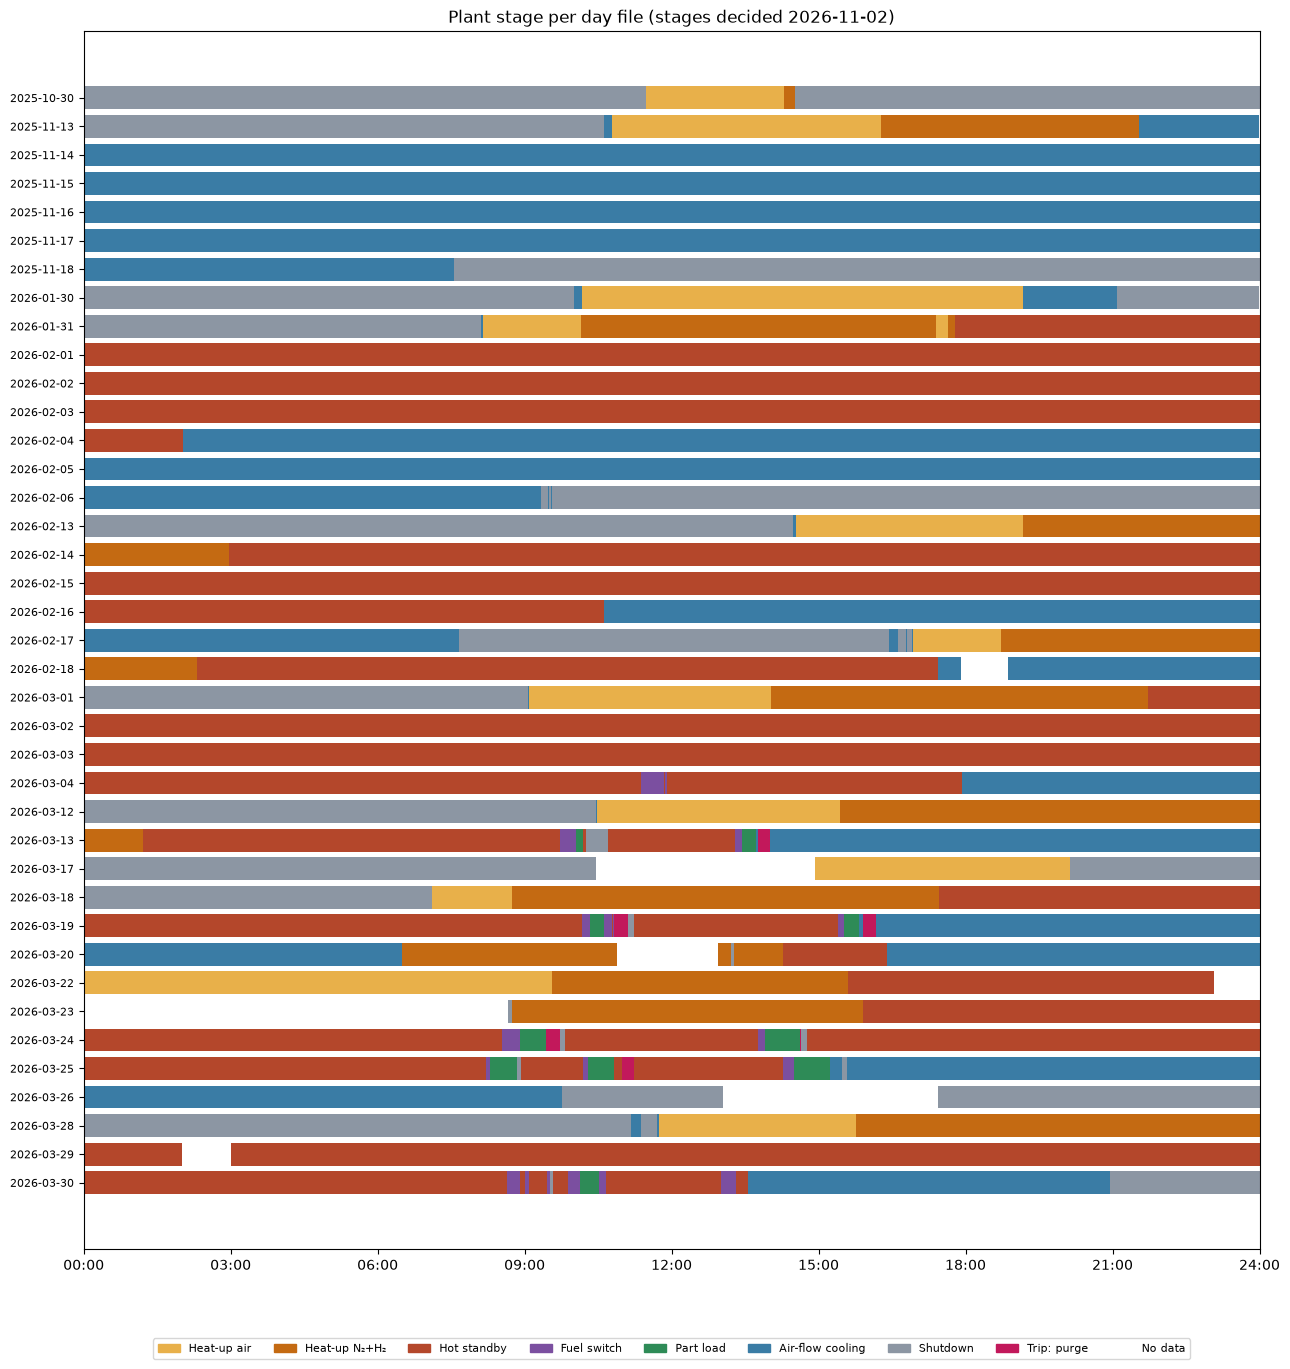

In [ ]:
fig, ax = plt.subplots(figsize=(13, 0.32 * len(all_days) + 1.2))
for row, d in enumerate(all_days):
    base = pd.Timestamp(d)
    day = plant.loc[base : base + pd.Timedelta("1D") - pd.Timedelta("1min")]
    for r in ps.blocks(day).itertuples():
        ax.barh(
            row,
            r.minutes / 60,
            left=(r.start - base) / pd.Timedelta("1h"),
            height=0.8,
            color=ps.COLORS[r.stage],
            edgecolor="none",
        )
ax.set_yticks(
    range(len(all_days)),
    [pd.Timestamp(d).strftime("%Y-%m-%d") for d in all_days],
    fontsize=8,
)
ax.invert_yaxis()
ax.set_xlim(0, 24)
ax.set_xticks(range(0, 25, 3), [f"{h:02d}:00" for h in range(0, 25, 3)])
ax.legend(
    handles=ps.legend_handles(ps.STAGES + ["No data"]),
    ncol=9,
    fontsize=8,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.03 - 1.5 / len(all_days)),
)
ax.set_title("Plant stage per day file (stages decided 2026-11-02)")
plt.tight_layout()
plt.show()

### 12.4 One run through all stages (2026-03-23 → 2026-03-25)

Stack temperature, cathode air, anode gases and string current, shaded by plant stage, with the stage band at the
bottom. The 210 °C line is the forming-gas rule of thumb.

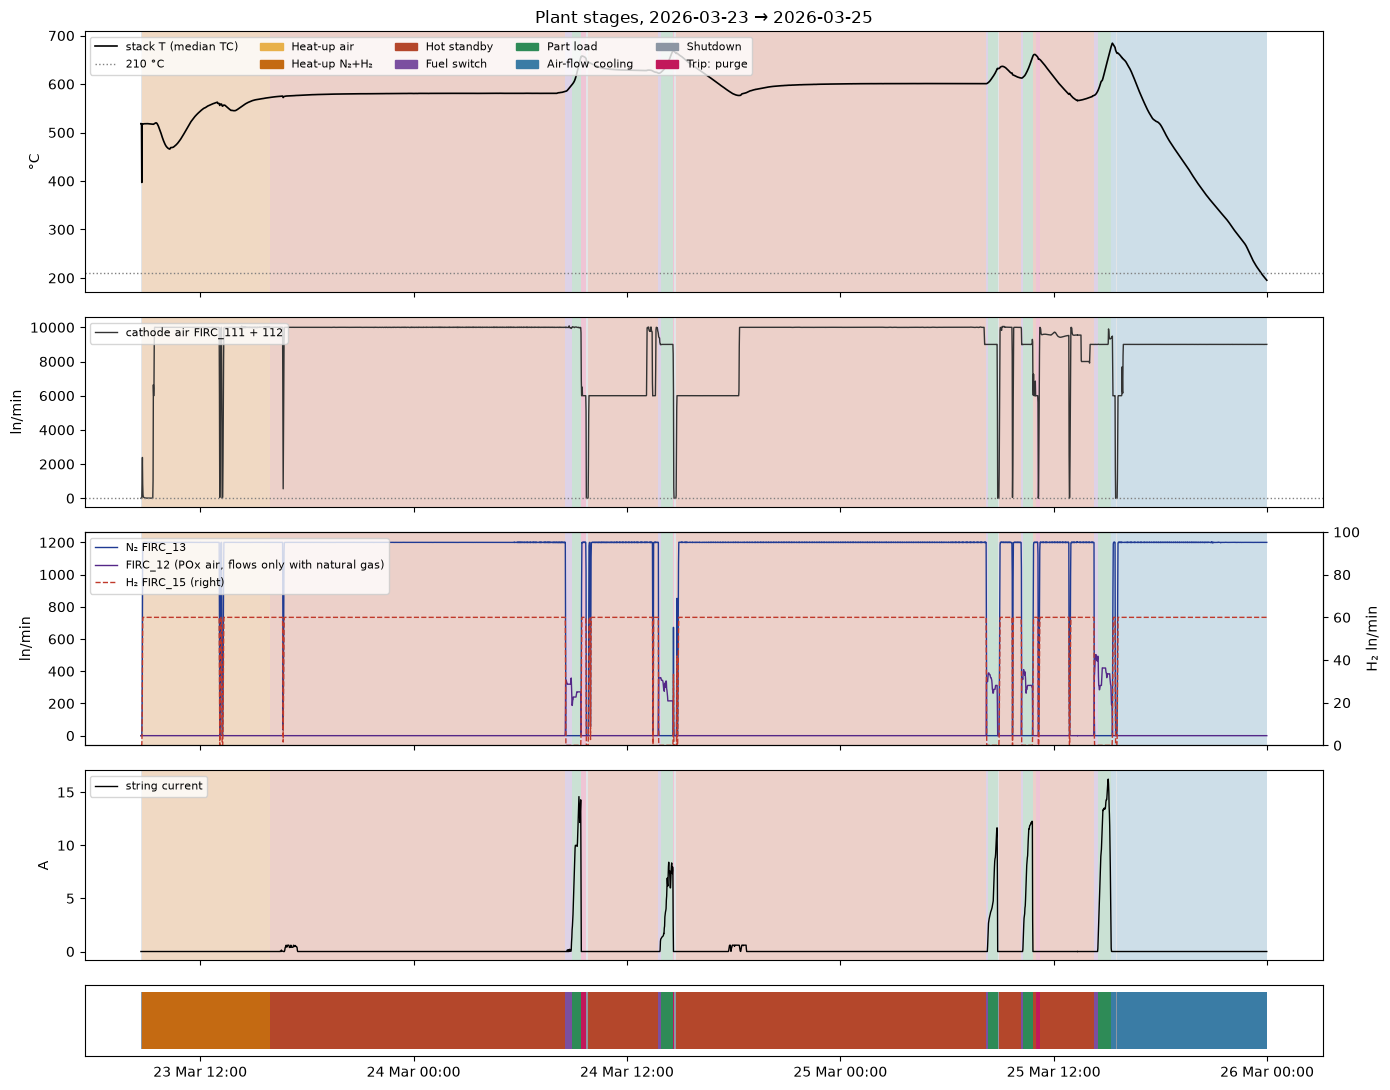

In [ ]:
import matplotlib.dates as mdates

win = plant.loc["2026-03-23":"2026-03-25"]
wb = ps.blocks(win)
fig, ax = plt.subplots(
    5,
    1,
    figsize=(14, 11),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.6, 1.8, 1.6, 0.6]},
)
for a in ax[:4]:
    for r in wb.itertuples():
        a.axvspan(r.start, r.end, color=ps.COLORS[r.stage], alpha=0.25, lw=0)
ax[0].plot(win.index, win.T_stack_C, "k", lw=1.2, label="stack T (median TC)")
ax[0].axhline(ps.T_FORMING, color="grey", ls=":", lw=1, label="210 °C")
ax[0].set_ylabel("°C")
ax[0].legend(fontsize=8, loc="upper left")
ax[1].plot(
    win.index,
    win.F_air,
    color=ops.GAS_COLORS["air"],
    lw=1,
    label="cathode air FIRC_111 + 112",
)
ax[1].axhline(ps.AIR_COOL, color="grey", ls=":", lw=1)
ax[1].set_ylabel("ln/min")
ax[1].legend(fontsize=8, loc="upper left")
ax[2].plot(win.index, win.F_N2, color=ops.GAS_COLORS["N2"], lw=1, label="N₂ FIRC_13")
ax[2].plot(
    win.index, win.F_NG, color=ops.GAS_COLORS["NG"], lw=1, label="FIRC_14 (natural gas)"
)
ax2 = ax[2].twinx()
ax2.plot(
    win.index,
    win.F_H2,
    color=ops.GAS_COLORS["H2"],
    lw=1,
    ls="--",
    label="H₂ FIRC_15 (right)",
)
ax2.set_ylim(0, 100)
ax2.set_ylabel("H₂ ln/min")
ax[2].set_ylabel("ln/min")
ax[2].legend(handles=ax[2].get_lines() + ax2.get_lines(), fontsize=8, loc="upper left")
ax[3].plot(win.index, win.I_string_A, color="k", lw=1, label="string current")
ax[3].set_ylabel("A")
ax[3].legend(fontsize=8, loc="upper left")
ps.plot_band(ax[4], wb)
ax[4].set_yticks([])
ax[4].set_ylim(-0.5, 0.5)
ax[4].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
ax[0].legend(
    handles=ax[0].get_lines() + ps.legend_handles(),
    ncol=5,
    fontsize=8,
    loc="upper left",
)
ax[0].set_title("Plant stages, 2026-03-23 → 2026-03-25")
plt.tight_layout()
plt.show()

### 12.5 Trips

Each trip window from §11 split by what the safety PLC did. A purge (or a power cut at the trip value, which is followed
by purge flows) is **Trip: purge**; an emergency stop is **Shutdown** until the air comes back on.

In [ ]:
rows = []
for _, w in windows.iterrows():
    m = plant.loc[w["start"] : w["end"]]
    rows.append(
        {
            "trip": w["trip"],
            "first cut": w["first cut"],
            "cuts": w["cuts"],
            **m.plant_stage.value_counts().reindex(
                [ps.PURGE, ps.SD, ps.AFC, ps.PL, ps.FS, ps.HS], fill_value=0
            ),
        }
    )
pd.DataFrame(rows).set_index("trip")

,first cut,cuts,Trip: purge,Shutdown,Air-flow cooling,Part load,Fuel switch,Hot standby
trip,,,,,,,,
1,2026-03-13 13:45:15,"Power cut at trip value, gas unchanged",15,0,1,0,0,0
2,2026-03-19 10:49:49,"Power cut at trip value, gas unchanged → Power...",16,8,0,0,1,7
3,2026-03-19 15:54:35,"Power cut at trip value, gas unchanged",15,0,1,0,0,0
4,2026-03-24 09:25:26,"EMERGENCY PURGE → Power cut at trip value, gas...",17,6,0,1,0,9
5,2026-03-24 14:36:22,EMERGENCY PURGE → EMERGENCY STOP,2,7,0,1,0,8
6,2026-03-25 08:50:37,EMERGENCY STOP,0,5,0,1,0,10
7,2026-03-25 10:58:26,"Power cut at trip value, gas unchanged",15,0,0,0,0,1
8,2026-03-25 15:28:17,EMERGENCY STOP,0,6,10,0,0,0
9,2026-03-30 09:30:57,EMERGENCY STOP,0,4,0,0,1,11


### 12.6 Rule of thumb: stack > 210 °C → N₂ + H₂ on

The forming gas is predicted on when the stack is above 210 °C and no natural gas flows, and compared with the measured
N₂ and H₂ flows (thresholds as in the gas band, N₂ > 100, H₂ > 5 ln/min).

In [ ]:
agree, by_stage = ps.rule_210_check(plant)
print(f"rule agrees on {agree:.1f} % of the labelled minutes")
by_stage

rule agrees on 96.1 % of the labelled minutes


,minutes,agree_pct,forming_gas_on_pct,above_210_pct
stage,,,,
Heat-up air,3376,77.3,0.0,22.7
Heat-up N₂+H₂,4892,99.1,99.9,99.2
Hot standby,20269,99.9,99.9,100.0
Fuel switch,209,87.1,12.9,100.0
Part load,268,99.3,0.7,100.0
Air-flow cooling,15292,93.2,52.7,54.3
Shutdown,10424,97.6,0.0,2.4
Trip: purge,80,93.8,92.5,100.0


### 12.7 Minutes per plant stage and day, and saved files

In [ ]:
pminutes = ps.per_day(plant)
pminutes.loc["TOTAL"] = pminutes.sum()
display(pminutes)

ps.OUT.mkdir(exist_ok=True)
plant[
    [
        "T_stack_C",
        "I_string_A",
        "F_air",
        "F_N2",
        "F_H2",
        "F_NG",
        "phase",
        "stage",
        "sub_stage",
        "operation",
        "plant_stage",
    ]
].to_parquet(ps.OUT / "plant_stages_1min.parquet")
pblocks.to_csv(ps.OUT / "plant_stage_blocks.csv", index=False)
pminutes.to_csv(ps.OUT / "plant_stage_minutes_per_day.csv")
ps.transitions(pepis).to_csv(ps.OUT / "plant_stage_transitions.csv")
sorted(p.name for p in ps.OUT.glob("*"))

plant_stage,Heat-up air,Heat-up N₂+H₂,Hot standby,Fuel switch,Part load,Air-flow cooling,Shutdown,Trip: purge,No data
day,,,,,,,,,
2025-10-30,169,13,0,0,0,0,1258,0,0
2025-11-13,330,315,0,0,0,158,637,0,0
2025-11-14,0,0,0,0,0,1440,0,0,0
2025-11-15,0,0,0,0,0,1440,0,0,0
2025-11-16,0,0,0,0,0,1440,0,0,0
2025-11-17,0,0,0,0,0,1440,0,0,0
2025-11-18,0,0,0,0,0,453,987,0,0
2026-01-30,540,0,0,0,0,126,774,0,0
2026-01-31,134,444,373,0,0,2,487,0,0


['plant_stage_blocks.csv',
 'plant_stage_minutes_per_day.csv',
 'plant_stage_transitions.csv',
 'plant_stages_1min.parquet']

### 12.8 What the plant stages show

* **Time split (39 day files, 926 h):** Hot standby 338 h (37 %), Air-flow cooling 255 h (28 %), Shutdown 174 h
  (19 %), Heat-up N₂+H₂ 82 h, Heat-up air 56 h, Part load 4.5 h, Fuel switch 3.5 h, Trip: purge 1.3 h, no data 13 h.
* **The labels agree with the devices-on check** of 2026-11-02: Air-flow cooling 15,292 min there 15,239, Trip: purge
  80 min there 77 (the small differences are the minutes around each trip).
* **Main path seen in the data:** Heat-up air → Heat-up N₂+H₂ (11 of 14) → Hot standby (9 of 14) → Fuel switch
  (17 times) → Part load (10 of 19 fuel switches). After Part load: Air-flow cooling 3, a trip 2, Shutdown 1, back to Hot standby /
  Fuel switch 4.
* **Fuel switch without power:** 7 of 19 fuel switches went back to Hot standby without any current.
* **Emergency stops** (trips 2, 4, 5, 6, 8, 9) show 4–8 min of Shutdown before the air comes back. After that, 7 times
  the plant went back to Hot standby (forming gas on, stack 570–660 °C), not straight to Air-flow cooling.
* **210 °C rule** holds on 96.1 % of the minutes. It is weakest in Heat-up air (77 %: the forming gas came on later than
  210 °C in some heat-ups) and in Air-flow cooling (93 %: N₂ + H₂ stopped at 210–290 °C, and on 2026-03-25 → 26 they
  stayed on down to 69 °C).
* **Open points**
  1. 44 minutes of air at a cold stack before a heat-up (e.g. 2025-11-13, 2026-01-30) are filed as Air-flow cooling
     because the older label is Shut-down at ambient. Should they count as Heat-up air?
  2. Thermal adjustment (re-heat / cool-back, 44 h) is inside Hot standby. Keep it merged, or show it as a sub-step?
  3. The stages are not split at 210 °C yet; the rule is only checked.

### 12.9 Stage-deciding sensors, plant stages and gas flows, all days

The same figures as 9.4b (one per stretch of consecutive day files, 9 stretches, all 39 days), now shaded with the
**eight plant stages** of section 12 instead of the older stages. From top to bottom:

1. **Temperature**: stack T (median of the healthy `TIR_4_6_*`), cathode inlet `TIRC_2_06`, ambient proxy + 30 K.
   Dotted lines at **210 °C** (forming gas on above it, rule 12.6), 450 °C and 550 °C.
2. **dT/dt** of stack T, 20-min centred (±10 °C/h dashed, ±5 °C/h dotted).
3. **EAPH heater power** `EIRC_2_01` and **string current** `EIRC41…45` (green, right axis; ≥ 1 A = Part load).
4. **Stack inlet pressure** `PIR_2_02` (air on > 1).
5. **Lanes**: plant stage, then the measured flows of air, POx air, N₂, H₂ (10 s data, same full scale on every figure),
   natural gas `FIRC_14` (filled above 20 ln/min) and gas overlaps. The air lane has a second dotted line (blue) at
   **20 ln/min**: above it a Shut-down counts as Air-flow cooling.

Overlap labels use the plant-stage abbreviations: HA Heat-up air · HF Heat-up N₂+H₂ · HS Hot standby ·
FS Fuel switch · PL Part load · AFC Air-flow cooling · SD Shutdown · TP Trip: purge · – No data.

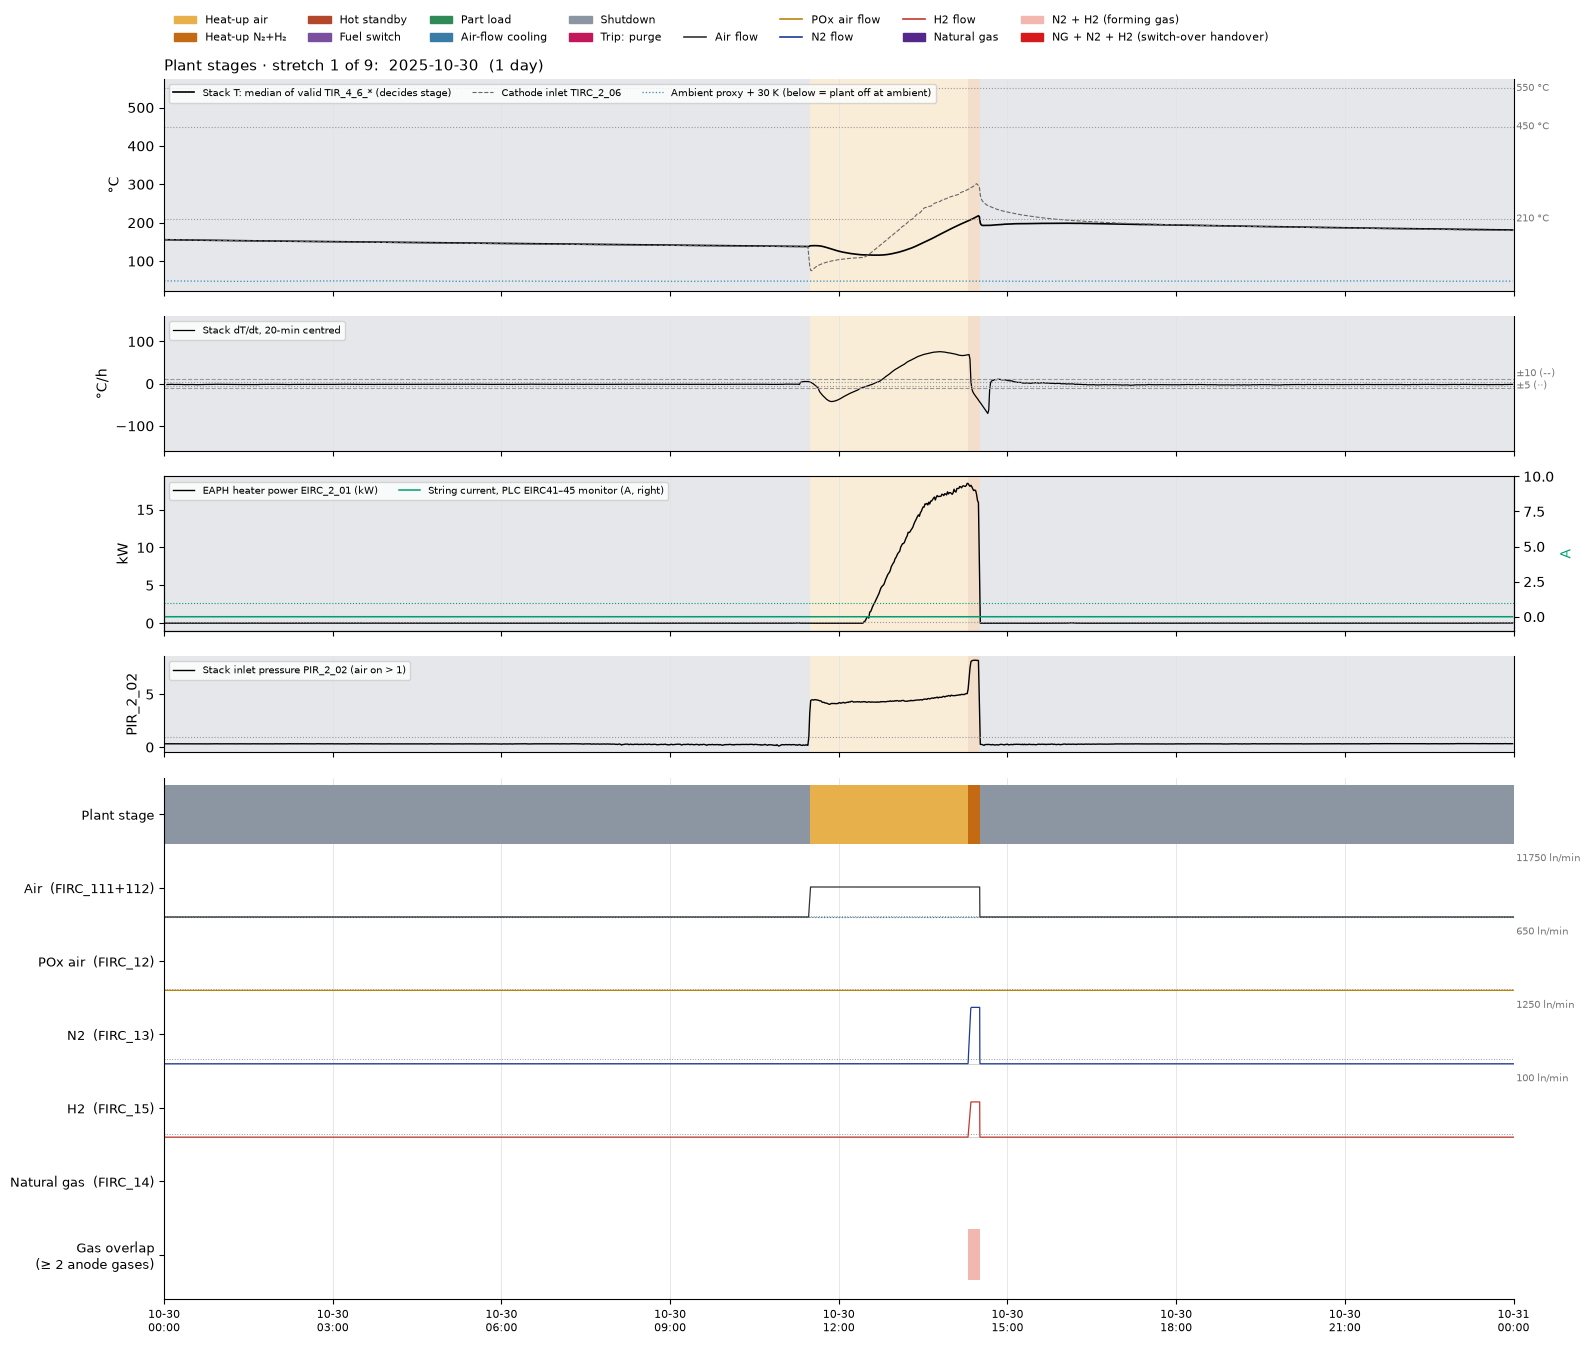

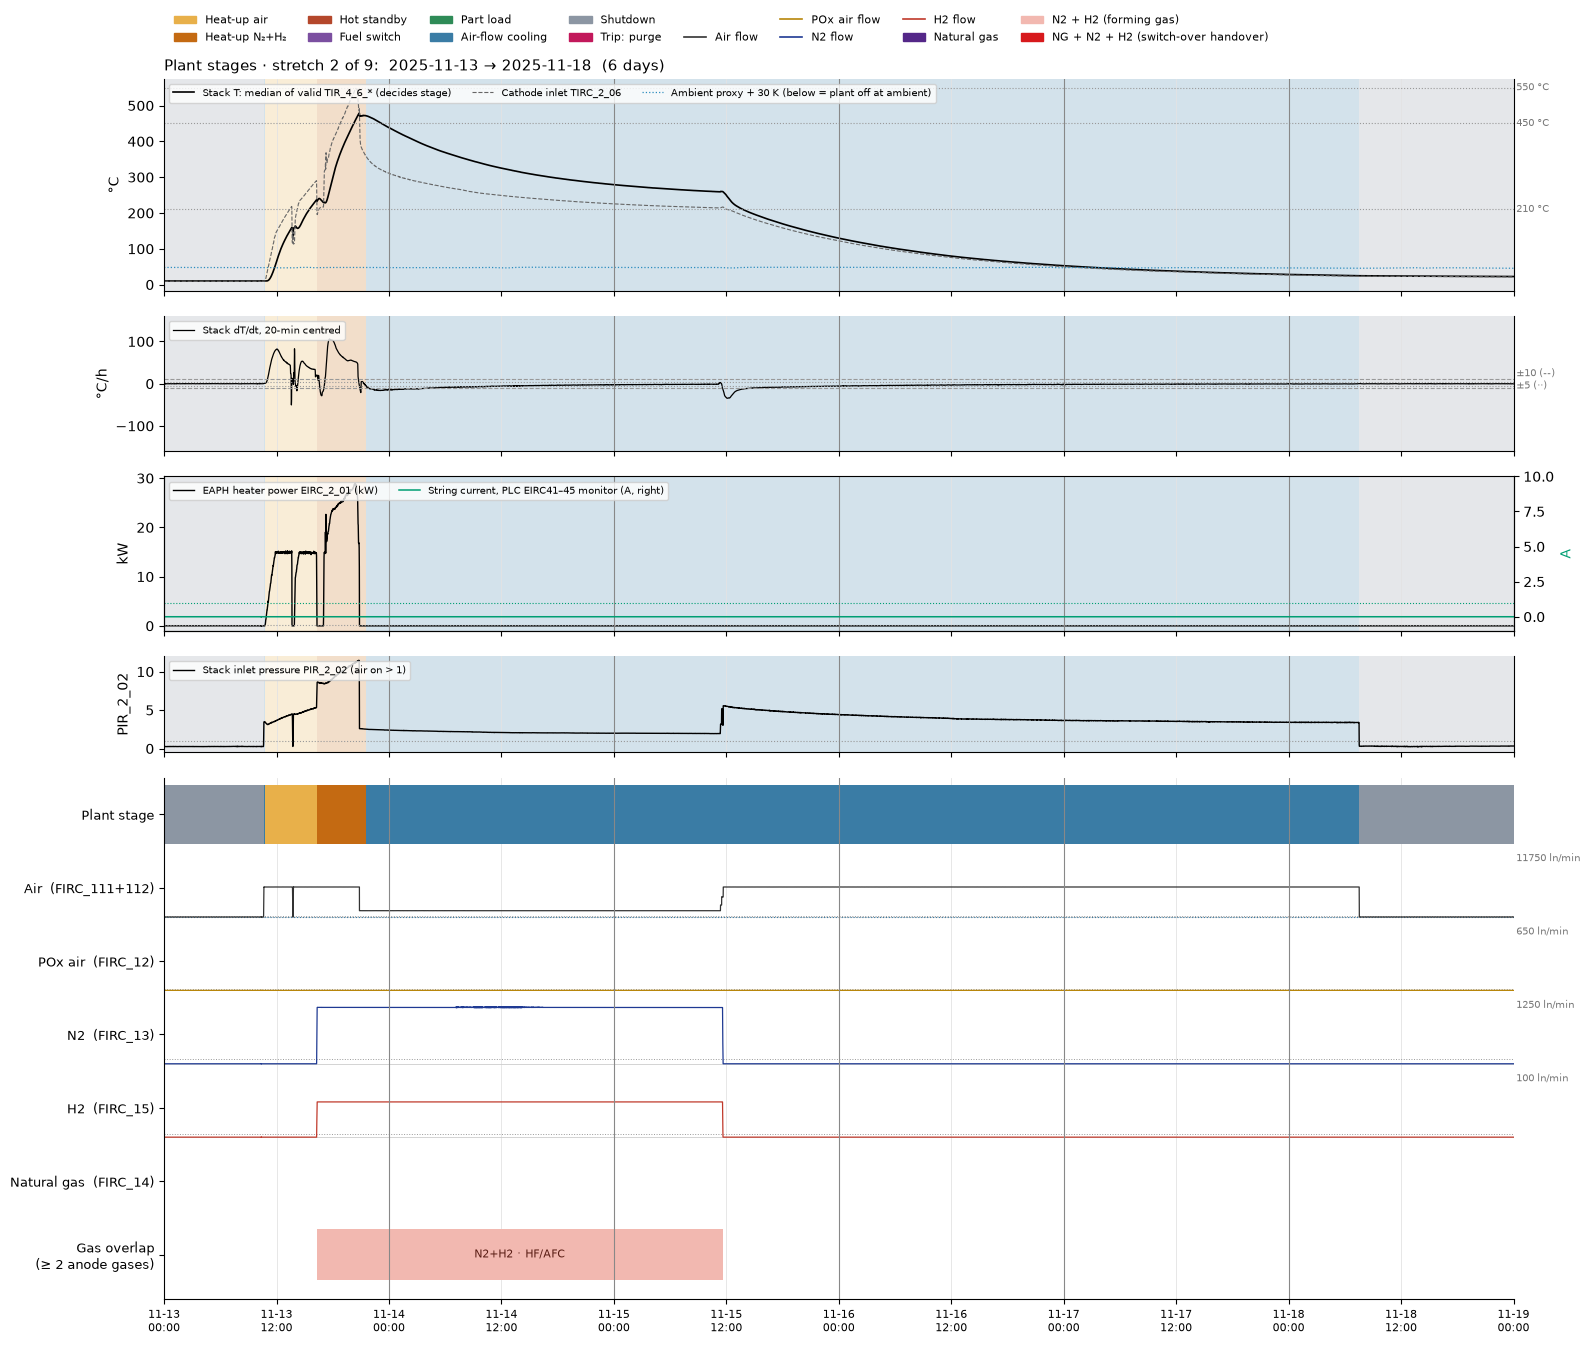

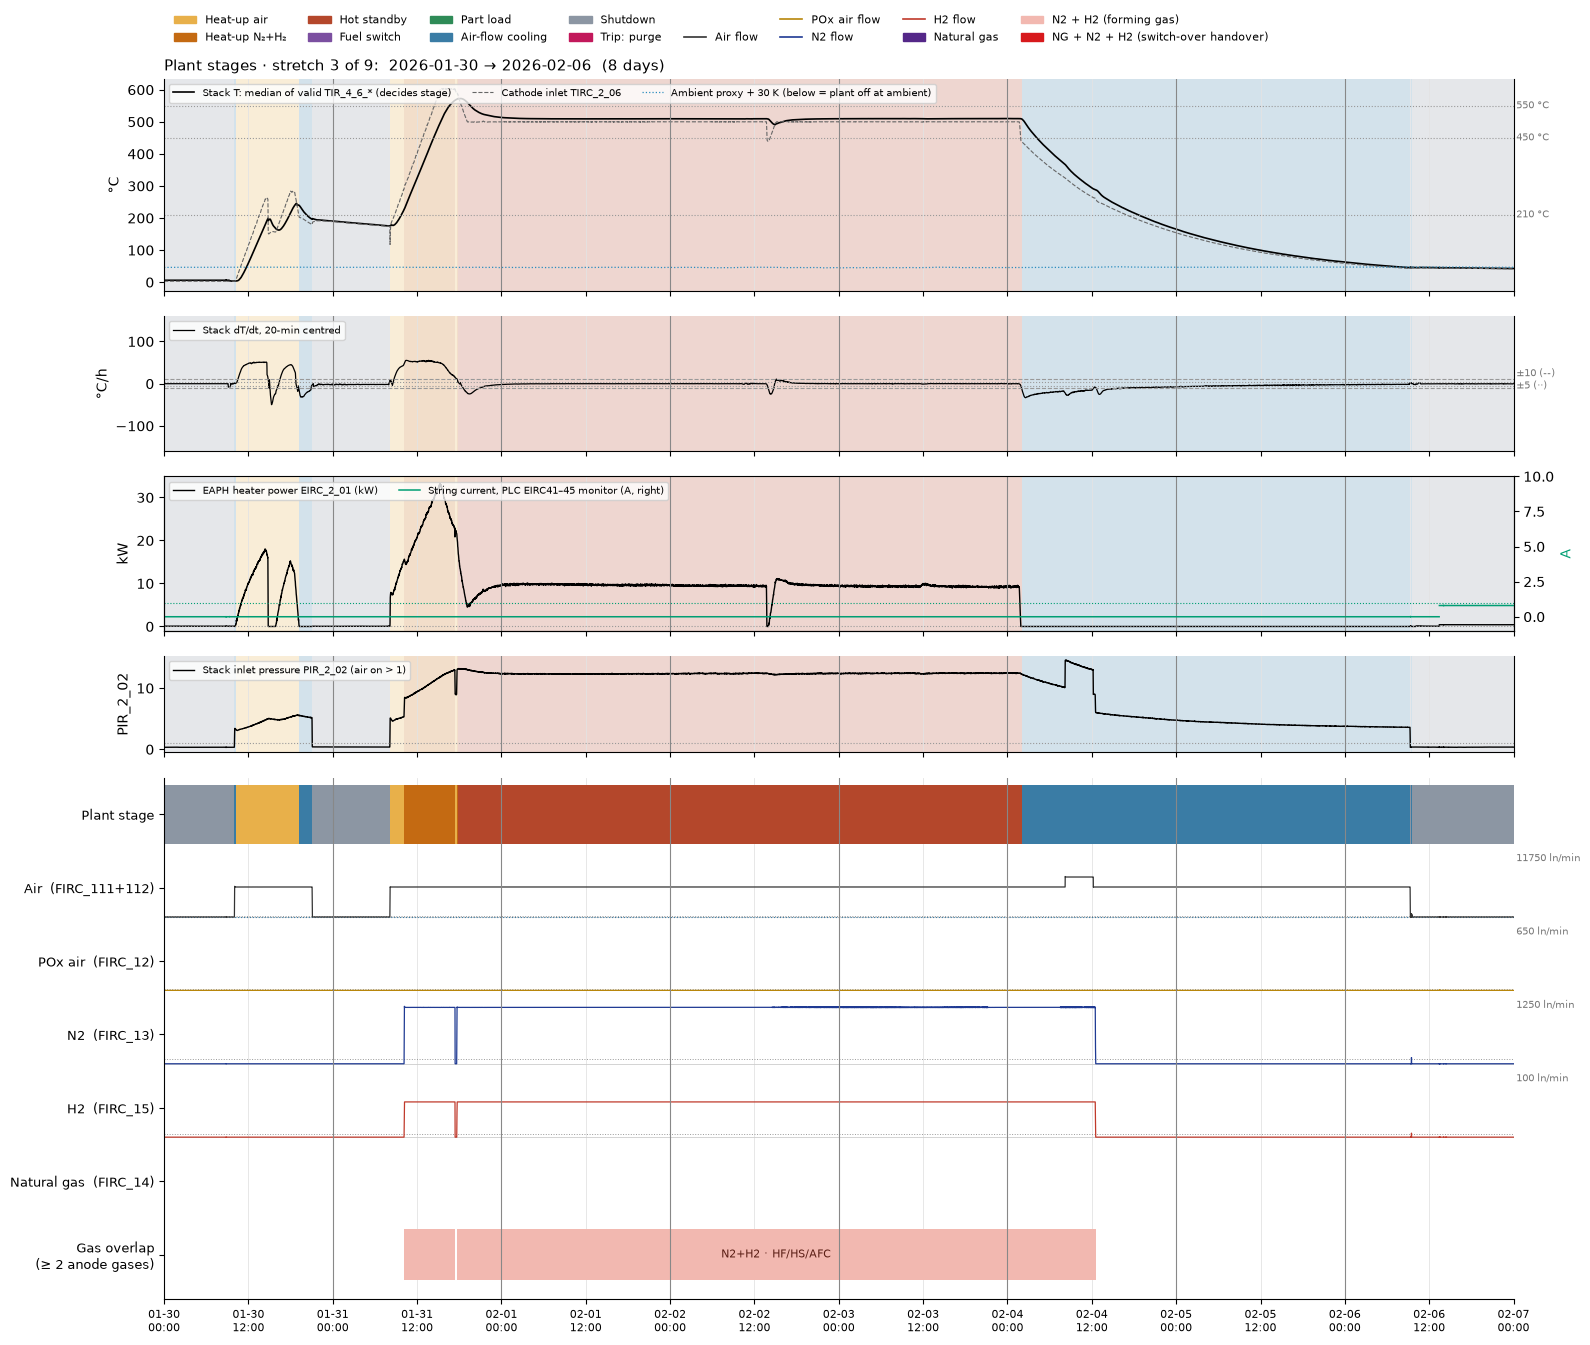

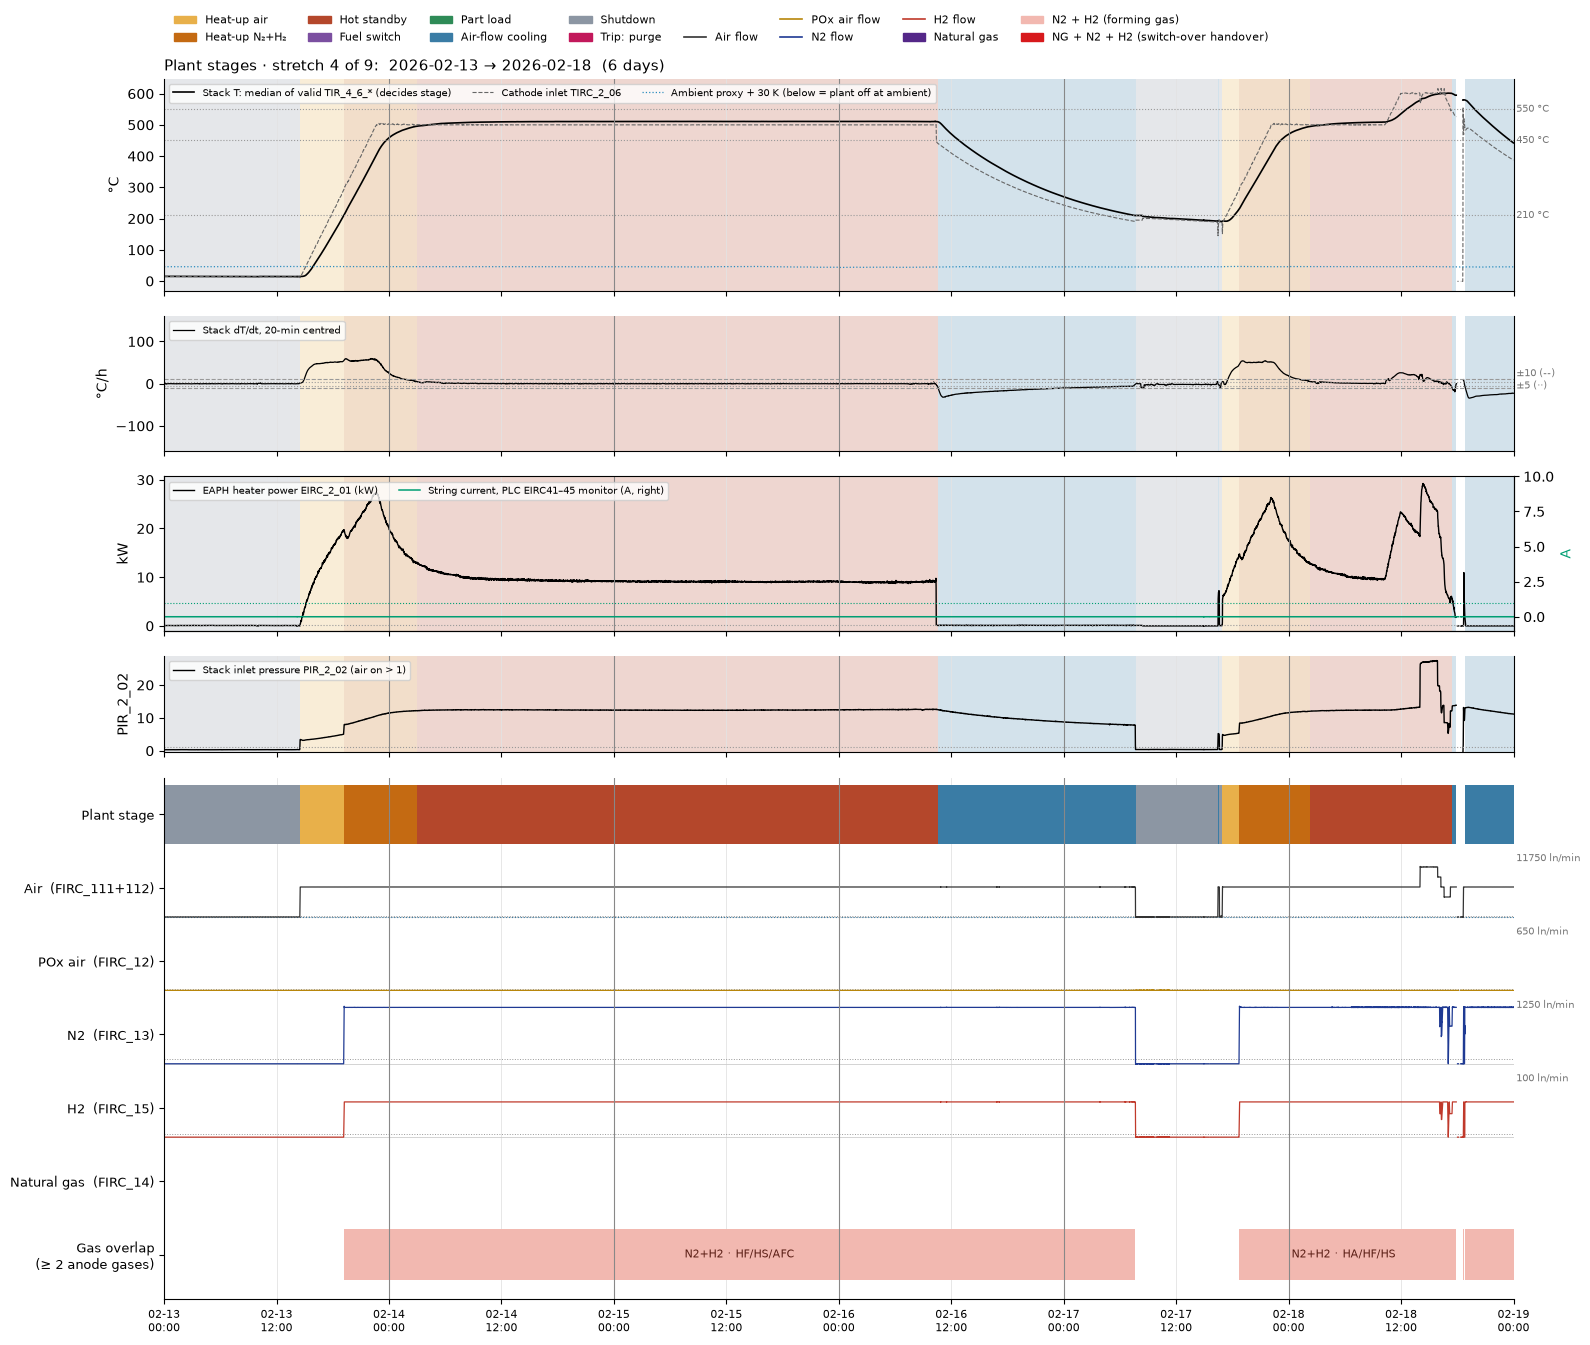

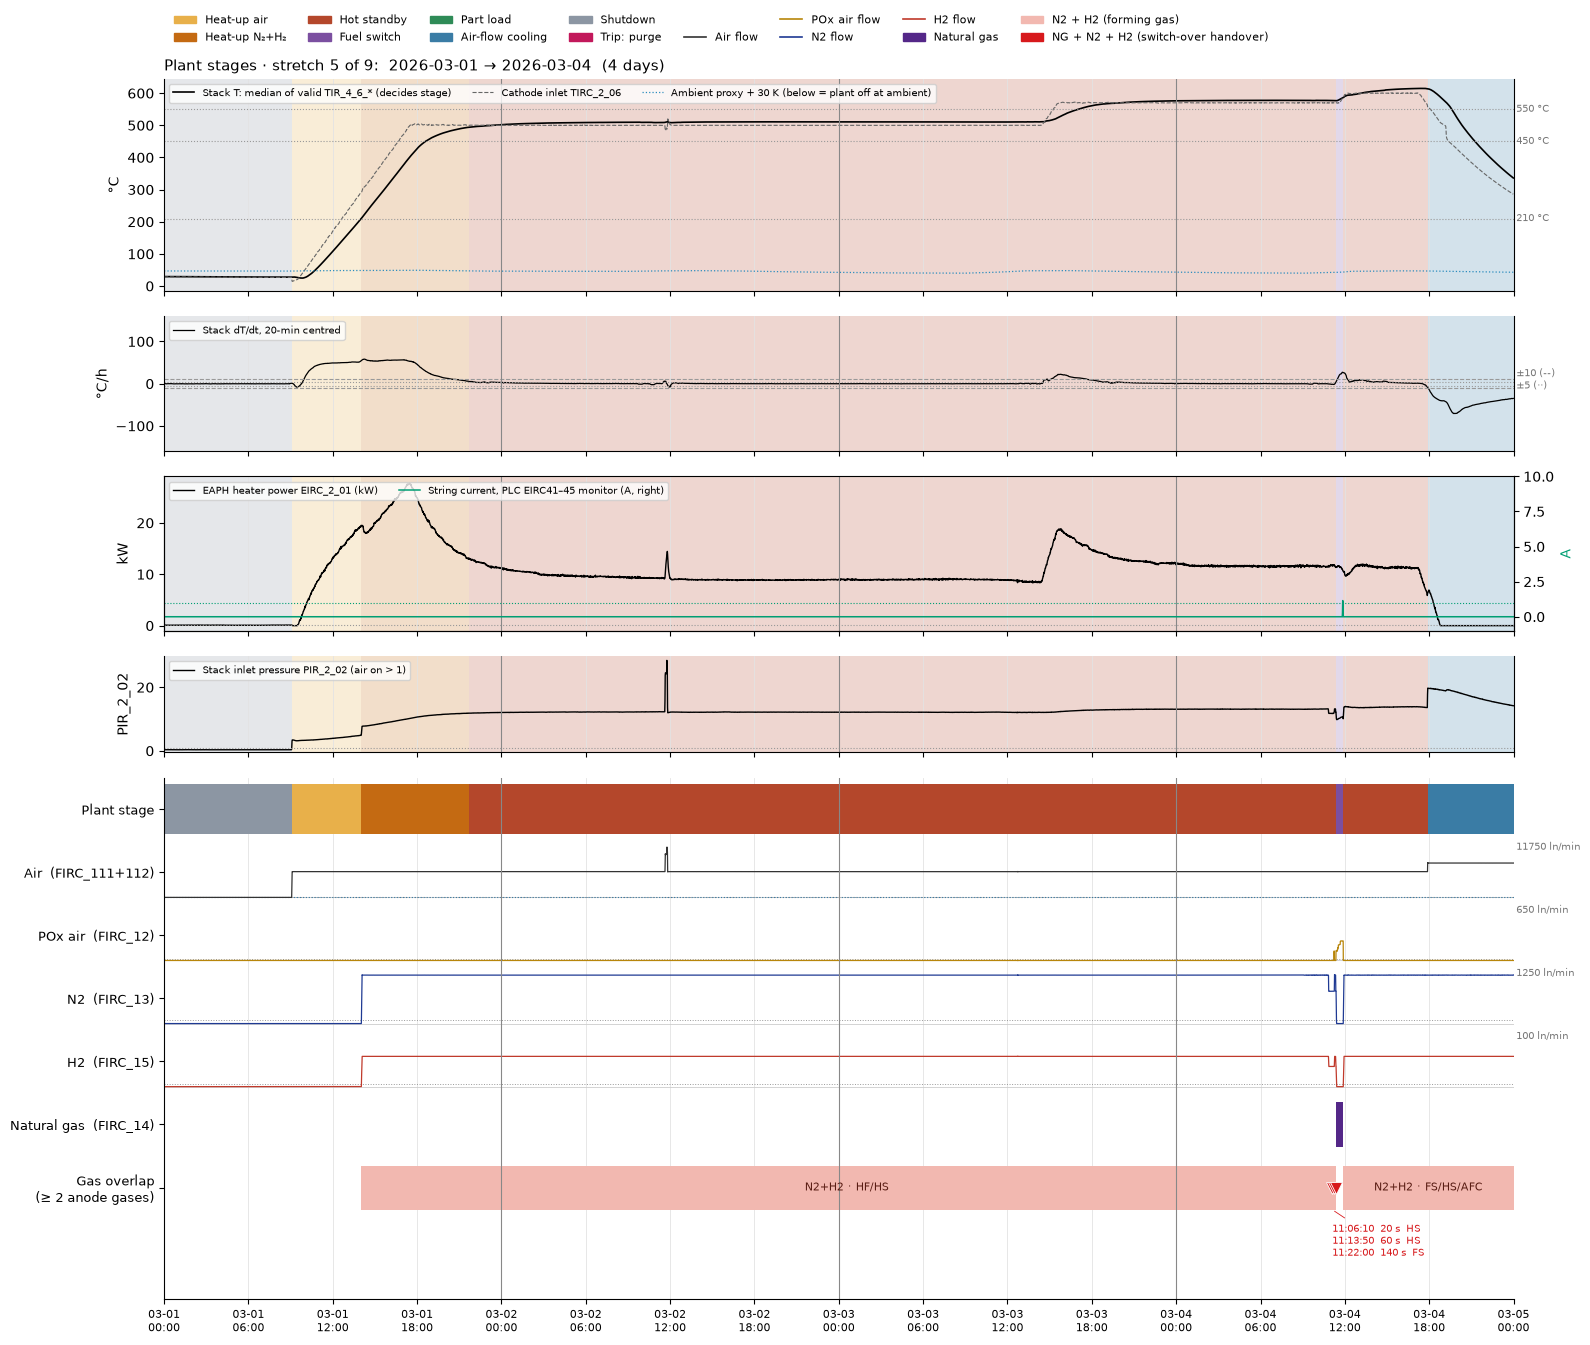

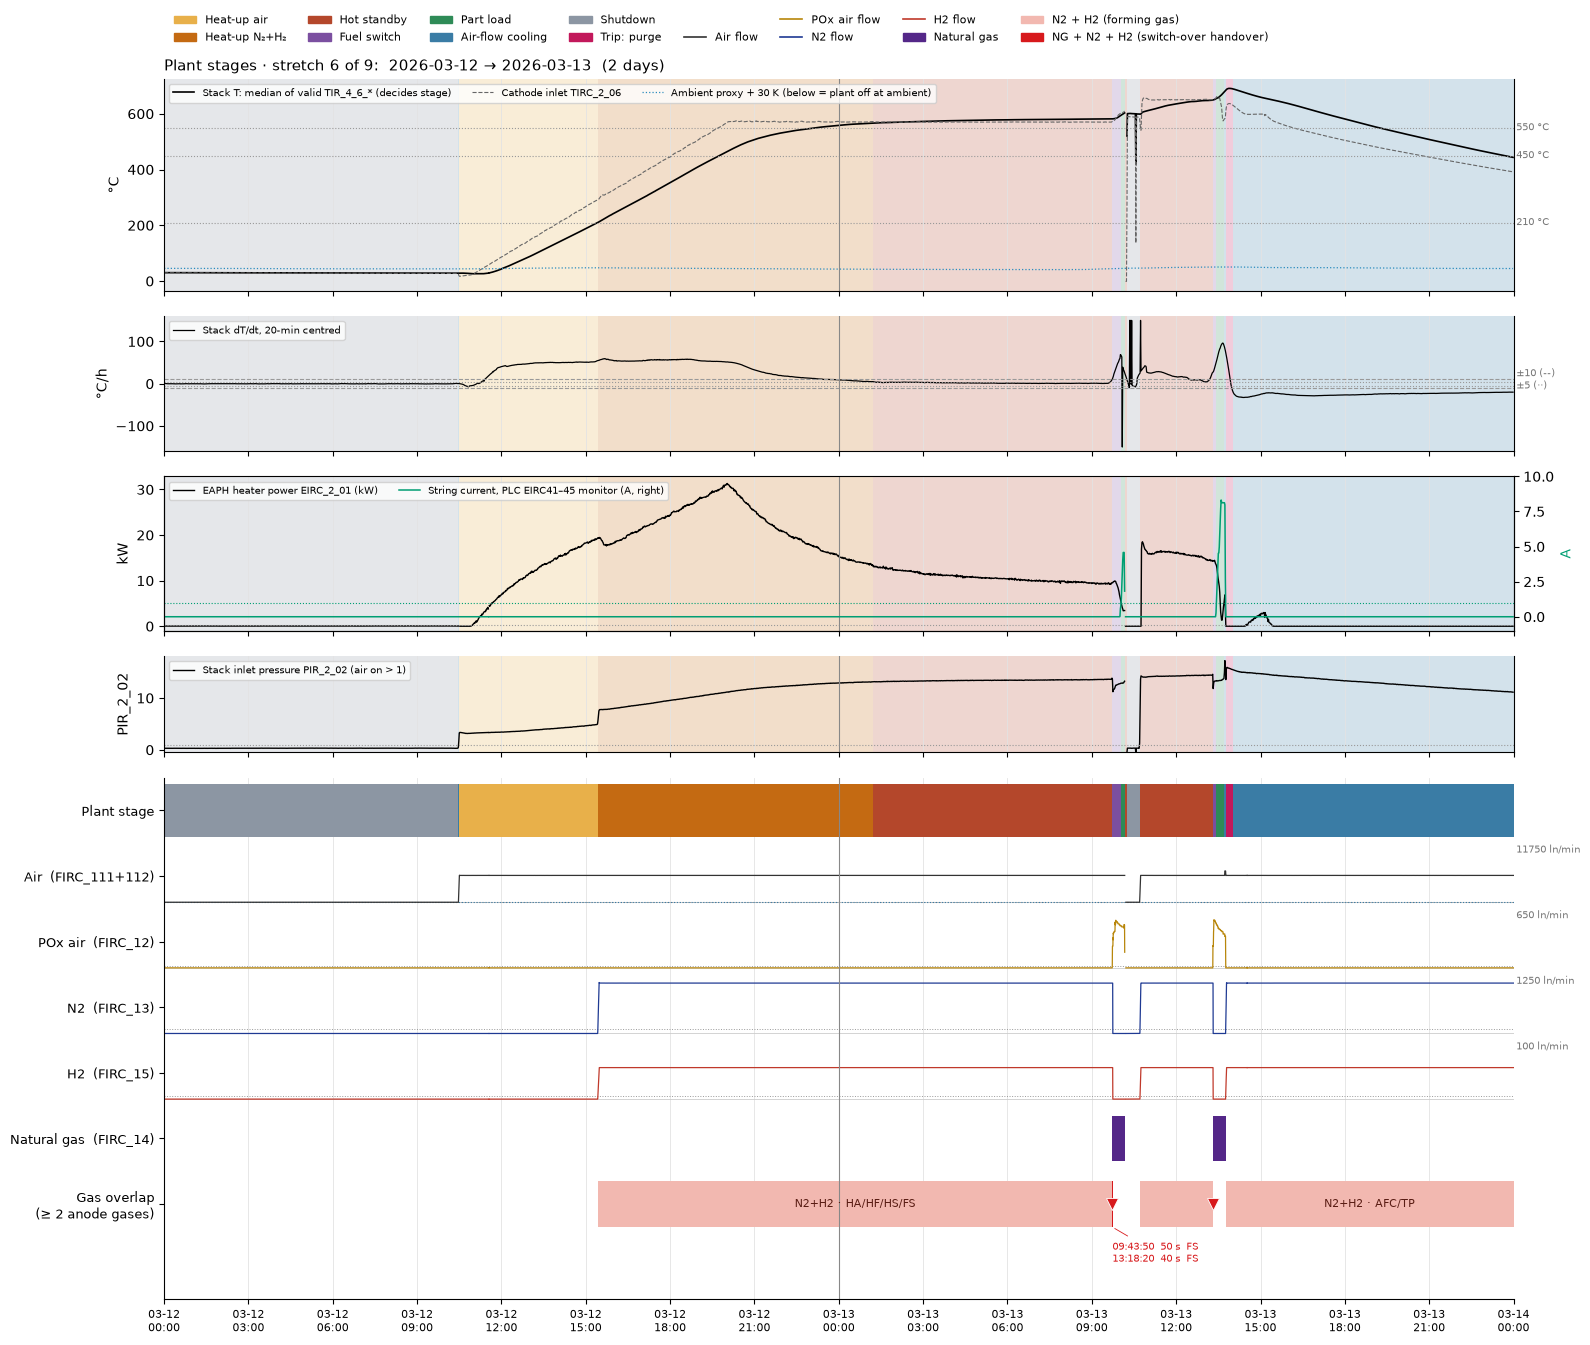

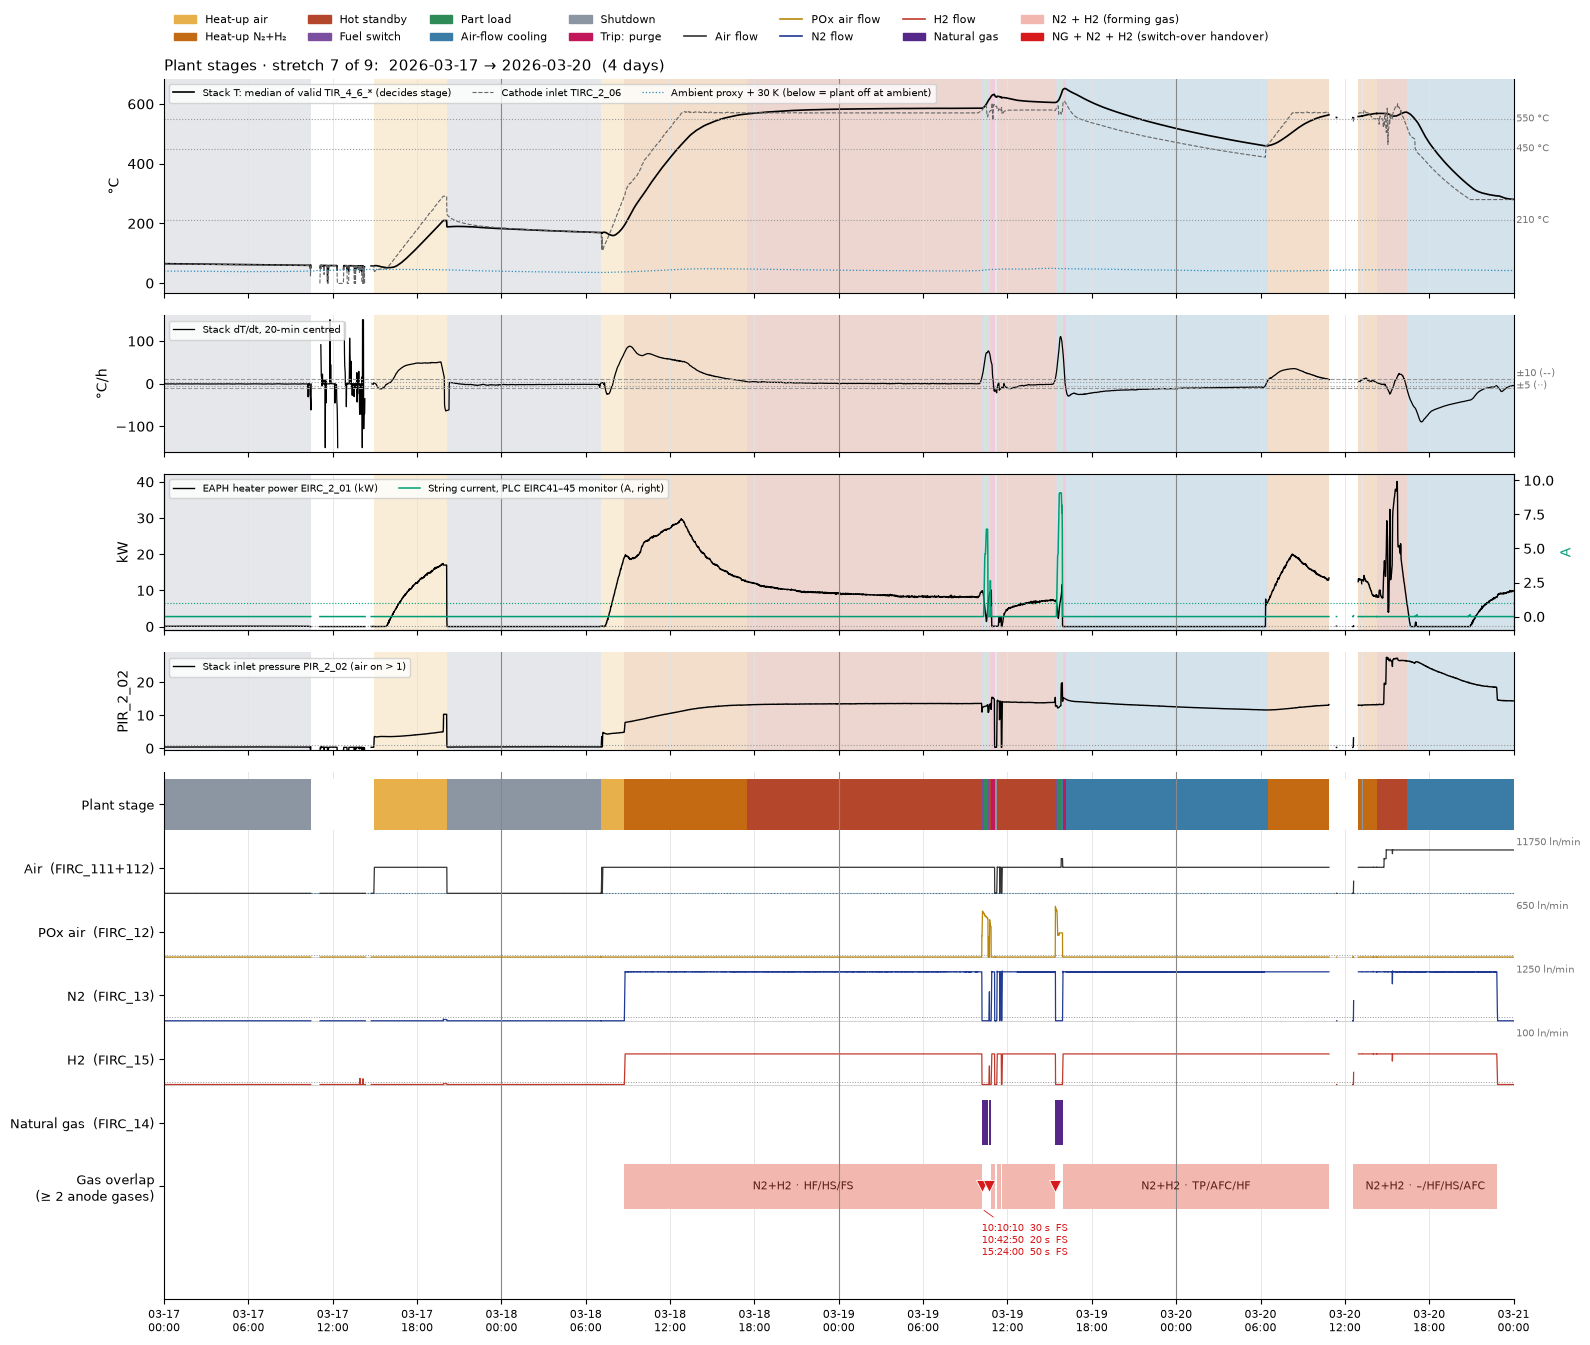

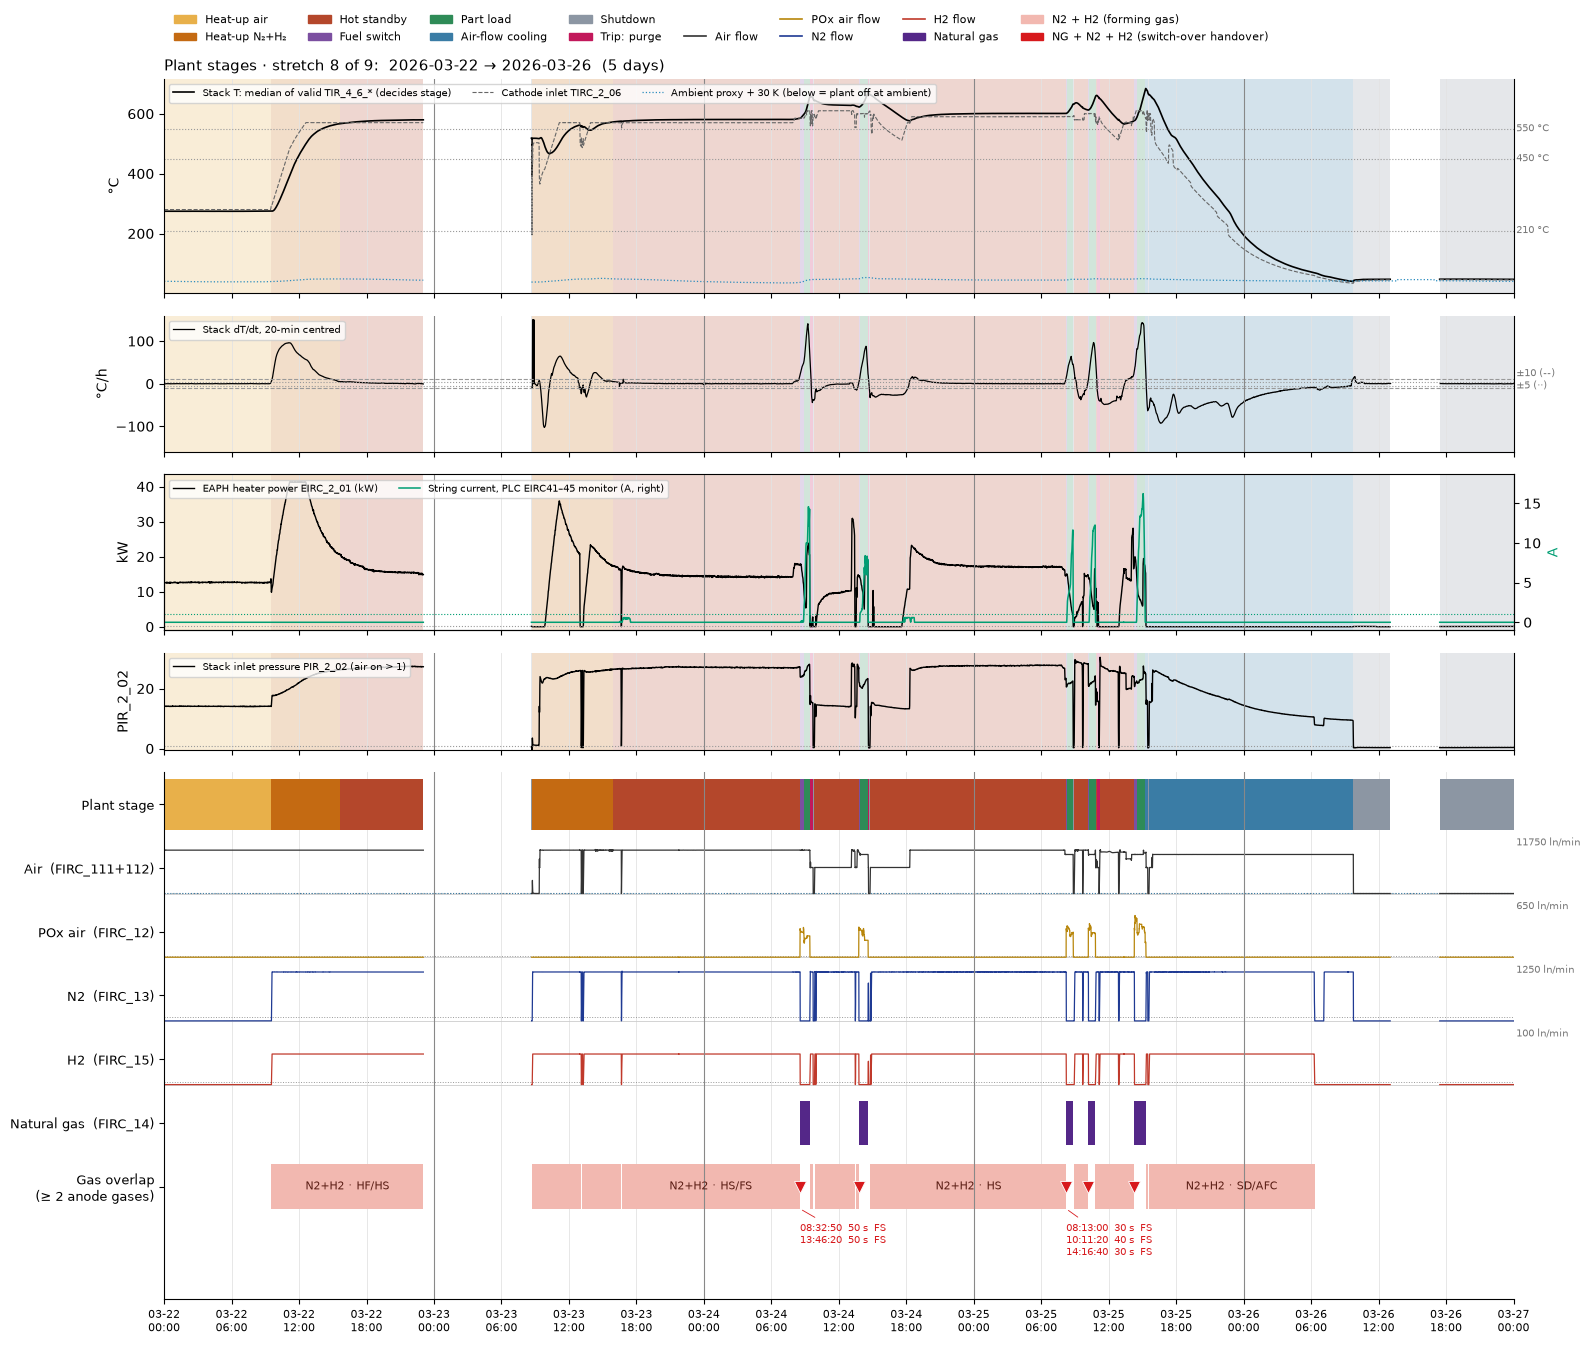

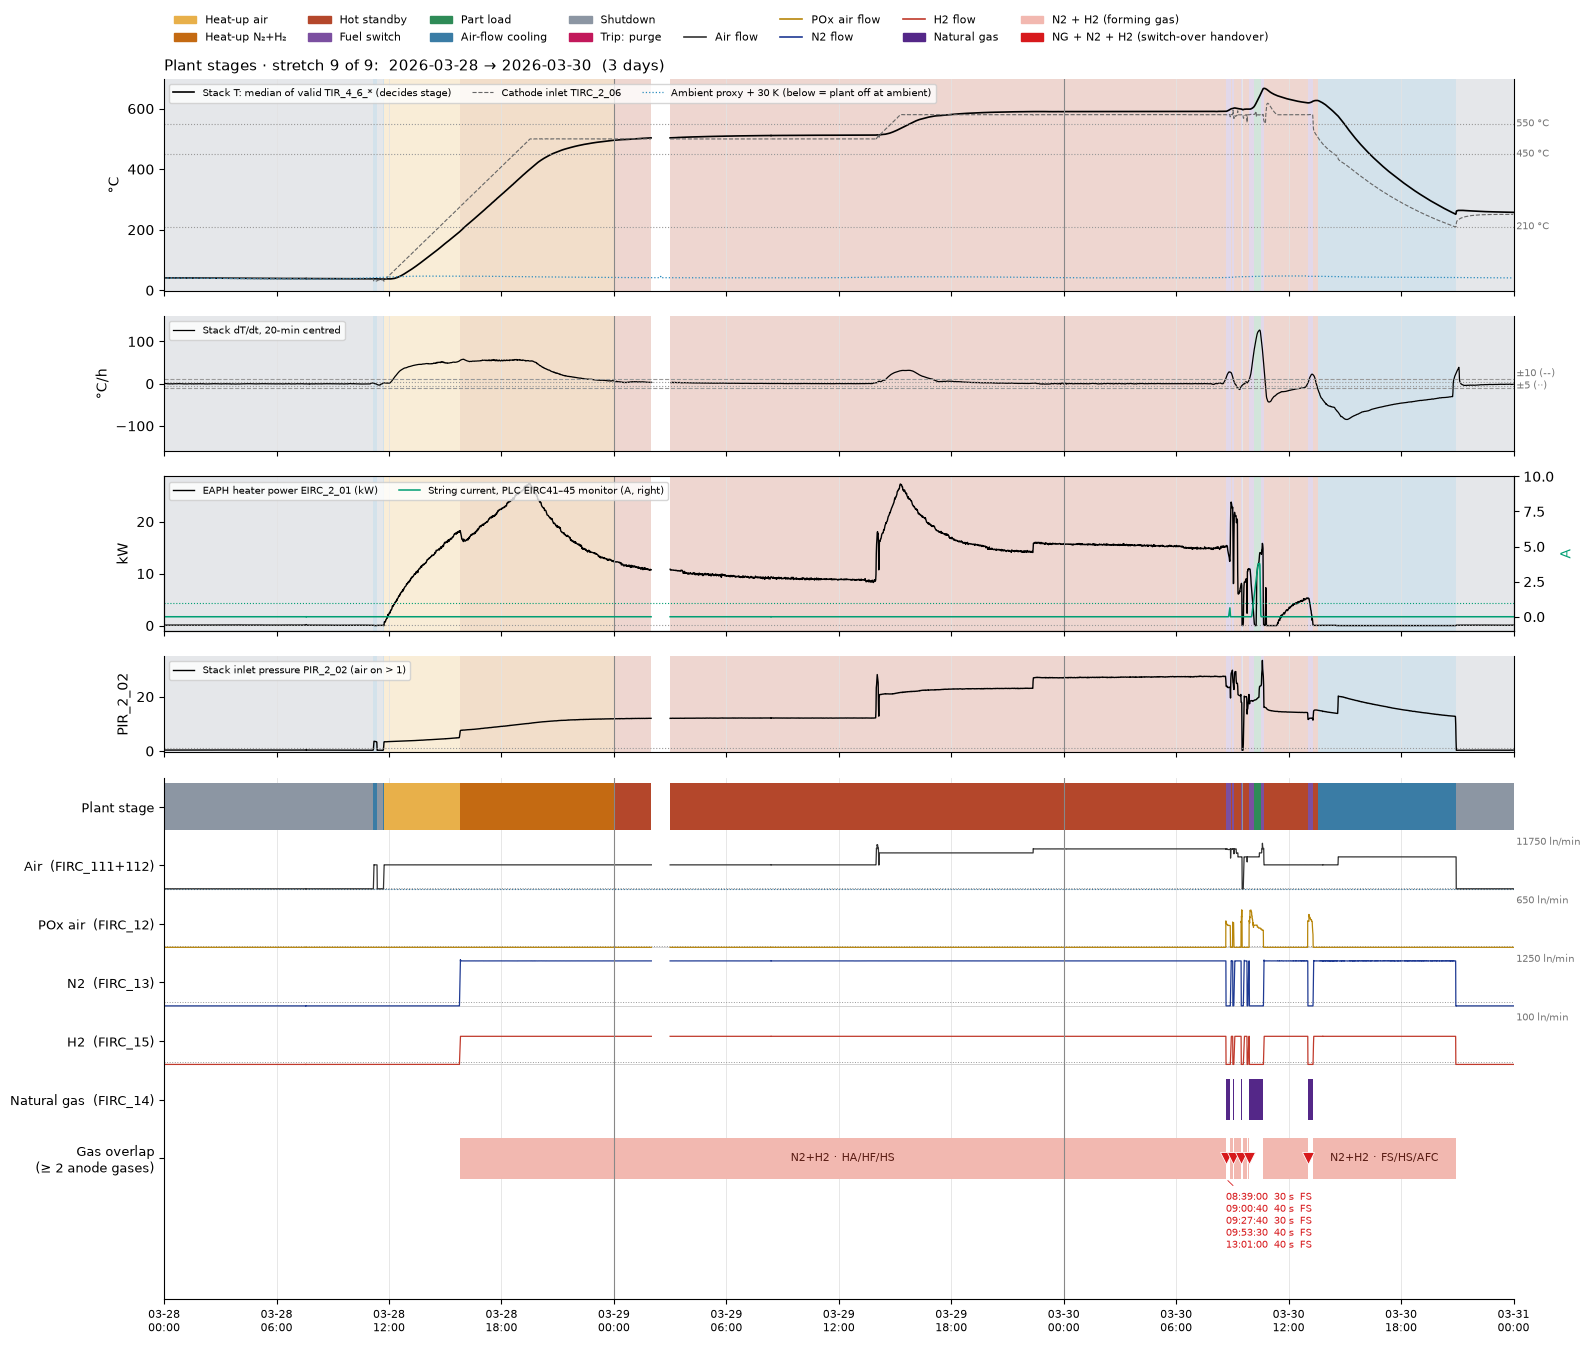

Labels:  HA Heat-up air · HF Heat-up N2+H2 · HS Hot standby · FS Fuel switch · PL Part load · AFC Air-flow cooling · SD Shutdown · TP Trip: purge


In [ ]:
# Same layout as 9.4b (reuses gas_on_10s, runs, sensor_panels, groups, GASES, FULL from
# there), shaded by plant stage
PSHORT = {
    ps.HEAT_AIR: "HA",
    ps.HEAT_FG: "HF",
    ps.HS: "HS",
    ps.FS: "FS",
    ps.PL: "PL",
    ps.AFC: "AFC",
    ps.SD: "SD",
    ps.PURGE: "TP",
    "No data": "–",
}
pgas10 = {
    d: gas_on_10s(d, plant.loc[all_days[d][0].index, "plant_stage"]) for d in days
}

p_legend = (
    ps.legend_handles(ps.STAGES)
    + [mpatches.Patch(color="none", label="   ")]
    + [Line2D([], [], color=GASES[g][2], lw=1.2, label=f"{g} flow") for g in TRACED]
    + [mpatches.Patch(color=GASES["NG"][2], label="Natural gas")]
    + [
        mpatches.Patch(color=OVERLAP_COLORS["N2 + H2"], label="N2 + H2 (forming gas)"),
        mpatches.Patch(color="#D7191C", label="NG + N2 + H2 (switch-over handover)"),
    ]
)

for gi, grp in enumerate(groups, 1):
    t0, t1 = pd.Timestamp(grp[0]), pd.Timestamp(grp[-1]) + pd.Timedelta("1D")
    fig, axs = plt.subplots(
        5,
        1,
        figsize=(16, 13.5),
        sharex=True,
        gridspec_kw={"height_ratios": [2.2, 1.4, 1.6, 1.0, 5.4]},
    )
    ax = axs[-1]
    st_1m = pd.concat([all_days[d][0] for d in grp])
    st_1m = st_1m.reindex(pd.date_range(t0, t1, freq="1min", inclusive="left"))
    seg = ps.blocks(plant.loc[st_1m.index.intersection(plant.index)])
    sensor_panels(
        axs[:4], st_1m, seg.iloc[:0]
    )  # sensors only; shading below uses the plant stages
    axs[0].axhline(ps.T_FORMING, color="#999", ls=":", lw=0.8)
    axs[0].text(
        1.002,
        ps.T_FORMING,
        f"{ps.T_FORMING:.0f} °C",
        transform=axs[0].get_yaxis_transform(),
        fontsize=7,
        color="#777",
        va="center",
    )
    for r in seg.itertuples():
        for a in axs[:4]:
            a.axvspan(
                r.start,
                r.end,
                color=ps.COLORS.get(r.stage, "#fff"),
                alpha=ops.STAGE_TINT,
                lw=0,
            )
    ps.plot_band(ax, seg, y=Y["Stage"])
    on = pd.concat([pgas10[d] for d in grp])
    ax.broken_barh(
        [span(a, b) for _, a, b, _ in runs(on["NG"], on.index)],
        (Y["NG"] - 0.35, 0.7),
        color=GASES["NG"][2],
        lw=0,
    )
    for g in TRACED:
        f = on[f"F_{g}"].resample("10s").mean()

        def to_lane(v):
            return Y[g] - 0.4 + 0.8 * v / FULL[g]

        ax.axhline(Y[g] - 0.4, color="#ccc", lw=0.6)
        ax.axhline(to_lane(GASES[g][1]), color="#999", ls=":", lw=0.7)
        if g == "Air":
            ax.axhline(
                to_lane(ps.AIR_COOL), color=ps.COLORS[ps.AFC], ls=":", lw=0.8
            )  # Air-flow cooling limit
        ax.plot(f.index, to_lane(f.clip(lower=0)), color=GASES[g][2], lw=0.9)
        ax.text(
            1.002,
            Y[g] + 0.4,
            f"{FULL[g]:.0f} ln/min",
            transform=ax.get_yaxis_transform(),
            fontsize=7,
            color="#777",
            va="center",
        )
    ovr = list(runs(on["overlap"], on.index))
    for lab, a, b, n in ovr:
        ax.broken_barh(
            [span(a, b)],
            (Y["Overlap"] - 0.35, 0.7),
            color=OVERLAP_COLORS.get(lab, "#FDAE61"),
            lw=0,
        )
        if "NG" not in lab and (b - a) / (t1 - t0) >= 0.06:
            stages = dict.fromkeys(
                on.loc[a : b - pd.Timedelta("10s"), "stage"].dropna()
            )
            ax.text(
                num(a + (b - a) / 2),
                Y["Overlap"],
                "N2+H2 · " + "/".join(PSHORT.get(s, s) for s in stages),
                ha="center",
                va="center",
                fontsize=8,
                color="#5a1d14",
                clip_on=True,
            )
    ng = [(a, n, on.loc[a, "stage"]) for lab, a, b, n in ovr if "NG" in lab]
    clusters = []
    for h in ng:
        if (
            clusters
            and num(h[0]) - num(clusters[-1][-1][0]) < (num(t1) - num(t0)) * 0.08
        ):
            clusters[-1].append(h)
        else:
            clusters.append([h])
    for a, n, st in ng:
        ax.plot(
            num(a),
            Y["Overlap"],
            marker="v",
            color="#D7191C",
            ms=8,
            mec="white",
            mew=0.6,
            zorder=5,
        )
    for c in clusters:
        x = num(c[0][0])
        txt = "\n".join(
            f"{a:%H:%M:%S}  {n * 10} s  {PSHORT.get(st, st)}" for a, n, st in c
        )
        ax.annotate(
            txt,
            (x, Y["Overlap"] - 0.35),
            xytext=(x, Y["Overlap"] - 0.55),
            fontsize=7.5,
            color="#D7191C",
            ha="left",
            va="top",
            linespacing=1.15,
            arrowprops=dict(arrowstyle="-", color="#D7191C", lw=0.6),
        )
    n_lines = max((len(c) for c in clusters), default=0)
    for d in grp[1:]:
        for a_ in axs:
            a_.axvline(num(pd.Timestamp(d)), color="#888", lw=0.8)
    ax.set_xlim(num(t0), num(t1))
    hours = (t1 - t0) / pd.Timedelta("1h")
    ax.xaxis.set_major_locator(
        mdates.HourLocator(
            byhour=range(0, 24, 3 if hours <= 48 else 6 if hours <= 120 else 12)
        )
    )
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d\n%H:%M"))
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", color="#e3e3e3", lw=0.6)
    ax.set_axisbelow(True)
    ax.set_yticks(list(Y.values()), ["Plant stage"] + LANE_LABELS[1:], fontsize=9)
    ax.set_ylim(-0.6 - 0.32 * n_lines - (0.2 if n_lines else 0), len(LANES) - 0.5)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    title = f"{t0:%Y-%m-%d}" + (
        f" → {pd.Timestamp(grp[-1]):%Y-%m-%d}" if len(grp) > 1 else ""
    )
    axs[0].set_title(
        f"Plant stages · stretch {gi} of {len(groups)}:  {title}  ({len(grp)} "
        f"day{'s' if len(grp) > 1 else ''})",
        loc="left",
        fontsize=11,
    )
    axs[0].add_artist(axs[0].get_legend())
    axs[0].legend(
        handles=p_legend,
        ncol=8,
        fontsize=8,
        loc="lower left",
        bbox_to_anchor=(0, 1.12),
        frameon=False,
    )
    fig.tight_layout()
    plt.show()

print(
    "Labels:  HA Heat-up air · HF Heat-up N2+H2 · HS Hot standby · FS Fuel "
    "switch · PL Part load · "
    "AFC Air-flow cooling · SD Shutdown · TP Trip: purge"
)